# 02 · Data Orchestration: DAGs, Assets & Dagster
*AI Foundations · Notebook 02 of 19*

Every machine-learning system is fed by a chain of data jobs: download raw data, clean it, join it,
aggregate it, train on it, evaluate it, publish a report. Running that chain **by hand** works once.
Running it **every three hours for a year**, with retries, history, quality gates and the ability to
recompute last Tuesday, is a different problem. That problem is called **data orchestration**.

In this notebook you will first build the core ideas yourself (graphs, topological order, a small
asset orchestrator with versioning, partitions, schedules and sensors), and then meet a real,
widely used orchestrator, **Dagster**, and use it to build a complete multi-category news pipeline
that runs entirely inside this notebook.

**What you will learn**
- Why pipelines need an orchestrator, and why an orchestrator is *not* a compute engine.
- Directed acyclic graphs (DAGs): Kahn's topological sort, cycle detection, parallel levels and the
  critical path, all implemented from scratch.
- The difference between **task-centric** orchestration (Airflow-style tasks) and **asset-centric**
  orchestration (Dagster's Software-Defined Assets).
- How an orchestrator decides that a table is *missing* or *stale*, using **code versions** and
  **data versions**, and how that enables minimal re-runs.
- Dagster for real: assets, `Definitions`, metadata, ops and jobs, asset selections, resources,
  run config, I/O managers, partitions and backfills, schedules, sensors, asset checks,
  declarative automation, testing, and the `dg` project layout.
- An end-to-end project: raw articles → cleaned articles → category statistics and a daily
  summary in DuckDB, guarded by data-quality checks, triggered by a schedule and a sensor, and
  covered by a test.

**Prerequisites:** comfortable Python (functions, decorators, dictionaries), basic pandas and SQL
(`SELECT ... GROUP BY`). Notebook 01 (data sources and ingestion) is helpful but not required.
     **Estimated time:** ~4–5 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.
Everything runs **in-process**: we never start a web server or a background daemon, so the
notebook behaves the same on a laptop, in Colab, or on a build server.

**Contents**
1. Why orchestration?
2. Graph foundations: DAGs, topological order, cycles, levels and the critical path
3. A mini asset orchestrator from scratch
4. Dagster fundamentals: architecture, assets, definitions and materializations
5. Ops, jobs, selections, resources, config and I/O managers
6. Partitions and backfills
7. Schedules, sensors and declarative automation
8. Asset checks, testing and the `dg` project layout
9. End-to-end project: a multi-category news pipeline
10. Dagster vs Airflow vs Prefect vs cron
11. Quiz
12. Summary and going further

## 0. Setup

The setup cell imports the scientific stack, installs Dagster and DuckDB if they are missing
(`ensure()`), and prepares a **fresh working folder** under `data/02_orchestration/` so that running
the notebook twice gives identical results (idempotency is a theme of this notebook!).

Two details deserve a comment:

* Dagster stores its run history in a folder pointed to by the environment variable `DAGSTER_HOME`.
  We point it at a throw-away temporary folder and switch telemetry off, so nothing leaks into your
  home directory.
* Dagster logs every event (run started, step started, output written, ...) to the console.
  That is wonderful in a terminal but drowns a notebook, so we define `QUIET`, a run config that
  raises the console log level to `CRITICAL`. The events are **still recorded** in Dagster's event
  log, and we will read them back from there when we want to look at them.

In [1]:
import os, sys, json, math, time, random, shutil, hashlib, inspect, sqlite3, logging, warnings
import tempfile, textwrap, importlib, subprocess, heapq, itertools, functools
import datetime as dt
from pathlib import Path
from zoneinfo import ZoneInfo
from collections import defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 40)


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


# A private, throw-away Dagster home (run history lives here) with telemetry disabled.
DAGSTER_HOME = Path(tempfile.mkdtemp(prefix="dagster_home_"))
(DAGSTER_HOME / "dagster.yaml").write_text("telemetry:\n  enabled: false\n")
os.environ["DAGSTER_HOME"] = str(DAGSTER_HOME)

duckdb = ensure("duckdb")
dg = ensure("dagster")
ensure("dagster-duckdb", "dagster_duckdb")
ensure("dagster-duckdb-pandas", "dagster_duckdb_pandas")

# Dagster marks some APIs as beta/preview and warns on deprecated ones; the warnings are useful
# when you write a real project, but here they would only clutter the outputs.
for _category in (dg.BetaWarning, dg.PreviewWarning, DeprecationWarning):
    warnings.filterwarnings("ignore", category=_category)
# Inside Jupyter (which already runs an asyncio event loop) Dagster's in-process runs cannot execute
# their event-loop cleanup coroutine; Dagster ignores that on purpose, and Python then warns that the
# coroutine "was never awaited". The warning is harmless, so we silence exactly that message.
warnings.filterwarnings("ignore", category=RuntimeWarning,
                        message=r"coroutine 'BaseEventLoop.shutdown_asyncgens' was never awaited")

QUIET = {"loggers": {"console": {"config": {"log_level": "CRITICAL"}}}}  # keep runs silent

DATA_DIR = Path("data")
WORK = DATA_DIR / "02_orchestration"          # everything this notebook writes goes here
shutil.rmtree(WORK, ignore_errors=True)       # fresh start on every run -> idempotent notebook
WORK.mkdir(parents=True, exist_ok=True)

TZ_NAME = "America/Toronto"
TZ = ZoneInfo(TZ_NAME)


def run_check(name, test_fn):
    """Run test_fn(); print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__}")
print(f"dagster {dg.__version__} | duckdb {duckdb.__version__}")
print("working folder:", WORK)

python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2
dagster 1.13.25 | duckdb 1.5.6
working folder: data/02_orchestration


## 1. Why orchestration?

### 1.1 A pipeline without an orchestrator

Imagine a small newsroom analytics team. Every few hours they want an up-to-date table that answers
"how many articles did each section publish today, and how long were they?". The first version is
four scripts and a crontab:

```text
0 */3 * * *   python fetch_feeds.py      # download RSS feeds  -> raw.json
10 */3 * * *  python clean.py            # raw.json            -> clean.parquet
20 */3 * * *  python stats.py            # clean.parquet       -> stats.csv
25 */3 * * *  python summary.py          # clean.parquet       -> summary.csv
```

It works on day one. Then reality arrives:

| What happens | Consequence with "cron + scripts" |
|---|---|
| A feed server is slow and `fetch_feeds.py` takes 14 minutes | `clean.py` starts at minute 10 and cleans the **previous run's** file, or a half-written one |
| The feed times out once | the whole chain silently produces stale numbers, and nobody is told |
| Someone fixes a bug in `clean.py` | which outputs must be recomputed? all of them? since when? |
| The boss asks for last month's numbers with the new logic | you write a one-off loop over dates (a **backfill**) by hand |
| A feed returns zero articles | `stats.csv` is happily overwritten with an empty table |
| A new teammate asks "where does `summary.csv` come from?" | the only answer is "read all the scripts" |

The time offsets (`10`, `20`, `25`) are a fragile **guess about durations** that tries to encode a
**dependency**. That is the root problem: cron knows *when*, but not *what depends on what*.

### 1.2 What an orchestrator adds

An **orchestrator** is a program that knows the *dependency graph* of your data work and takes
responsibility for running it correctly over time. Its job description:

| Responsibility | Meaning |
|---|---|
| **Dependencies** | run a step only after everything it needs is ready, in a valid order |
| **Scheduling & triggering** | start runs on a clock (cron) or when something happens (a file lands, an upstream table changes) |
| **Retries** | re-attempt flaky steps (network, rate limits) with a delay, instead of failing the whole run |
| **Observability** | a record of every run, step, log line, duration and failure |
| **Lineage** | which inputs, and which code version, produced this table? |
| **Backfills** | recompute a range of past time slices (e.g. every day of last month) |
| **Quality gates** | check the data after each step and stop bad data from flowing downstream |
| **Configuration & environments** | the same pipeline runs against a laptop file in development and a warehouse in production |

> **Key idea.** An orchestrator is **not** a compute engine. It does not make your SQL faster or
> your model train better. The heavy lifting happens in pandas, DuckDB, Spark, a SQL warehouse or a
> GPU job, and the orchestrator decides **what** should run, **when**, **in which order**, **with which
> configuration**, and **records what happened**. A useful analogy: the conductor of an orchestra
> plays no instrument.

### 1.3 Two ways to describe a pipeline: tasks or assets

There are two mental models for pipelines.

* **Task-centric** (classic Airflow): you describe *actions*: "run `fetch`, then run `clean`,
  then run `stats`". The graph's nodes are **verbs**. The orchestrator knows a task succeeded, but
  not which table it produced or whether that table is up to date.
* **Asset-centric** (Dagster's *Software-Defined Assets*, SDAs): you describe the **things that
  should exist**: "a table `cleaned_articles` that is computed from `raw_articles` by this
  function". The nodes are **nouns**. Because the orchestrator knows the assets, it can answer
  questions like "is `category_stats` up to date with the latest code and data?"

A cooking analogy: a task-centric recipe says "chop, then fry, then plate". An asset-centric menu
says "a plate of fried vegetables exists, made from chopped vegetables, made from raw vegetables".
If the frying technique changes, the menu tells you exactly which dishes must be re-made.

```text
task-centric (verbs)                         asset-centric (nouns)

  fetch ──► clean ──► stats                   raw_articles ──► cleaned_articles ──► category_stats
                 └──► summary                                               └──► daily_summary
  "did the tasks succeed?"                    "do these tables exist, and are they up to date?"
```

Both models produce a **directed acyclic graph** (DAG). So before touching any framework, we study
DAGs properly.

**Quick check 1.** Your cron pipeline uses fixed offsets (minute 0, 10, 20). Name two different
ways this can produce wrong results without any error message.

<details>
<summary>Answer</summary>

(1) An upstream script runs longer than its offset, so the downstream script reads an old or
half-written file. (2) An upstream script fails (or returns empty data) and the downstream
scripts still run on the previous or empty file, overwriting good outputs. In both cases every
process exits with status 0, so nothing alerts you. Encoding the **dependency** instead of a
**time guess** fixes both.
</details>

## 2. Graph foundations: DAGs, topological order, cycles, levels and the critical path

### 2.1 Definitions

A **directed graph** $G = (V, E)$ is a set of nodes $V$ and a set of arrows $E \subseteq V \times V$.
An arrow $(u, v) \in E$, written $u \to v$, means "**$v$ depends on $u$**": $u$ must finish before $v$
starts. We call $u$ an **upstream** node (parent) of $v$ and $v$ a **downstream** node (child) of $u$.

* The **in-degree** $\deg^-(v)$ is the number of arrows entering $v$ (how many things $v$ waits for).
* A **path** is a sequence $v_0 \to v_1 \to \dots \to v_k$ following arrows, and a **cycle** is a path
  with $k \ge 1$ that returns to its start ($v_k = v_0$).
* A **DAG** (directed acyclic graph) is a directed graph with **no cycles**.

Why must a pipeline be acyclic? If `features` waits for `model` and `model` waits for `features`,
neither can ever start. A cycle in a dependency graph is a deadlock.

A **topological order** is a listing of all nodes such that every arrow points forward:
if $u \to v$ then $u$ appears before $v$. Running the steps of a pipeline in a topological order
guarantees that every step finds its inputs ready.

> **Key idea.** A directed graph has a topological order **if and only if** it is a DAG.
> ("Only if": in a cycle $v_0 \to \dots \to v_k = v_0$, each node would have to appear before the
> next one, so $v_0$ would appear before itself, which is impossible. "If": Kahn's algorithm below
> constructs an order for every DAG, because a DAG always has a node with in-degree 0: start
> anywhere and keep walking *backwards* along arrows. With finitely many nodes and no cycle, the walk
> must stop at a node with no parents.)

Our running example is a small machine-learning pipeline with ten steps. Each step has a duration
in minutes (we use it later for scheduling) and a list of upstream steps.

In [2]:
PIPELINE = {             # node: (duration in minutes, [upstream nodes])
    "stations":       (2, []),
    "readings":       (6, []),
    "holidays":       (3, []),
    "clean_readings": (4, ["readings", "stations"]),
    "station_map":    (7, ["stations"]),
    "features":       (5, ["clean_readings", "holidays"]),
    "train_model":    (9, ["features"]),
    "baseline":       (2, ["features"]),
    "evaluate":       (3, ["train_model", "baseline"]),
    "dashboard":      (2, ["evaluate", "station_map"]),
}
deps = {node: ups for node, (_, ups) in PIPELINE.items()}        # node -> upstream list
duration = {node: d for node, (d, _) in PIPELINE.items()}


def children_of(deps: dict[str, list[str]]) -> dict[str, list[str]]:
    """Invert an upstream map into a downstream map: node -> nodes that depend on it."""
    kids = {n: [] for n in deps}
    for node, ups in deps.items():
        for up in ups:
            kids[up].append(node)
    return kids


kids = children_of(deps)
summary = pd.DataFrame({
    "duration_min": duration,
    "in_degree": {n: len(u) for n, u in deps.items()},
    "upstream": {n: ", ".join(u) or "-" for n, u in deps.items()},
    "downstream": {n: ", ".join(k) or "-" for n, k in kids.items()},
})
print(f"{len(deps)} nodes, {sum(len(u) for u in deps.values())} edges, "
      f"total work = {sum(duration.values())} min")
summary

10 nodes, 11 edges, total work = 43 min


,duration_min,in_degree,upstream,downstream
stations,2,0,-,"clean_readings, station_map"
readings,6,0,-,clean_readings
holidays,3,0,-,features
clean_readings,4,2,"readings, stations",features
station_map,7,1,stations,dashboard
features,5,2,"clean_readings, holidays","train_model, baseline"
train_model,9,1,features,evaluate
baseline,2,1,features,evaluate
evaluate,3,2,"train_model, baseline",dashboard
dashboard,2,2,"evaluate, station_map",-


### 2.2 Kahn's algorithm

**Idea.** Nodes with in-degree 0 are *ready*: nothing blocks them. Output one ready node, pretend it
finished by deleting its outgoing arrows (which lowers its children's in-degrees), and repeat. If at
some point nodes remain but none is ready, the remaining nodes contain a cycle.

```text
KAHN(G):
    indeg[v] = number of parents of v           for every v
    ready    = { v : indeg[v] = 0 }
    order    = []
    while ready is not empty:
        u = remove one node from ready          # any choice gives a valid order
        append u to order
        for each child v of u:
            indeg[v] -= 1
            if indeg[v] == 0: add v to ready
    if len(order) < |V|: report a cycle among the nodes never output
    return order
```

Each node enters `ready` once and each arrow is followed once, so the running time is
$O(|V| + |E|)$. To make the output deterministic we keep `ready` in a **min-heap**, so the
alphabetically smallest ready node is taken first, and the result is then the *lexicographically
smallest* topological order, a classic olympiad variant.

The trace below shows every step: which node is removed, which children become ready, and what is
waiting in the heap.

In [3]:
def kahn_toposort(deps: dict[str, list[str]], trace: list | None = None) -> list[str]:
    """Topological order of a DAG given as node -> upstream list (lexicographically smallest).

    Raises ValueError naming the blocked nodes if the graph has a cycle.
    If `trace` is a list, one dict per step is appended to it (for teaching).
    """
    kids = children_of(deps)
    indeg = {n: len(set(ups)) for n, ups in deps.items()}
    ready = [n for n, d in indeg.items() if d == 0]
    heapq.heapify(ready)
    order = []
    while ready:
        u = heapq.heappop(ready)
        order.append(u)
        unlocked = []
        for v in kids[u]:
            indeg[v] -= 1
            if indeg[v] == 0:
                heapq.heappush(ready, v)
                unlocked.append(v)
        if trace is not None:
            trace.append({"step": len(order), "take": u, "unlocks": ", ".join(unlocked) or "-",
                          "ready_after": ", ".join(sorted(ready)) or "-"})
    if len(order) < len(deps):
        blocked = sorted(n for n in deps if n not in set(order))
        raise ValueError(f"cycle detected; these nodes can never run: {blocked}")
    return order


steps = []
order = kahn_toposort(deps, trace=steps)
pd.DataFrame(steps).set_index("step")

,take,unlocks,ready_after
step,,,
1,holidays,-,"readings, stations"
2,readings,-,stations
3,stations,"clean_readings, station_map","clean_readings, station_map"
4,clean_readings,features,"features, station_map"
5,features,"train_model, baseline","baseline, station_map, train_model"
6,baseline,-,"station_map, train_model"
7,station_map,-,train_model
8,train_model,evaluate,evaluate
9,evaluate,dashboard,dashboard


At step 1 three nodes are ready (`holidays`, `readings`, `stations`), and the heap hands out `holidays`
first. Removing `holidays` lowers the in-degree of `features` from 2 to 1, which is not enough to make
it ready, so nothing is unlocked. Step 3 (`stations`) unlocks both `clean_readings` (its other parent
`readings` already ran) and `station_map`. Read the rest of the table the same way.

**Verify against a library.** Python's standard library ships `graphlib.TopologicalSorter`. Its
order may differ from ours (any valid order is correct), so we compare by *validity*, not equality:
an order is valid when every arrow points forward.

In [4]:
from graphlib import TopologicalSorter, CycleError


def is_valid_order(order: list[str], deps: dict[str, list[str]]) -> bool:
    """True if `order` lists every node exactly once and every edge u -> v has u before v."""
    pos = {n: i for i, n in enumerate(order)}
    return (len(order) == len(deps) == len(pos)
            and all(pos[u] < pos[v] for v, ups in deps.items() for u in ups))


lib_order = list(TopologicalSorter(deps).static_order())
print("ours   :", order)
print("graphlib:", lib_order)
print("both valid:", is_valid_order(order, deps), is_valid_order(lib_order, deps))
print("reverse of ours valid?", is_valid_order(order[::-1], deps))

ours   : ['holidays', 'readings', 'stations', 'clean_readings', 'features', 'baseline', 'station_map', 'train_model', 'evaluate', 'dashboard']
graphlib: ['stations', 'readings', 'holidays', 'station_map', 'clean_readings', 'features', 'train_model', 'baseline', 'evaluate', 'dashboard']
both valid: True True
reverse of ours valid? False


**How many valid orders are there?** Usually many, which is exactly why a scheduler has freedom to
run things in parallel. Counting them is a nice dynamic-programming exercise over **subsets**: let
$f(S)$ be the number of ways to order the set $S$ of already-finished nodes, where $S$ must be
"downward closed" (every finished node's parents are finished). Then

$$
f(\varnothing) = 1, \qquad f(S) = \sum_{v \in S,\; S\setminus\{v\} \text{ closed},\; \text{children of } v \notin S} f(S \setminus \{v\}),
$$

i.e. we choose which node was *last*. With $n$ nodes there are $2^n$ subsets, so this costs
$O(2^n \cdot n)$, fine for $n = 10$ (1,024 subsets) but hopeless for $n = 60$. (Counting
topological orders is #P-complete in general, so no polynomial algorithm is expected.)

In [5]:
def count_topological_orders(deps: dict[str, list[str]]) -> int:
    """Number of topological orders, by DP over bitmasks of finished nodes (small graphs only)."""
    nodes = sorted(deps)
    idx = {n: i for i, n in enumerate(nodes)}
    parent_mask = [sum(1 << idx[u] for u in deps[n]) for n in nodes]
    f = [0] * (1 << len(nodes))
    f[0] = 1
    for S in range(1 << len(nodes)):
        if f[S] == 0:
            continue
        for i in range(len(nodes)):                      # try to run node i next
            if not (S >> i) & 1 and (parent_mask[i] & S) == parent_mask[i]:
                f[S | (1 << i)] += f[S]
    return f[-1]


n_orders = count_topological_orders(deps)
print(f"valid execution orders of the 10-step pipeline: {n_orders:,}")
print(f"(for comparison, all permutations of 10 nodes: {math.factorial(10):,})")

valid execution orders of the 10-step pipeline: 114
(for comparison, all permutations of 10 nodes: 3,628,800)


### 2.3 Cycle detection with depth-first search

Kahn's algorithm tells you *that* a cycle exists (some nodes are never released). For a helpful
error message you want *the cycle itself*, and depth-first search (DFS) gives it. Color each node:

* **white**: not visited yet. **gray**: on the current DFS path (we are "inside" it).
  **black**: finished, everything reachable from it explored and cycle-free.

While exploring the upstream arrows of a gray node, meeting **another gray node** means we walked
back into our own path: that is a cycle, and the path between the two visits *is* the cycle. Meeting
a black node is harmless (already proven cycle-free). This is $O(|V| + |E|)$ too.

> **Common pitfall.** A plain "visited" set is not enough in a *directed* graph. In the diamond
> `a → b → d`, `a → c → d`, DFS reaches `d` twice, but there is no cycle. Only meeting a node
> that is still **on the current path** (gray) proves a cycle.

We implement it iteratively (an explicit stack instead of recursion) so that very deep pipelines
cannot hit Python's recursion limit.

In [6]:
def find_cycle(deps: dict[str, list[str]]) -> list[str] | None:
    """Return one cycle as [v0, v1, ..., v0] following upstream arrows, or None if acyclic."""
    WHITE, GRAY, BLACK = 0, 1, 2
    color = {n: WHITE for n in deps}
    for root in sorted(deps):
        if color[root] != WHITE:
            continue
        path = [root]                                   # current DFS path
        stack = [iter(deps[root])]                      # one iterator of parents per path node
        color[root] = GRAY
        while stack:
            nxt = next(stack[-1], None)
            if nxt is None:                             # all parents explored -> finish node
                color[path.pop()] = BLACK
                stack.pop()
            elif color[nxt] == GRAY:                    # back edge -> cycle found
                return path[path.index(nxt):] + [nxt]
            elif color[nxt] == WHITE:
                color[nxt] = GRAY
                path.append(nxt)
                stack.append(iter(deps[nxt]))
    return None


print("pipeline cycle:", find_cycle(deps))
bad = {**deps, "holidays": ["dashboard"]}      # someone makes holidays depend on the dashboard
cycle = find_cycle(bad)
print("bad cycle     :", " <- ".join(cycle))
try:
    kahn_toposort(bad)
except ValueError as err:
    print("Kahn says     :", err)
try:
    list(TopologicalSorter(bad).static_order())
except CycleError as err:
    print("graphlib says : CycleError", err.args[1])

pipeline cycle: None
bad cycle     : features <- holidays <- dashboard <- evaluate <- train_model <- features
Kahn says     : cycle detected; these nodes can never run: ['baseline', 'dashboard', 'evaluate', 'features', 'holidays', 'train_model']
graphlib says : CycleError ['features', 'train_model', 'evaluate', 'dashboard', 'holidays', 'features']


Read each `<-` as "waits for": `features` waits for `holidays`, which (after the bad edit) waits for
`dashboard`, which waits for `evaluate`, which waits for `train_model`, which waits for `features`. Notice the difference
in what each method reports: Kahn lists **every node that is blocked**, which includes innocent
victims downstream of the cycle, while DFS pinpoints the cycle itself.

### 2.4 Parallel levels and the critical path

Suppose you have as many workers as you like. How fast can the pipeline finish?

**Levels (waves).** Define the level of a node as the length of the longest chain of arrows ending
at it:

$$
\operatorname{level}(v) = \begin{cases} 0 & \text{if } v \text{ has no parents} \\
1 + \max_{u \to v} \operatorname{level}(u) & \text{otherwise.} \end{cases}
$$

All nodes on the same level are independent of each other, so one simple strategy is "run level 0
in parallel, wait for all of it, then level 1, ...". Its finishing time (the **makespan**) is the sum
over levels of the slowest node in each level.

**Earliest finish times.** A smarter strategy starts every node *as soon as its own parents are
done*. With durations $d(v)$, the earliest start $\mathrm{ES}$ and earliest finish $\mathrm{EF}$ are

$$
\mathrm{ES}(v) = \max_{u \to v} \mathrm{EF}(u) \;(\text{or } 0), \qquad \mathrm{EF}(v) = \mathrm{ES}(v) + d(v),
$$

computed in topological order (so the parents' values are known). The makespan is
$\max_v \mathrm{EF}(v)$, and the chain of nodes that realizes it is the **critical path**: the
longest path when each node weighs its duration. No schedule, however many workers, can beat it,
because the steps on that path must run one after another.

Going backwards from the end gives the **latest** start $\mathrm{LS}(v)$ that does not delay the
makespan, and the **slack** $\mathrm{LS}(v) - \mathrm{ES}(v)$: how long a step may be delayed for free.
Critical steps have zero slack. Slack tells you where optimization effort is wasted: making a step
with 18 minutes of slack faster does not finish the pipeline one second earlier.

In [7]:
def schedule_analysis(deps, duration):
    """Levels, earliest/latest start times and slack for every node of a DAG."""
    order = kahn_toposort(deps)
    level, es, ef = {}, {}, {}
    for v in order:
        level[v] = 1 + max((level[u] for u in deps[v]), default=-1)
        es[v] = max((ef[u] for u in deps[v]), default=0)
        ef[v] = es[v] + duration[v]
    makespan = max(ef.values())
    kids = children_of(deps)
    lf, ls = {}, {}
    for v in reversed(order):
        lf[v] = min((ls[w] for w in kids[v]), default=makespan)
        ls[v] = lf[v] - duration[v]
    table = pd.DataFrame({"level": level, "duration": duration, "ES": es, "EF": ef,
                          "LS": ls, "slack": {v: ls[v] - es[v] for v in order}}).loc[order]
    return table, makespan


def critical_path(deps, duration):
    """One longest (duration-weighted) path, walking back from the node that finishes last."""
    table, _ = schedule_analysis(deps, duration)
    v = table["EF"].idxmax()
    path = [v]
    while deps[v]:
        v = max(deps[v], key=lambda u: table.loc[u, "EF"])   # the parent that finished last
        path.append(v)
    return path[::-1]


sched, makespan = schedule_analysis(deps, duration)
cp = critical_path(deps, duration)
level_sync = sched.groupby("level")["duration"].max()
print("critical path :", " -> ".join(cp), f"({sum(duration[v] for v in cp)} min)")
print("makespan (start ASAP)  :", makespan, "min")
print("makespan (level by level):", int(level_sync.sum()), "min  = ", " + ".join(map(str, level_sync)))
print("total work (1 worker)  :", sum(duration.values()), "min")
sched

critical path : readings -> clean_readings -> features -> train_model -> evaluate -> dashboard (29 min)
makespan (start ASAP)  : 29 min
makespan (level by level): 32 min  =  6 + 7 + 5 + 9 + 3 + 2
total work (1 worker)  : 43 min


,level,duration,ES,EF,LS,slack
holidays,0,3,0,3,7,7
readings,0,6,0,6,0,0
stations,0,2,0,2,4,4
clean_readings,1,4,6,10,6,0
features,2,5,10,15,10,0
baseline,3,2,15,17,22,7
station_map,1,7,2,9,20,18
train_model,3,9,15,24,15,0
evaluate,4,3,24,27,24,0
dashboard,5,2,27,29,27,0


Things to notice in the table:

* The critical path `readings → clean_readings → features → train_model → evaluate → dashboard` has
  zero slack, and its durations add up to the makespan of 29 minutes.
* `station_map` has 18 minutes of slack: it could start 18 minutes late without delaying anything.
* Running **level by level** costs 32 minutes: level 1 must wait for the slow `station_map` (7 min)
  before `features` may start, although `features` only needs `clean_readings`. Barrier-style
  execution throws away the parallelism that a dependency-aware scheduler keeps.

Let's draw the DAG by levels and the as-soon-as-possible schedule as a Gantt chart, critical path in
red.

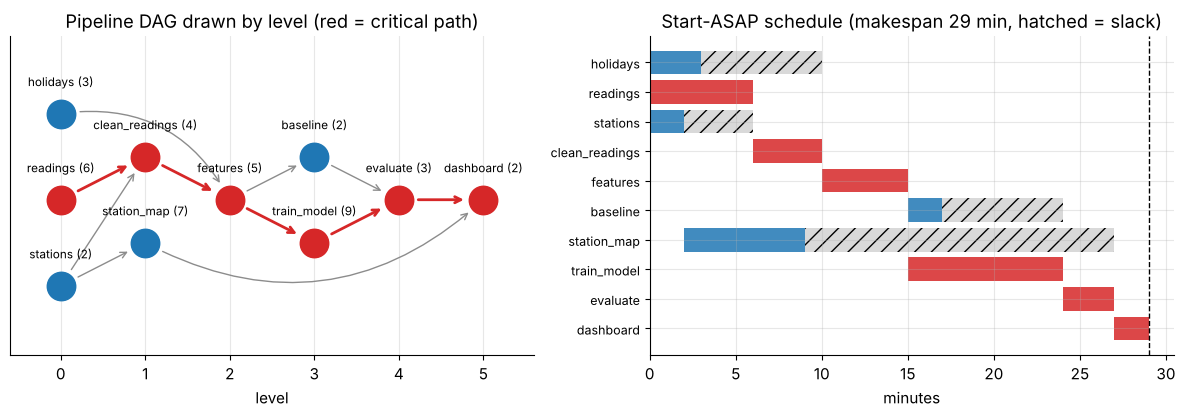

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
pos = {}
for lvl, group in sched.groupby("level"):
    for i, v in enumerate(group.index):
        pos[v] = (lvl, -(i - (len(group) - 1) / 2))
on_cp = set(cp)
for v, ups in deps.items():
    for u in ups:
        critical_edge = u in on_cp and v in on_cp and cp.index(v) == cp.index(u) + 1
        skips_levels = pos[v][0] - pos[u][0] > 1          # curve long edges so they avoid nodes
        rad = (-0.35 if pos[v][1] <= pos[u][1] else 0.35) if skips_levels else 0.0
        ax1.annotate("", xy=pos[v], xytext=pos[u],
                     arrowprops=dict(arrowstyle="->", lw=2 if critical_edge else 1,
                                     color="tab:red" if critical_edge else "0.55",
                                     shrinkA=14, shrinkB=14, connectionstyle=f"arc3,rad={rad}"))
for v, (x, y) in pos.items():
    ax1.scatter(x, y, s=420, color="tab:red" if v in on_cp else "tab:blue", zorder=3)
    ax1.text(x, y + 0.32, f"{v} ({duration[v]})", ha="center", fontsize=8.5)
ax1.set_title("Pipeline DAG drawn by level (red = critical path)")
ax1.set_xlabel("level"); ax1.set_yticks([]); ax1.set_ylim(-1.8, 1.9); ax1.set_xlim(-0.6, 5.6)

for i, v in enumerate(sched.index):
    ax2.barh(i, sched.loc[v, "duration"], left=sched.loc[v, "ES"],
             color="tab:red" if v in on_cp else "tab:blue", alpha=0.85)
    if sched.loc[v, "slack"] > 0:
        ax2.barh(i, sched.loc[v, "slack"], left=sched.loc[v, "EF"], color="0.85", hatch="//")
ax2.set_yticks(range(len(sched))); ax2.set_yticklabels(sched.index, fontsize=9)
ax2.invert_yaxis(); ax2.axvline(makespan, color="k", ls="--", lw=1)
ax2.set_xlabel("minutes"); ax2.set_title(f"Start-ASAP schedule (makespan {makespan} min, hatched = slack)")
plt.tight_layout()
plt.show()

### 2.5 Experiment: what if workers are limited?

Real orchestrators run a bounded number of steps at once (a laptop has a few cores, and a cluster has a
budget). With $k$ workers no schedule can beat

$$
\text{makespan} \;\ge\; \max\!\Big(\underbrace{L_{\text{crit}}}_{\text{critical path}},\;
\Big\lceil \tfrac{W}{k} \Big\rceil\Big), \qquad W = \sum_v d(v) \;(\text{total work}),
$$

because the critical path is sequential and $k$ workers can do at most $k$ minutes of work per minute.
Finding the optimal schedule for $k \ge 2$ workers is NP-hard in general, so real systems use
**list scheduling**: whenever a worker is free, give it the ready node with the highest priority.
A strong priority is the node's *bottom level*, the longest duration-weighted path from the node to
the end, so that nodes feeding the critical path go first. (Graham's classic result: *any* list
schedule is within a factor $2 - 1/k$ of optimal.) We vary one thing, the number of workers $k$.

In [9]:
def list_schedule(deps, duration, k: int):
    """Simulate k workers; a free worker takes the ready node with the longest path to the end."""
    kids = children_of(deps)
    bottom = {}
    for v in reversed(kahn_toposort(deps)):
        bottom[v] = duration[v] + max((bottom[w] for w in kids[v]), default=0)
    indeg = {v: len(ups) for v, ups in deps.items()}
    ready = [(-bottom[v], v) for v in deps if indeg[v] == 0]
    heapq.heapify(ready)
    running, t, finish = [], 0, {}                    # running = heap of (finish_time, node)
    while ready or running:
        while ready and len(running) < k:             # fill free workers
            _, v = heapq.heappop(ready)
            heapq.heappush(running, (t + duration[v], v))
        t, v = heapq.heappop(running)                 # jump to the next completion
        finish[v] = t
        for w in kids[v]:
            indeg[w] -= 1
            if indeg[w] == 0:
                heapq.heappush(ready, (-bottom[w], w))
    return max(finish.values())


W, L = sum(duration.values()), makespan
rows = [{"workers k": k, "list-schedule makespan": list_schedule(deps, duration, k),
         "lower bound max(L, ceil(W/k))": max(L, math.ceil(W / k))} for k in (1, 2, 3, 4)]
pd.DataFrame(rows).set_index("workers k")

,list-schedule makespan,"lower bound max(L, ceil(W/k))"
workers k,,
1,43,43
2,29,29
3,29,29
4,29,29


With one worker the makespan is the total work, 43 minutes. Already with **two** workers list
scheduling reaches the critical-path bound of 29 minutes, so a third or fourth worker buys nothing:
this pipeline is limited by its critical path, not by hardware. That is the practical lesson
behind the theory: before buying more workers, look at the critical path.

> **Olympiad tip.** Many contest problems are DAG problems in disguise: course prerequisites
> (topological sort), "minimum number of semesters" (levels), "minimum total time with unlimited
> parallelism" (longest path in a DAG via DP in topological order), "lexicographically smallest
> order" (Kahn with a min-heap), "is the order unique?" (Kahn's ready set never holds 2 nodes).
> The longest-path problem is NP-hard on general graphs but linear-time on DAGs, precisely because
> a topological order lets you process each node after all its predecessors.

**Quick check 2.** In Kahn's algorithm, what does it mean if the ready set always contains exactly
one node?

<details>
<summary>Answer</summary>

The topological order is **unique**: at every step there was no choice. Equivalently the DAG
contains a Hamiltonian path (a chain through all nodes), e.g. `a → b → c → d`. Such a pipeline has
no parallelism at all: its critical path equals its total work.
</details>

### ✏️ Exercise 1: Kahn's algorithm with a plain queue

Implement `topo_sort(deps)` for a graph given as `node -> list of upstream nodes`. Return **any**
valid topological order (a list containing every node once). If the graph has a cycle, raise
`ValueError`. Use a `collections.deque` as the ready queue (no heap needed). Watch out for nodes
that have no parents *and* no children: they must still appear in the order.

In [10]:
# ✏️ Exercise 1: Kahn's topological sort
def topo_sort(deps: dict[str, list[str]]) -> list[str]:
    """Return a valid topological order of `deps` (node -> upstream list); ValueError on a cycle."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex1():
    out = topo_sort(deps)
    assert sorted(out) == sorted(deps), "every node must appear exactly once"
    assert is_valid_order(out, deps), f"not a valid order: {out}"
    lonely = {"a": [], "b": ["a"], "solo": []}
    assert sorted(topo_sort(lonely)) == ["a", "b", "solo"], "isolated nodes must be included"
    for trial in range(20):                               # random DAGs: edges only go "forward"
        r = np.random.default_rng(trial)
        names = [f"n{i}" for i in range(8)]
        g = {n: [names[j] for j in range(i) if r.random() < 0.35] for i, n in enumerate(names)}
        assert is_valid_order(topo_sort(g), g), f"random DAG {trial} failed"
    try:
        topo_sort({"x": ["z"], "y": ["x"], "z": ["y"]})
    except ValueError:
        pass
    else:
        raise AssertionError("a cyclic graph must raise ValueError")


run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def topo_sort(deps):
    kids = {n: [] for n in deps}
    for v, ups in deps.items():
        for u in ups:
            kids[u].append(v)
    indeg = {v: len(ups) for v, ups in deps.items()}
    queue = deque(v for v in deps if indeg[v] == 0)
    order = []
    while queue:
        u = queue.popleft()
        order.append(u)
        for v in kids[u]:
            indeg[v] -= 1
            if indeg[v] == 0:
                queue.append(v)
    if len(order) != len(deps):
        raise ValueError("cycle detected")
    return order
```
Every node starts in the queue exactly when its in-degree reaches 0, and a cycle shows up as
nodes whose in-degree never reaches 0, so `order` ends up shorter than the node count.
</details>

### ✏️ Exercise 2: return a cycle, not just "there is one"

Implement `first_cycle(deps)`: return a list `[v0, v1, ..., vk]` with `vk == v0` such that each
`v_{i+1}` is an **upstream** node of `v_i` (i.e. `v_{i+1} in deps[v_i]`), or `None` if the graph is
acyclic. A self-loop `{"a": ["a"]}` is a cycle `["a", "a"]`. You may write it recursively
(graphs in the test are small). Hint: three colors.

In [11]:
# ✏️ Exercise 2: cycle detection with DFS
def first_cycle(deps: dict[str, list[str]]) -> list[str] | None:
    """Return one cycle [v0, ..., v0] following upstream arrows, or None if the graph is a DAG."""
    # YOUR CODE HERE
    raise NotImplementedError


def _is_cycle(c, g):
    return (c is not None and len(c) >= 2 and c[0] == c[-1]
            and all(c[i + 1] in g[c[i]] for i in range(len(c) - 1)))


def _test_ex2():
    assert first_cycle(deps) is None, "the pipeline is a DAG"
    diamond = {"a": [], "b": ["a"], "c": ["a"], "d": ["b", "c"]}
    assert first_cycle(diamond) is None, "a diamond is NOT a cycle (visited twice is fine)"
    assert _is_cycle(first_cycle({"a": ["a"]}), {"a": ["a"]}), "self-loop must be reported"
    g = {**deps, "holidays": ["dashboard"]}
    assert _is_cycle(first_cycle(g), g), f"bad cycle: {first_cycle(g)}"
    g2 = {"p": [], "q": ["p", "s"], "r": ["q"], "s": ["r"], "t": ["s"]}
    c2 = first_cycle(g2)
    assert _is_cycle(c2, g2) and set(c2) == {"q", "r", "s"}, f"expected the q-r-s cycle, got {c2}"


run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def first_cycle(deps):
    color = {n: 0 for n in deps}          # 0 white, 1 gray (on path), 2 black (done)
    path = []

    def visit(v):
        color[v] = 1
        path.append(v)
        for u in deps[v]:
            if color[u] == 1:              # back edge: u is on the current path
                return path[path.index(u):] + [u]
            if color[u] == 0:
                found = visit(u)
                if found:
                    return found
        path.pop()
        color[v] = 2
        return None

    for v in deps:
        if color[v] == 0:
            found = visit(v)
            if found:
                return found
    return None
```
A gray node is on the current recursion path, so reaching one again closes a loop, and the slice of
`path` from that node onward is exactly the cycle.
</details>

## 3. A mini asset orchestrator from scratch

The fastest way to understand a framework is to build a toy version of it. In this section we write
a small **asset orchestrator** (about 200 lines) with the features that matter most in Dagster:

| Feature | Our toy | Dagster |
|---|---|---|
| declare an asset | `@orch.asset` decorator that registers a function | `@dg.asset` |
| dependencies | inferred from **parameter names** with `inspect.signature` | same idea (parameter names), or `deps=[...]` |
| execution order | Kahn's topological sort | the run's execution plan |
| storing outputs | a dictionary keyed by `(asset, partition)` | an **I/O manager** |
| history | an **event log** in SQLite | the event log in Dagster's storage |
| flaky steps | retries with exponential backoff | `RetryPolicy` |
| "is it up to date?" | data versions + code versions → missing / stale / fresh | the same concepts, shown in the UI |
| time slices | daily partitions + backfill | `DailyPartitionsDefinition`, backfills |
| quality gates | blocking checks | `@dg.asset_check(blocking=True)` |
| clock triggers | a cron evaluator | `ScheduleDefinition` |
| event triggers | a polling sensor with a cursor and run keys | `@dg.sensor`, `RunRequest(run_key=...)` |

### 3.1 Versions: how do we know something changed?

We fingerprint two things with a hash function (SHA-256, shortened to 10 hex digits for display):

* the **code version** of an asset: a hash of the function's source code.
* the **data version** of a materialization: a hash of the value it produced.

Every time we materialize an asset we record its code version, its data version, **and the data
versions of the inputs it consumed**. Then the status of an asset is:

| Status | Rule |
|---|---|
| **missing** | it was never materialized |
| **stale (code)** | its current code version differs from the one recorded at the last materialization |
| **stale (upstream data)** | some input's *latest* data version differs from the version that was consumed |
| **fresh** | none of the above |

> **Intuition.** This is exactly how `make`, Bazel and other build systems decide what to rebuild,
> except that `make` uses file timestamps while we use content hashes. Hashes are stronger: if an
> upstream step re-runs but produces **identical** output, its data version does not change, so
> nothing downstream needs to re-run. Build-system people call this *early cutoff*.

In [12]:
def data_version(value) -> str:
    """Content hash of a value (DataFrames hashed row by row, everything else via sorted JSON)."""
    h = hashlib.sha256()
    if isinstance(value, pd.DataFrame):
        h.update(",".join(map(str, value.columns)).encode())
        h.update(pd.util.hash_pandas_object(value, index=False).values.tobytes())
    else:
        h.update(json.dumps(value, sort_keys=True, default=str).encode())
    return h.hexdigest()[:10]


def code_version(fn) -> str:
    """Hash of a function's source text (falls back to its bytecode if the source is unavailable)."""
    try:
        src = inspect.getsource(fn)
    except (OSError, TypeError):
        src = repr(fn.__code__.co_code) + repr(fn.__code__.co_consts)
    return hashlib.sha256(src.encode()).hexdigest()[:10]


print(data_version([1, 2, 3]), data_version([1, 2, 3]), data_version([1, 2, 4]))
print(data_version({"b": 1, "a": 2}) == data_version({"a": 2, "b": 1}), "(key order does not matter)")

a36b1f2c3f a36b1f2c3f df8fbe4237
True (key order does not matter)


### 3.2 The registry: assets, dependencies from parameter names, checks

`@orch.asset` reads the function's parameter names with `inspect.signature`: a parameter called
`clean_scores` means "this asset needs the asset `clean_scores`". The special parameter name
`partition` is not a dependency: it receives the partition key (section 3.6).

The event log is a SQLite table with one row per event. SQLite is a real database in a single
file, so the history survives a crash of the orchestrator, and we can query it with SQL.

In [13]:
class AssetRegistry:
    """Stores asset and check definitions; knows the dependency graph."""

    def __init__(self):
        self.assets: dict[str, dict] = {}
        self.checks: dict[str, list[dict]] = defaultdict(list)

    def asset(self, fn=None, *, retries: int = 0):
        """Decorator: register `fn` as an asset; its parameter names are its upstream assets."""
        def register(f):
            params = list(inspect.signature(f).parameters)
            self.assets[f.__name__] = {
                "fn": f, "retries": retries, "partitioned": "partition" in params,
                "deps": [p for p in params if p != "partition"],
                "code_version": code_version(f),
            }
            return f
        return register(fn) if fn is not None else register

    def check(self, asset_name: str, blocking: bool = True):
        """Decorator: register a data-quality check `fn(value) -> bool` for an asset."""
        def register(f):
            self.checks[asset_name] = [c for c in self.checks[asset_name] if c["name"] != f.__name__]
            self.checks[asset_name].append({"name": f.__name__, "fn": f, "blocking": blocking})
            return f
        return register

    def deps(self) -> dict[str, list[str]]:
        return {name: a["deps"] for name, a in self.assets.items()}

    def plan(self, selection=None) -> list[str]:
        """Topological order of the selected assets (default: all)."""
        order = kahn_toposort(self.deps())
        return [a for a in order if selection is None or a in selection]


class EventLog:
    """Append-only event log stored in SQLite."""

    def __init__(self, path):
        self.db = sqlite3.connect(str(path))
        self.db.execute("""CREATE TABLE IF NOT EXISTS events (
            id INTEGER PRIMARY KEY, run_id TEXT, ts REAL, kind TEXT, asset TEXT,
            partition TEXT, detail TEXT)""")

    def log(self, run_id, kind, asset=None, partition=None, **detail):
        self.db.execute("INSERT INTO events (run_id, ts, kind, asset, partition, detail) "
                        "VALUES (?, ?, ?, ?, ?, ?)",
                        (run_id, time.time(), kind, asset, partition, json.dumps(detail)))
        self.db.commit()

    def latest(self, asset, partition=None):
        """Detail dict of the latest MATERIALIZATION of (asset, partition), or None."""
        row = self.db.execute(
            "SELECT detail FROM events WHERE kind = 'MATERIALIZATION' AND asset = ? "
            "AND partition IS ? ORDER BY id DESC LIMIT 1", (asset, partition)).fetchone()
        return json.loads(row[0]) if row else None

    def events(self, run_id=None) -> pd.DataFrame:
        q = "SELECT id, run_id, kind, asset, partition, detail FROM events"
        args = ()
        if run_id:
            q, args = q + " WHERE run_id = ?", (run_id,)
        return pd.read_sql_query(q + " ORDER BY id", self.db, params=args)

### 3.3 The runner: statuses, retries with backoff, checks, minimal re-runs

`materialize()` walks the selected assets in topological order. For every asset it:

1. **skips** it if an upstream asset failed or a blocking check upstream failed.
2. if `only_stale=True`, skips it when it is already **fresh** (the status is recomputed *at that
   moment*, after its parents have possibly re-run, and that is what makes early cutoff work).
3. calls the function with its inputs loaded from the store, **retrying** on exceptions with
   exponential backoff: attempt $j$ waits $b \cdot 2^{j}$ seconds (plus a little random *jitter*, so
   that many clients failing together do not all retry at the same instant).
4. stores the value, logs a `MATERIALIZATION` event with code version, data version and input
   versions.
5. runs the asset's checks, and a failing **blocking** check stops everything downstream.

In [14]:
class MiniOrchestrator(AssetRegistry, EventLog):
    def __init__(self, db_path, backoff_base: float = 0.01):
        AssetRegistry.__init__(self)
        EventLog.__init__(self, db_path)
        self.store = {}                       # (asset, partition) -> value   ("I/O manager")
        self.backoff_base = backoff_base      # seconds; tiny so the notebook stays fast
        self.launched_run_keys = set()        # used by sensors (section 3.8)

    def status(self, name, partition=None) -> str:
        part = partition if self.assets[name]["partitioned"] else None
        rec = self.latest(name, part)
        if rec is None:
            return "missing"
        if rec["code_version"] != self.assets[name]["code_version"]:
            return "stale (code)"
        for dep in self.assets[name]["deps"]:
            dep_part = partition if self.assets[dep]["partitioned"] else None
            dep_rec = self.latest(dep, dep_part)
            if dep_rec is None or dep_rec["data_version"] != rec["inputs"].get(dep):
                return "stale (upstream data)"
        return "fresh"

    def statuses(self, partition=None) -> dict:
        return {a: self.status(a, partition) for a in self.plan()}

    def _call_with_retries(self, run_id, name, kwargs, part):
        spec = self.assets[name]
        for attempt in range(spec["retries"] + 1):
            try:
                return spec["fn"](**kwargs)
            except Exception as err:            # noqa: BLE001 - we log any failure
                if attempt == spec["retries"]:
                    raise
                delay = self.backoff_base * 2 ** attempt * (1 + 0.1 * random.random())
                self.log(run_id, "STEP_RETRY", name, part, attempt=attempt + 1,
                         error=f"{type(err).__name__}: {err}", wait_s=round(delay, 4))
                time.sleep(delay)

    def materialize(self, selection=None, partition=None, only_stale=False, run_id=None) -> dict:
        run_id = run_id or f"run-{len(self.events()['run_id'].unique()) + 1:03d}"
        self.log(run_id, "RUN_START", partition=partition, selection=selection)
        blocked, outcome = set(), {}
        for name in self.plan(selection):
            spec = self.assets[name]
            part = partition if spec["partitioned"] else None
            if any(d in blocked for d in spec["deps"]):
                blocked.add(name); outcome[name] = "skipped (upstream problem)"
                self.log(run_id, "STEP_SKIPPED", name, part)
                continue
            if only_stale and self.status(name, partition) == "fresh":
                outcome[name] = "fresh, not re-run"
                continue
            kwargs = {d: self.store[(d, partition if self.assets[d]["partitioned"] else None)]
                      for d in spec["deps"]}
            if spec["partitioned"]:
                kwargs["partition"] = partition
            self.log(run_id, "STEP_START", name, part)
            try:
                value = self._call_with_retries(run_id, name, kwargs, part)
            except Exception as err:            # noqa: BLE001
                self.log(run_id, "STEP_FAILURE", name, part, error=str(err))
                blocked.add(name); outcome[name] = "FAILED"
                continue
            self.store[(name, part)] = value
            inputs = {d: self.latest(d, partition if self.assets[d]["partitioned"] else None)
                      ["data_version"] for d in spec["deps"]}
            self.log(run_id, "MATERIALIZATION", name, part, code_version=spec["code_version"],
                     data_version=data_version(value), inputs=inputs)
            outcome[name] = "materialized"
            for chk in self.checks.get(name, []):
                passed = bool(chk["fn"](value))
                self.log(run_id, "CHECK_PASSED" if passed else "CHECK_FAILED", name, part,
                         check=chk["name"], blocking=chk["blocking"])
                if not passed and chk["blocking"]:
                    blocked.add(name); outcome[name] = f"materialized, check '{chk['name']}' FAILED"
        ok = not blocked
        self.log(run_id, "RUN_SUCCESS" if ok else "RUN_FAILURE", partition=partition)
        return outcome

### 3.4 First run: dependencies, retries and the event log

Our toy pipeline processes quiz scores of a small study group. The "score server" is flaky: it
times out twice before answering, so `raw_scores` gets `retries=3`. The raw data also contains two
impossible scores (−5 and 104) that the cleaning step must drop, and a blocking check makes sure the
cleaned table is never empty.

In [15]:
orch = MiniOrchestrator(WORK / "mini_events.sqlite")
SERVER = {"timeouts_left": 2,
          "rows": [["ana", 81], ["ben", -5], ["chloe", 93], ["dev", 77], ["emil", 104], ["fay", 88]]}


@orch.asset(retries=3)
def raw_scores():
    if SERVER["timeouts_left"] > 0:
        SERVER["timeouts_left"] -= 1
        raise TimeoutError("score server did not answer")
    return [list(r) for r in SERVER["rows"]]


@orch.asset
def clean_scores(raw_scores):
    return [[name, s] for name, s in raw_scores if 0 <= s <= 100]


@orch.asset
def class_average(clean_scores):
    return round(sum(s for _, s in clean_scores) / len(clean_scores), 2)


@orch.asset
def leaderboard(clean_scores):
    return sorted(clean_scores, key=lambda row: -row[1])[:3]


@orch.check("clean_scores", blocking=True)
def scores_not_empty(value):
    return len(value) > 0


print("inferred dependencies:", orch.deps())
print("execution plan       :", orch.plan())
print("status before        :", orch.statuses())
outcome = orch.materialize()
print("outcome              :", outcome)
print("values               :", orch.store[("class_average", None)], orch.store[("leaderboard", None)])
orch.events("run-001")[["kind", "asset", "detail"]]

inferred dependencies: {'raw_scores': [], 'clean_scores': ['raw_scores'], 'class_average': ['clean_scores'], 'leaderboard': ['clean_scores']}
execution plan       : ['raw_scores', 'clean_scores', 'class_average', 'leaderboard']
status before        : {'raw_scores': 'missing', 'clean_scores': 'missing', 'class_average': 'missing', 'leaderboard': 'missing'}


outcome              : {'raw_scores': 'materialized', 'clean_scores': 'materialized', 'class_average': 'materialized', 'leaderboard': 'materialized'}
values               : 84.75 [['chloe', 93], ['fay', 88], ['ana', 81]]


,kind,asset,detail
0,RUN_START,None,"{""selection"": null}"
1,STEP_START,raw_scores,{}
2,STEP_RETRY,raw_scores,"{""attempt"": 1, ""error"": ""TimeoutErro..."
3,STEP_RETRY,raw_scores,"{""attempt"": 2, ""error"": ""TimeoutErro..."
4,MATERIALIZATION,raw_scores,"{""code_version"": ""44611d161c"", ""data..."
5,STEP_START,clean_scores,{}
6,MATERIALIZATION,clean_scores,"{""code_version"": ""7e4c10eaff"", ""data..."
7,CHECK_PASSED,clean_scores,"{""check"": ""scores_not_empty"", ""block..."
8,STEP_START,class_average,{}
9,MATERIALIZATION,class_average,"{""code_version"": ""be7b53cd2d"", ""data..."


The event log tells the full story of `run-001`: two `STEP_RETRY` events for `raw_scores` (with the
error message and the waiting time, which roughly doubles from attempt 1 to attempt 2, and the small
deviation from an exact factor of 2 is the random jitter), then one `MATERIALIZATION` per asset
carrying the code version, the data version and the input versions, and a `CHECK_PASSED` event.
The class average is 84.75: the four valid scores 81, 93, 77 and 88 sum to 339, and 339 / 4 = 84.75.

**Why jitter? An experiment.** Imagine a feed server that restarts and drops 200 clients at the same
moment. Every client retries with exponential backoff (waits of 1, 2, 4, 8 seconds), and in the
worst case the server stays down for a while, so all four retries happen. Without jitter, all 200
clients retry at *exactly* the same instants, hitting the recovering server with 200 requests at
once, again and again (the "thundering herd"). With **full jitter**, each wait is drawn uniformly
from $[0, b \cdot 2^{j}]$ instead, which spreads the same requests out in time. We vary only the jitter.

no jitter   : peak load = 200 requests in one 0.25 s bucket
full jitter : peak load =  72 requests in one 0.25 s bucket


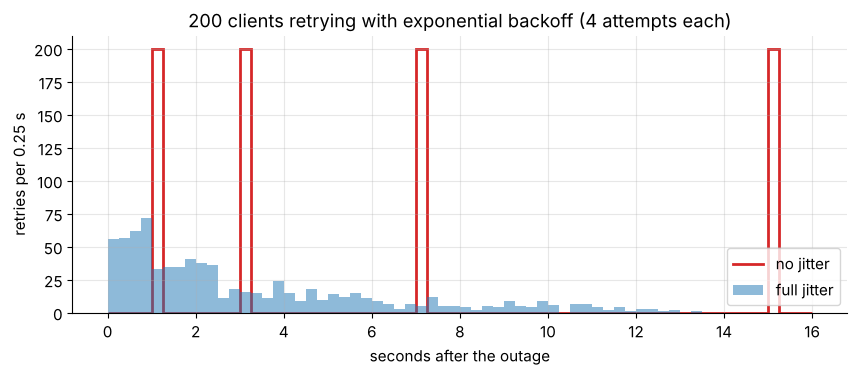

In [16]:
def retry_times(n_clients: int, n_retries: int, base: float, jitter: bool, rng) -> np.ndarray:
    """Times at which clients retry if every attempt fails (exponential backoff, optional jitter)."""
    caps = base * 2.0 ** np.arange(n_retries)                       # 1, 2, 4, 8 seconds
    waits = rng.uniform(0, caps, size=(n_clients, n_retries)) if jitter else np.tile(caps, (n_clients, 1))
    return np.cumsum(waits, axis=1).ravel()


sim_rng = np.random.default_rng(SEED)
bins = np.arange(0, 16.25, 0.25)                                   # 0.25-second buckets
fig, ax = plt.subplots(figsize=(10, 3.6))
for jitter, color in [(False, "tab:red"), (True, "tab:blue")]:
    t = retry_times(200, 4, 1.0, jitter, sim_rng)
    counts, _ = np.histogram(t, bins=bins)
    label = "full jitter" if jitter else "no jitter"
    ax.stairs(counts, bins, color=color, fill=jitter, alpha=0.5 if jitter else 1.0, lw=2, label=label)
    print(f"{label:12}: peak load = {counts.max():3d} requests in one 0.25 s bucket")
ax.set_xlabel("seconds after the outage"); ax.set_ylabel("retries per 0.25 s")
ax.set_title("200 clients retrying with exponential backoff (4 attempts each)")
ax.legend()
plt.show()

Same number of requests (800) in both cases, very different peaks: without jitter the server sees
four spikes of 200 simultaneous requests (at 1, 3, 7 and 15 seconds, the running sums of the waits).
With full jitter the same requests are spread out and the worst 0.25-second bucket holds 72 of them,
almost three times fewer. This is why production retry policies (Dagster's `RetryPolicy(jitter=...)`
included) add randomness to backoff.

### 3.5 Missing, stale, fresh, and minimal re-runs

Now the interesting part. We run four scenarios and after each one ask the orchestrator for the
statuses and for a **minimal re-run** (`only_stale=True`).

In [17]:
def scenario(title):
    """Print the statuses, re-run only what is stale, and print what happened."""
    before = orch.statuses()
    out = orch.materialize(only_stale=True)
    ran = [a for a, o in out.items() if o.startswith("materialized")]
    print(f"--- {title}")
    print("    statuses before:", {a: s for a, s in before.items() if s != "fresh"} or "all fresh")
    print("    re-ran         :", ran or "nothing")


scenario("A. nothing changed")


@orch.asset                       # B. new logic: one decimal instead of two -> new code version
def class_average(clean_scores):
    return round(sum(s for _, s in clean_scores) / len(clean_scores), 1)


scenario("B. class_average code changed")




@orch.asset                       # C. a pure refactor: different code, identical output
def clean_scores(raw_scores):
    def is_valid(score):
        return 0 <= score <= 100
    return [[name, s] for name, s in raw_scores if is_valid(s)]


scenario("C. clean_scores refactored (same output)")

SERVER["rows"].append(["gus", 95])            # D. new upstream data arrives ...
orch.materialize(selection=["raw_scores"])     # ... and a scheduled run re-fetches the raw data
scenario("D. raw_scores re-fetched with a new row")
print("    new average and leaderboard:", orch.store[("class_average", None)],
      orch.store[("leaderboard", None)])

--- A. nothing changed
    statuses before: all fresh
    re-ran         : nothing
--- B. class_average code changed
    statuses before: {'class_average': 'stale (code)'}
    re-ran         : ['class_average']


--- C. clean_scores refactored (same output)
    statuses before: {'clean_scores': 'stale (code)'}
    re-ran         : ['clean_scores']


--- D. raw_scores re-fetched with a new row
    statuses before: {'clean_scores': 'stale (upstream data)'}
    re-ran         : ['clean_scores', 'class_average', 'leaderboard']
    new average and leaderboard: 86.8 [['gus', 95], ['chloe', 93], ['fay', 88]]


Let's read the four results carefully, because they contain the whole idea of asset-based
orchestration:

* **A.** Nothing changed, so nothing ran. A plain "run everything" scheduler would have redone all
  four steps.
* **B.** Only `class_average` changed its code, so only `class_average` re-ran. Its parents were
  fresh, and it has no children.
* **C.** `clean_scores` got a new code version, so it re-ran. But its output was **identical**, so
  its data version did not change, and `class_average` and `leaderboard` stayed fresh. Only one step
  ran instead of three: early cutoff in action.
* **D.** The raw data changed. The orchestrator cannot know that by itself (it does not watch the
  score server), and it found out because a run re-fetched `raw_scores` and the data version changed.
  Before the re-run only `clean_scores` was stale, because only its *direct* input had changed.
  Once it re-ran and produced a new data version, its children became stale in turn, so the
  minimal re-run cascaded through exactly the three downstream assets. The new average is
  (339 + 95) / 5 = 86.8.

> **Common pitfall.** Hashing the *source text* means a changed comment or blank line also counts
> as a code change, and a change inside a helper function that the asset calls is **not** detected.
> That is why Dagster does not hash your source automatically: you set `code_version="v2"` yourself
> when the logic changes. Explicit versions are less magical but more honest.

What about bad data? Suppose the score server returns only impossible values. The blocking check on
`clean_scores` fails, and the orchestrator refuses to compute an average of nothing.

In [18]:
saved_rows = SERVER["rows"]
SERVER["rows"] = [["hal", -1], ["ivy", 140]]
print(orch.materialize())
SERVER["rows"] = saved_rows                       # restore the good data
print(orch.materialize())
last_runs = orch.events()
last_runs[last_runs["run_id"].isin(last_runs["run_id"].unique()[-2:]) & last_runs["kind"].str.contains("RUN_|CHECK")][
    ["run_id", "kind", "asset", "detail"]]

{'raw_scores': 'materialized', 'clean_scores': "materialized, check 'scores_not_empty' FAILED", 'class_average': 'skipped (upstream problem)', 'leaderboard': 'skipped (upstream problem)'}


{'raw_scores': 'materialized', 'clean_scores': 'materialized', 'class_average': 'materialized', 'leaderboard': 'materialized'}


,run_id,kind,asset,detail
37,run-007,RUN_START,None,"{""selection"": null}"
42,run-007,CHECK_FAILED,clean_scores,"{""check"": ""scores_not_empty"", ""block..."
45,run-007,RUN_FAILURE,None,{}
46,run-008,RUN_START,None,"{""selection"": null}"
51,run-008,CHECK_PASSED,clean_scores,"{""check"": ""scores_not_empty"", ""block..."
56,run-008,RUN_SUCCESS,None,{}


The failing run stored the empty `clean_scores` (a check runs *after* its asset is materialized, and
Dagster behaves the same way), but `class_average` and `leaderboard` were skipped, so the
downstream tables still hold the last good values, and the run is marked `RUN_FAILURE`, which in a
real system pages a human. The next run with good data repairs everything.

### 3.6 Daily partitions and backfills

Many datasets grow by time slices: one file per day, one table partition per hour. Re-processing the
whole history every time would be wasteful, so we **partition** an asset: each partition (here, each
calendar day) is materialized and versioned independently. A **backfill** is a run (or a series of
runs) over a *range* of partitions, typically to fill history or to apply new logic to the past.

In our toy, an asset becomes partitioned by having a parameter named `partition`, and a partitioned
asset that depends on another partitioned asset reads **the same partition** (an *identity*
partition mapping).

In [19]:
def daily_keys(start: str, end: str) -> list[str]:
    """All dates from start to end inclusive, as 'YYYY-MM-DD' strings."""
    d0, d1 = dt.date.fromisoformat(start), dt.date.fromisoformat(end)
    return [(d0 + dt.timedelta(days=i)).isoformat() for i in range((d1 - d0).days + 1)]


@orch.asset
def daily_visits(partition):
    """Fake page visits for one day, deterministic in the date."""
    day = dt.date.fromisoformat(partition)
    seed = int(hashlib.sha256(partition.encode()).hexdigest()[:8], 16)
    return 1000 + seed % 400 - (300 if day.weekday() >= 5 else 0)


@orch.asset
def daily_report(daily_visits, partition):
    return f"{partition}: {daily_visits} visits"


def backfill(orch, start, end, selection):
    """Materialize every stale or missing partition in [start, end]; return a summary table."""
    rows = []
    for key in daily_keys(start, end):
        out = orch.materialize(selection=selection, partition=key, only_stale=True,
                               run_id=f"backfill-{key}")
        rows.append({"partition": key, **out})
    return pd.DataFrame(rows).set_index("partition")


sel = ["daily_visits", "daily_report"]
print("first backfill, Sep 21-27:")
display(backfill(orch, "2026-09-21", "2026-09-27", sel))

first backfill, Sep 21-27:


,daily_visits,daily_report
partition,,
2026-09-21,materialized,materialized
2026-09-22,materialized,materialized
2026-09-23,materialized,materialized
2026-09-24,materialized,materialized
2026-09-25,materialized,materialized
2026-09-26,materialized,materialized
2026-09-27,materialized,materialized


In [20]:
print("second backfill, Sep 25-30 (overlaps the first one):")
display(backfill(orch, "2026-09-25", "2026-09-30", sel))
print(orch.store[("daily_report", "2026-09-27")], "| (2026-09-27 is a Sunday)")

second backfill, Sep 25-30 (overlaps the first one):


,daily_visits,daily_report
partition,,
2026-09-25,"fresh, not re-run","fresh, not re-run"
2026-09-26,"fresh, not re-run","fresh, not re-run"
2026-09-27,"fresh, not re-run","fresh, not re-run"
2026-09-28,materialized,materialized
2026-09-29,materialized,materialized
2026-09-30,materialized,materialized


2026-09-27: 945 visits | (2026-09-27 is a Sunday)


The overlapping days (25–27) were already fresh, so the second backfill only did new work for
Sep 28–30. This is why partitioning matters for cost: a daily pipeline that runs for three years
has more than a thousand partitions, and you want to recompute only the ones that need it.

> **Going deeper.** Real orchestrators also support **partition mappings** that are not identity:
> a daily asset that reads 24 hourly partitions, a weekly asset that reads seven daily ones, or a
> "rolling 7-day" asset that reads the last seven days. Dagster handles these with
> `TimeWindowPartitionMapping` (section 6).

### 3.7 A cron schedule evaluator

A **schedule** starts runs at fixed times. The standard language for "fixed times" is the
five-field **cron expression**:

```text
┌──────── minute        (0-59)
│ ┌────── hour          (0-23)
│ │ ┌──── day of month  (1-31)
│ │ │ ┌── month         (1-12)
│ │ │ │ ┌ day of week   (0-6, Sunday = 0; 7 also means Sunday)
│ │ │ │ │
0 */3 * * *      "at minute 0 of every third hour"  -> 00:00, 03:00, 06:00, ..., 21:00
30 6 * * 1-5     "06:30 on Monday to Friday"
0 9 1 * *        "09:00 on the first day of every month"
15 2 1,15 * *    "02:15 on the 1st and the 15th"
```

Each field is a comma-separated list of items. An item is `*` (all values), a number `5`, a range
`1-5`, optionally followed by a step `/k` (`*/15` = every 15th value starting at the lowest:
0, 15, 30, 45). One historical quirk: if **both** day-of-month and day-of-week are restricted, cron
fires when **either** matches (`0 9 1 * 1` = the 1st of the month *or* any Monday).

Crucially, a schedule needs a **time zone**: "every day at 09:00" in Toronto is 13:00 UTC in
summer (EDT, UTC−4) but 14:00 UTC in winter (EST, UTC−5). Our evaluator walks forward one minute at
a time **in UTC**, converts each instant to local wall-clock time, and tests the five fields. That is
simple and needs no special code for daylight saving time (DST) transitions. (Production
implementations jump field by field instead of minute by minute. On ordinary days they return the
same answers, but for local times that a DST change skips or repeats, each tool makes its own
choice, as section 7.1 shows.)

In [21]:
CRON_SPECS = [("minute", 0, 59), ("hour", 0, 23), ("day", 1, 31), ("month", 1, 12), ("weekday", 0, 7)]


def parse_cron_field(field: str, lo: int, hi: int) -> set[int]:
    """Expand one cron field ('*', '5', '1-5', '*/15', '0-30/10', '1,15') into a set of ints."""
    values = set()
    for item in field.split(","):
        base, _, step_txt = item.partition("/")
        step = int(step_txt) if step_txt else 1
        if base == "*":
            start, end = lo, hi
        elif "-" in base:
            start, end = map(int, base.split("-"))
        else:
            start = int(base)
            end = hi if step_txt else start          # '5/15' means 5, 20, 35, 50
        if not (lo <= start <= end <= hi) or step < 1:
            raise ValueError(f"bad cron item {item!r} for range {lo}-{hi}")
        values.update(range(start, end + 1, step))
    return values


def parse_cron(expr: str):
    fields = expr.split()
    if len(fields) != 5:
        raise ValueError("a cron expression has exactly 5 fields")
    sets = [parse_cron_field(f, lo, hi) for f, (_, lo, hi) in zip(fields, CRON_SPECS)]
    sets[4] = {v % 7 for v in sets[4]}               # 7 is another name for Sunday (0)
    return sets, fields[2] != "*", fields[4] != "*"


def cron_matches(local: dt.datetime, parsed) -> bool:
    (minutes, hours, days, months, weekdays), day_restricted, weekday_restricted = parsed
    if local.minute not in minutes or local.hour not in hours or local.month not in months:
        return False
    day_ok, weekday_ok = local.day in days, local.isoweekday() % 7 in weekdays
    if day_restricted and weekday_restricted:
        return day_ok or weekday_ok                  # the classic cron OR-quirk
    return day_ok and weekday_ok


def next_fire_times(expr: str, after: dt.datetime, n: int = 5, tz: ZoneInfo = TZ) -> list[dt.datetime]:
    """The next n instants strictly after `after` at which `expr` fires, in time zone tz."""
    parsed = parse_cron(expr)
    t = after.astimezone(dt.timezone.utc).replace(second=0, microsecond=0) + dt.timedelta(minutes=1)
    found = []
    for _ in range(60 * 24 * 366 * 2):               # give up after two years of minutes
        local = t.astimezone(tz)
        if cron_matches(local, parsed):
            found.append(local)
            if len(found) == n:
                break
        t += dt.timedelta(minutes=1)
    return found


def show_times(times):
    return [f"{t:%a %Y-%m-%d %H:%M %Z} ({t.astimezone(dt.timezone.utc):%H:%M} UTC)" for t in times]


start = dt.datetime(2026, 9, 30, 22, 10, tzinfo=TZ)
for expr in ["0 */3 * * *", "30 6 * * 1-5", "0 9 1 * *"]:
    print(f"{expr:14} ->", *show_times(next_fire_times(expr, start, n=3)), sep="\n    ")

0 */3 * * *    ->
    Thu 2026-10-01 00:00 EDT (04:00 UTC)
    Thu 2026-10-01 03:00 EDT (07:00 UTC)
    Thu 2026-10-01 06:00 EDT (10:00 UTC)
30 6 * * 1-5   ->
    Thu 2026-10-01 06:30 EDT (10:30 UTC)
    Fri 2026-10-02 06:30 EDT (10:30 UTC)
    Mon 2026-10-05 06:30 EDT (10:30 UTC)


0 9 1 * *      ->
    Thu 2026-10-01 09:00 EDT (13:00 UTC)
    Sun 2026-11-01 09:00 EST (14:00 UTC)
    Tue 2026-12-01 09:00 EST (14:00 UTC)


**DST check.** In 2026 Toronto turns its clocks back on Sunday, November 1, at 02:00 EDT
(the hour 01:00–01:59 happens twice). Watch "every three hours" across that night: the local
times are still 00:00, 03:00, 06:00, ..., but the **real** gap between 00:00 and 03:00 is four hours.

In [22]:
night = next_fire_times("0 */3 * * *", dt.datetime(2026, 10, 31, 20, 0, tzinfo=TZ), n=4)
print(*show_times(night), sep="\n")
UTC = dt.timezone.utc
naive_gaps = [(b - a).total_seconds() / 3600 for a, b in zip(night, night[1:])]
true_gaps = [(b.astimezone(UTC) - a.astimezone(UTC)).total_seconds() / 3600
             for a, b in zip(night, night[1:])]
print("gaps computed as b - a      :", naive_gaps)
print("gaps computed in UTC (true) :", true_gaps)

Sat 2026-10-31 21:00 EDT (01:00 UTC)
Sun 2026-11-01 00:00 EDT (04:00 UTC)
Sun 2026-11-01 03:00 EST (08:00 UTC)
Sun 2026-11-01 06:00 EST (11:00 UTC)
gaps computed as b - a      : [3.0, 3.0, 3.0]
gaps computed in UTC (true) : [3.0, 4.0, 3.0]


The two gap computations disagree, and the first one is wrong! When two aware datetimes share the
**same** `tzinfo` object, Python subtracts their **wall-clock** readings and ignores the UTC offset,
so it claims 3 hours across the night when 4 hours really pass between 00:00 EDT and 03:00 EST.
Converting both to UTC first gives the true elapsed time. This is a classic source of bugs in
scheduling code: do arithmetic on instants in UTC, and convert to local time only for display and
for matching calendar rules.

> **Common pitfall.** Daily jobs scheduled between 01:00 and 02:59 local time are dangerous: on the
> spring-forward day 02:00–02:59 does not exist, and on the fall-back day 01:00–01:59 occurs twice
> (these are Toronto's hours, and other regions switch at other times).
> Different tools resolve this differently (skip, run at 03:00, run twice, run once). Schedule
> daily jobs outside the 01:00–03:00 window, or schedule in UTC if local time does not matter.

### 3.8 A polling sensor with a cursor and run keys

A **sensor** is a small function the orchestrator calls repeatedly (every 30 seconds, say). Each call
is a **tick**. The sensor looks at the outside world (a folder, a bucket, an API) and either returns
**run requests** or a **skip reason** ("nothing new"). Two mechanisms keep it correct and cheap:

* The **cursor** is a small string the sensor saves between ticks, e.g. "I have already handled
  everything up to file `x` modified at time `t`". It makes each tick cheap (no re-processing of
  old files).
* The **run key** is a unique name for each requested run, e.g. `"file.json:1790000060"`. The
  orchestrator **never launches two runs with the same run key**, so even if the cursor is lost
  or a tick is evaluated twice, no file is processed twice. Cursor = efficiency, run key =
  idempotency.

Our cursor stores the pair `(mtime, name)` of the last processed file and compares pairs, not just
times. Why? Two files can share a modification time (coarse file-system clocks, bulk copies). With a
cursor that only stores the time and a strict `mtime > cursor` test, a file that lands *later* with
the *same* timestamp as an already-processed one would be skipped forever.

In [23]:
INBOX_MINI = WORK / "mini_inbox"
INBOX_MINI.mkdir(exist_ok=True)


def drop_file(folder: Path, name: str, lines: list[str], mtime: float) -> None:
    """Write a file and force its modification time (so the demo is reproducible)."""
    p = folder / name
    p.write_text("\n".join(lines) + "\n")
    os.utime(p, (mtime, mtime))


def inbox_sensor_tick(folder: Path, cursor: str | None):
    """One sensor tick: return (run_requests, new_cursor, skip_reason)."""
    last = tuple(json.loads(cursor)) if cursor else (0.0, "")
    new = sorted((p.stat().st_mtime, p.name) for p in folder.glob("*.txt"))
    new = [(m, n) for m, n in new if (m, n) > last]
    if not new:
        return [], cursor, "no new files"
    requests = [{"run_key": f"{n}:{m:.0f}", "partition": n} for m, n in new]
    return requests, json.dumps(list(new[-1])), None


@orch.asset
def inbox_line_count(partition):
    return len((INBOX_MINI / partition).read_text().splitlines())


def submit(orch, requests) -> list[str]:
    """Launch one run per request, except run keys that were already launched (dedup)."""
    launched = []
    for req in requests:
        if req["run_key"] in orch.launched_run_keys:
            continue
        orch.launched_run_keys.add(req["run_key"])
        orch.materialize(selection=["inbox_line_count"], partition=req["partition"],
                         run_id=f"sensor:{req['run_key']}")
        launched.append(req["run_key"])
    return launched


T0 = 1_790_000_000                                  # a fixed "now" (late September 2026)
log_rows, cursor = [], None


def tick(label):
    global cursor
    reqs, cursor, skip = inbox_sensor_tick(INBOX_MINI, cursor)
    launched = submit(orch, reqs)
    log_rows.append({"tick": label, "requested": [r["run_key"] for r in reqs], "launched": launched,
                     "skip_reason": skip, "cursor_after": cursor})


tick("1: empty inbox")
drop_file(INBOX_MINI, "batch_a.txt", ["x", "y", "z"], T0)
drop_file(INBOX_MINI, "batch_b.txt", ["x", "y"], T0 + 60)
tick("2: two files arrived")
tick("3: nothing new")
drop_file(INBOX_MINI, "batch_c.txt", ["x"], T0 + 60)          # same mtime as batch_b!
tick("4: file with a tied mtime")
cursor = None                                                  # simulate a lost cursor
tick("5: cursor lost -> rescan")
pd.DataFrame(log_rows).set_index("tick")

,requested,launched,skip_reason,cursor_after
tick,,,,
1: empty inbox,[],[],no new files,None
2: two files arrived,"[batch_a.txt:1790000000, batch_b.txt...","[batch_a.txt:1790000000, batch_b.txt...",None,"[1790000060.0, ""batch_b.txt""]"
3: nothing new,[],[],no new files,"[1790000060.0, ""batch_b.txt""]"
4: file with a tied mtime,[batch_c.txt:1790000060],[batch_c.txt:1790000060],None,"[1790000060.0, ""batch_c.txt""]"
5: cursor lost -> rescan,"[batch_a.txt:1790000000, batch_b.txt...",[],None,"[1790000060.0, ""batch_c.txt""]"


Follow the ticks:

1. An empty inbox gives a **skip reason** and no runs.
2. Two files: two run requests and two runs. The cursor now points at `batch_b.txt`.
3. Nothing new: skip.
4. `batch_c.txt` has the **same** modification time as `batch_b.txt` but sorts after it, so the
   pair comparison catches it. A time-only cursor would have missed it. The tie-break is not
   bullet-proof, though: a tied file whose name sorts *before* the cursor's (say, a `batch_0.txt`
   with that same timestamp that lands after tick 4) would still be skipped forever, and run keys
   cannot rescue a file that is never requested. Exercise 6 includes such a case, and its solution
   explains the fix: also remember the names already seen at the cursor's timestamp.
5. We wipe the cursor (as if the sensor's state were lost). The tick re-requests all three files,
   but all three run keys were already launched, so the orchestrator launches **nothing**. The
   run key turned a potential triple re-processing into a no-op.

In [24]:
print({p: orch.store[("inbox_line_count", p)] for p in ["batch_a.txt", "batch_b.txt", "batch_c.txt"]})
ev = orch.events()
print("runs launched by the sensor:", ev.loc[ev["run_id"].str.startswith("sensor:"), "run_id"].nunique())

{'batch_a.txt': 3, 'batch_b.txt': 2, 'batch_c.txt': 1}
runs launched by the sensor: 3


### 3.9 From the toy to Dagster

Every piece of our toy has a counterpart in Dagster, usually with a lot more care for scale,
concurrency and user interface:

| Toy (this section) | Dagster |
|---|---|
| `@orch.asset`, deps from parameter names | `@dg.asset`, where parameters name upstream assets, or `deps=[...]` for ordering-only dependencies |
| `orch.store` dictionary | **I/O managers** (`FilesystemIOManager`, `DuckDBPandasIOManager`, ...) |
| SQLite `events` table | the **event log** in Dagster's storage (SQLite locally, Postgres in production) |
| `retries=3` + exponential backoff | `retry_policy=dg.RetryPolicy(max_retries=3, delay=..., backoff=dg.Backoff.EXPONENTIAL, jitter=...)` |
| `code_version` hash, `data_version` hash | `@dg.asset(code_version="v2")`, data versions, and the UI shows **Unsynced** (stale) assets |
| `materialize(only_stale=True)` | "Materialize unsynced" in the UI, declarative automation |
| `partition` parameter, `backfill()` | `partitions_def=dg.DailyPartitionsDefinition(...)`, backfills over key ranges |
| `@orch.check(blocking=True)` | `@dg.asset_check(asset=..., blocking=True)` |
| `next_fire_times()` | `dg.ScheduleDefinition(cron_schedule=..., execution_timezone=...)` run by the **daemon** |
| `inbox_sensor_tick()`, cursor, `launched_run_keys` | `@dg.sensor`, `context.cursor`, `dg.RunRequest(run_key=...)`, `dg.SkipReason` |

What our toy lacks: parallel execution, run isolation (a crashing step kills our whole notebook),
a UI, multiple code locations, concurrency limits, alerting, and years of edge cases. That is what
the real framework is for, and it is what the rest of this notebook explores.

### ✏️ Exercise 3: which assets must re-run?

You are given a DAG (`deps`), the **current** code version of every asset (`code`) and the record of
each asset's last materialization (`records`, where a missing key means "never materialized"). A record
looks like `{"code_version": "v1", "data_version": "d7", "inputs": {"parent": "d3"}}`.

Return the set of assets that a re-run must recompute if we assume (pessimistically, no early
cutoff) that **every recomputed asset produces new data**: every asset that is missing, has a
changed code version, or consumed an input data version different from the input's latest data
version, **plus everything downstream of those**.

In [25]:
# ✏️ Exercise 3: stale assets
def rerun_set(deps: dict, code: dict, records: dict) -> set[str]:
    """Assets to recompute: not fresh themselves, or downstream of something recomputed."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex3():
    g = {"a": [], "b": ["a"], "c": ["b"], "d": ["a"], "e": ["c", "d"], "f": []}
    rec = {"a": {"code_version": "1", "data_version": "A1", "inputs": {}},
           "b": {"code_version": "1", "data_version": "B1", "inputs": {"a": "A1"}},
           "c": {"code_version": "1", "data_version": "C1", "inputs": {"b": "B1"}},
           "d": {"code_version": "1", "data_version": "D1", "inputs": {"a": "A1"}},
           "e": {"code_version": "1", "data_version": "E1", "inputs": {"c": "C1", "d": "D1"}},
           "f": {"code_version": "1", "data_version": "F1", "inputs": {}}}
    code = {k: "1" for k in g}
    assert rerun_set(g, code, rec) == set(), "everything is fresh"
    assert rerun_set(g, {**code, "c": "2"}, rec) == {"c", "e"}, "code change propagates downstream"
    rec2 = {**rec, "d": {**rec["d"], "data_version": "D2"}}
    assert rerun_set(g, code, rec2) == {"e"}, "e consumed an old version of d"
    rec3 = {k: v for k, v in rec.items() if k != "b"}
    assert rerun_set(g, code, rec3) == {"b", "c", "e"}, "missing b -> b and its descendants"
    assert rerun_set(g, {**code, "f": "9", "a": "2"}, rec) == {"a", "b", "c", "d", "e", "f"}


run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def rerun_set(deps, code, records):
    out = set()
    for v in kahn_toposort(deps):                # parents are decided before children
        rec = records.get(v)
        not_fresh = (
            rec is None
            or rec["code_version"] != code[v]
            or any(u not in records or records[u]["data_version"] != rec["inputs"].get(u)
                   for u in deps[v]))
        if not_fresh or any(u in out for u in deps[v]):
            out.add(v)
    return out
```
Processing nodes in topological order guarantees that when we look at `v`, we already know whether
any parent will be recomputed, so "downstream of something recomputed" is a single check.
</details>

### ✏️ Exercise 4: a faster cron evaluator

Walking minute by minute is simple but slow for monthly schedules (about 43,000 steps per month).
Write `next_fire_times_fast(expr, after, n)` that works with **naive local** datetimes (ignore
DST) and jumps **day by day**: for each candidate day check month and the day/weekday rule (remember
the OR-quirk), then emit that day's matching `(hour, minute)` pairs in increasing order, keeping only
times strictly after `after`. Use `parse_cron(expr)` from above.

In [26]:
# ✏️ Exercise 4: next cron fire times, day by day
def next_fire_times_fast(expr: str, after: dt.datetime, n: int = 5) -> list[dt.datetime]:
    """Next n naive local datetimes strictly after `after` matching the cron expression."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex4():
    after = dt.datetime(2026, 10, 2, 7, 45)
    exprs = ["0 */3 * * *", "30 6 * * 1-5", "*/20 8-9 * * *", "0 9 1 * 1", "15 2 1,15 * *", "0 0 * * 0"]
    for e in exprs:
        slow = [t.replace(tzinfo=None) for t in next_fire_times(e, after.replace(tzinfo=TZ), n=6)]
        fast = next_fire_times_fast(e, after, n=6)
        assert fast == slow, f"{e!r}: expected {slow[:3]}..., got {fast[:3]}..."
    t0 = time.perf_counter()
    next_fire_times_fast("0 9 1 * *", after, n=12)
    assert time.perf_counter() - t0 < 0.5, "should be fast (jump by days, not minutes)"


run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def next_fire_times_fast(expr, after, n=5):
    (minutes, hours, days, months, weekdays), day_r, wd_r = parse_cron(expr)
    slots = sorted((h, m) for h in hours for m in minutes)
    out, day = [], after.date()
    while len(out) < n:
        d_ok, w_ok = day.day in days, day.isoweekday() % 7 in weekdays
        if day.month in months and ((d_ok or w_ok) if (day_r and wd_r) else (d_ok and w_ok)):
            for h, m in slots:
                t = dt.datetime(day.year, day.month, day.day, h, m)
                if t > after:
                    out.append(t)
                    if len(out) == n:
                        break
        day += dt.timedelta(days=1)
    return out
```
A day is checked once (366 checks per year instead of 527,040 minutes), and inside a matching day
the sorted `(hour, minute)` slots are already in time order.
</details>

### ✏️ Exercise 5: partition keys for a range

Dagster names hourly partitions like `"2026-09-29-23:00"` and daily partitions like
`"2026-09-29"`. Implement:

* `hourly_keys(start, end)`: all hourly keys from `start` to `end` **inclusive** (both given as keys,
  so ignore DST, i.e. use naive datetimes).
* `hours_per_day(keys)`: a dict mapping each daily key to the number of hourly keys that fall in
  that day (this is the hourly → daily **partition mapping** viewed from the daily side).

In [27]:
# ✏️ Exercise 5: partition keys
def hourly_keys(start: str, end: str) -> list[str]:
    """Inclusive list of hourly partition keys 'YYYY-MM-DD-HH:00' from start to end."""
    # YOUR CODE HERE
    raise NotImplementedError


def hours_per_day(keys: list[str]) -> dict[str, int]:
    """Map each day 'YYYY-MM-DD' to how many of the hourly keys fall in it."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex5():
    ks = hourly_keys("2026-09-29-22:00", "2026-09-30-01:00")
    assert ks == ["2026-09-29-22:00", "2026-09-29-23:00", "2026-09-30-00:00", "2026-09-30-01:00"], ks
    assert len(hourly_keys("2026-09-01-00:00", "2026-09-30-23:00")) == 720, "30 days x 24 hours"
    assert hourly_keys("2026-09-29-05:00", "2026-09-29-05:00") == ["2026-09-29-05:00"]
    assert hours_per_day(ks) == {"2026-09-29": 2, "2026-09-30": 2}
    assert hours_per_day(hourly_keys("2026-12-31-20:00", "2027-01-02-03:00")) == {
        "2026-12-31": 4, "2027-01-01": 24, "2027-01-02": 4}


run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
FMT = "%Y-%m-%d-%H:%M"

def hourly_keys(start, end):
    t, t_end = dt.datetime.strptime(start, FMT), dt.datetime.strptime(end, FMT)
    out = []
    while t <= t_end:
        out.append(t.strftime(FMT))
        t += dt.timedelta(hours=1)
    return out

def hours_per_day(keys):
    counts = {}
    for k in keys:
        counts[k[:10]] = counts.get(k[:10], 0) + 1
    return counts
```
The first ten characters of an hourly key are exactly its daily key, which is why hourly → daily
mapping is so cheap.
</details>

### ✏️ Exercise 6: sensor cursor logic

Implement `new_since(files, cursor)` for a polling sensor. `files` is a list of `(name, mtime)`
pairs in arbitrary order, and `cursor` is `None` (first tick) or a list `[mtime, name]` describing the
last processed file. Return `(new_files, new_cursor)` where `new_files` are the names of files whose
`(mtime, name)` pair is greater than the cursor's, sorted by `(mtime, name)`, and `new_cursor` is
`[mtime, name]` of the last new file, or the **old** cursor if nothing is new.

In [28]:
# ✏️ Exercise 6: sensor cursor
def new_since(files: list[tuple[str, float]], cursor: list | None):
    """Return (sorted new file names, updated cursor)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex6():
    files = [("b.json", 20.0), ("a.json", 10.0), ("c.json", 20.0)]
    names, cur = new_since(files, None)
    assert names == ["a.json", "b.json", "c.json"] and cur == [20.0, "c.json"], (names, cur)
    assert new_since(files, cur) == ([], [20.0, "c.json"]), "nothing new keeps the cursor"
    names, cur = new_since(files + [("a2.json", 20.0)], [20.0, "b.json"])
    assert names == ["c.json"], f"tie-break by name: only c.json sorts after b.json, got {names}"
    names, cur = new_since(files + [("z.json", 5.0), ("d.json", 30.0)], [20.0, "c.json"])
    assert names == ["d.json"] and cur == [30.0, "d.json"], "old files are ignored"


run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def new_since(files, cursor):
    last = tuple(cursor) if cursor else (float("-inf"), "")
    fresh = sorted((m, n) for n, m in files if (m, n) > last)
    if not fresh:
        return [], cursor
    return [n for _, n in fresh], [fresh[-1][0], fresh[-1][1]]
```
Python compares tuples lexicographically, so `(mtime, name)` pairs give a total order that breaks
timestamp ties by name. Note how `a2.json` (tied with `b.json` but sorting *before* it) is not
picked up: a name-based tie-break assumes files with equal timestamps arrive in name order. When that
assumption is unsafe, keep the set of names seen at the cursor's timestamp in the cursor as well.
</details>

## 4. Dagster fundamentals: architecture, assets, definitions and materializations

### 4.1 Architecture of a Dagster deployment

When you run Dagster for real (on a laptop with `dg dev`, or on servers), several cooperating
processes appear. Knowing them helps you read error messages and design deployments:

```text
                                  ┌───────────────────── long-running services ─────────────────────┐
  browser ──HTTP/GraphQL──►       │  webserver: UI + GraphQL API      daemon: schedules, sensors,    │
                                  │  (launch runs, browse assets)      run queue, backfills,          │
                                  │                                    declarative automation        │
                                  └───────────┬──────────────────────────────┬──────────────────────┘
                                              │ gRPC                         │ gRPC
                        ┌─────────────────────┴──────────┐      ┌────────────┴───────────────────┐
                        │ code location server "news"    │      │ code location server "ml"      │
                        │ your Definitions: assets, jobs,│      │ another team's project, with   │
                        │ schedules, sensors, resources  │      │ its own Python env & versions  │
                        └────────────────────────────────┘      └────────────────────────────────┘

  storage (SQLite files locally, Postgres in production):
      run storage (runs and their status) | event log storage (every event, materialization,
      check result, log line) | schedule & sensor storage (ticks, cursors)

  life of a run:
      request (UI click, schedule tick, sensor RunRequest, backfill)
        → run coordinator  (queue; applies concurrency limits and priorities)
        → run launcher     (starts a fresh process, container or Kubernetes job for the run)
        → run worker       (loads your code, builds the execution plan of steps)
        → executor         (runs the steps: in one process, multiprocess, one pod per step, ...)
        → every step writes events (STEP_START, ASSET_MATERIALIZATION, ...) to the event log
```

Why so many pieces?

* **Isolation.** Your code runs in *code location servers*, separate processes the webserver and
  daemon talk to over **gRPC** (a fast remote-procedure-call protocol). If your code has an import
  error or leaks memory, the UI stays up and shows the error instead of crashing.
* **Multiple code locations.** Different teams (or projects with conflicting library versions) each
  get their own code location, all visible in one UI, possibly with assets that depend on each other.
* **Durability.** Runs, events and sensor cursors live in storage, so a restart of any process loses
  nothing. (Compare our toy: the SQLite event log survived, but `orch.store` lived in memory.)

In this notebook we use none of the services: `dg.materialize(...)` executes a run **in-process**,
directly in the notebook kernel, against a temporary instance. This is also how you write tests.

### 4.2 Your first assets

An asset is a Python function decorated with `@dg.asset`. The function's **name** becomes the
asset key, its **parameters** name the upstream assets whose values it receives, and its **return
value** is stored by an I/O manager (by default, a pickle file per asset). Optional arguments:

* `group_name="..."`: groups assets in the UI and in selections.
* `key_prefix=[...]`: namespaces the key, e.g. `shop/book_sales` (parameters then refer to assets
  with the same prefix).
* `description`, `kinds={"pandas"}`, `owners=[...]`, `tags={...}`: documentation shown in the UI.
* `deps=[other_asset]`: an **ordering-only** dependency. The asset runs after `other_asset` but
  receives no value: use it when the asset reads the upstream data itself, e.g. from a database
  table or a file that the upstream asset wrote.

Inside an asset you can request a `context` parameter (type `dg.AssetExecutionContext`) to log
messages, read the run id or the partition key, and attach **metadata**, structured facts (row
counts, previews, paths, URLs) recorded with the materialization and displayed in the UI.

Our example is a small bookshop: raw sales lines → revenue per genre → a restock note.

In [29]:
SHOP_DIR = WORK / "bookshop"
SHOP_DIR.mkdir(exist_ok=True)


def md_table(df: pd.DataFrame) -> str:
    """Render a small DataFrame as a markdown table (for Dagster metadata previews)."""
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join("| " + " | ".join(map(str, r)) + " |" for r in df.itertuples(index=False))


@dg.asset(key_prefix=["shop"], group_name="bookshop", kinds={"pandas"},
          description="Raw sales lines exported from the shop's till.")
def book_sales() -> pd.DataFrame:
    return pd.DataFrame({
        "title":  ["Orbit Notes", "Quiet Rivers", "Prime Puzzles", "The Last Lantern",
                   "Orbit Notes", "Graph Games", "Quiet Rivers", "Clockwork Owl"],
        "genre":  ["science", "fiction", "math", "fiction", "science", "math", "fiction", "fiction"],
        "copies": [3, 1, 4, 2, 2, 5, 1, 3],
        "price":  [18.0, 12.5, 22.0, 15.0, 18.0, 20.0, 12.5, 9.5],
    })


@dg.asset(key_prefix=["shop"], group_name="bookshop", kinds={"pandas"})
def revenue_by_genre(context: dg.AssetExecutionContext, book_sales: pd.DataFrame) -> pd.DataFrame:
    """Copies and revenue per genre; also exported to CSV for the restock note."""
    out = (book_sales.assign(revenue=book_sales["copies"] * book_sales["price"])
           .groupby("genre", as_index=False)[["copies", "revenue"]].sum()
           .sort_values("revenue", ascending=False, ignore_index=True))
    out.to_csv(SHOP_DIR / "revenue_by_genre.csv", index=False)
    context.log.info(f"computed revenue for {len(out)} genres")
    context.add_output_metadata({"n_genres": len(out),
                                 "total_revenue": float(out["revenue"].sum()),
                                 "preview": dg.MetadataValue.md(md_table(out))})
    return out


@dg.asset(deps=[revenue_by_genre], group_name="bookshop", owners=["team:shop-ops"])
def restock_note() -> dg.MaterializeResult:
    """Reads the CSV written upstream (ordering-only dependency) and writes a text note."""
    rev = pd.read_csv(SHOP_DIR / "revenue_by_genre.csv")
    best = rev.iloc[0]
    note = f"Restock {best['genre']} first: {best['copies']} copies sold, revenue {best['revenue']:.2f}."
    path = SHOP_DIR / "restock_note.txt"
    path.write_text(note + "\n")
    return dg.MaterializeResult(metadata={"note": note, "path": dg.MetadataValue.path(str(path))})


shop_defs = dg.Definitions(assets=[book_sales, revenue_by_genre, restock_note])
graph = shop_defs.resolve_asset_graph()
for key in graph.toposorted_asset_keys:
    node = graph.get(key)
    print(f"{key.to_user_string():24} group={node.group_name:9} parents="
          f"{sorted(p.to_user_string() for p in node.parent_keys)}")

shop/book_sales          group=bookshop  parents=[]
shop/revenue_by_genre    group=bookshop  parents=['shop/book_sales']
restock_note             group=bookshop  parents=['shop/revenue_by_genre']


Note how the parameter `book_sales` of `revenue_by_genre` was resolved to the key
`shop/book_sales` (same prefix), and how `restock_note` depends on `shop/revenue_by_genre` through
`deps=` although it has no parameters. `dg.Definitions` is the object that collects everything a
code location exposes: assets, asset checks, jobs, schedules, sensors and resources. The UI and the
`dg` command line read exactly this object.

Now we **materialize** the three assets: execute their functions in dependency order and record the
results. We pass our own `DagsterInstance` (the in-memory "ephemeral" kind) so that we can query its
event log afterwards.

In [30]:
instance = dg.DagsterInstance.ephemeral()
result = dg.materialize([book_sales, revenue_by_genre, restock_note], instance=instance, run_config=QUIET)
print("success:", result.success, "| run id:", result.run_id[:8])
print(result.output_for_node("shop__revenue_by_genre"))       # node names use '__' for '/'
print()
for event in result.get_asset_materialization_events():
    mat = event.event_specific_data.materialization
    shown = {k: v.value for k, v in mat.metadata.items() if k in ("n_genres", "total_revenue", "note")}
    print(f"{mat.asset_key.to_user_string():24}", shown)

success: True | run id: a47ec2a3
     genre  copies  revenue
0     math       9    188.0
1  science       5     90.0
2  fiction       7     83.5

shop/book_sales          {}
shop/revenue_by_genre    {'n_genres': 3, 'total_revenue': 361.5}
restock_note             {'note': 'Restock math first: 9 copies sold, revenue 188.00.'}


Every materialization carries its metadata: here the number of genres, the total revenue
(math 188.0 + science 90.0 + fiction 83.5 = 361.5) and the restock note. The `preview` markdown
table and the file `path` are recorded too, and the UI renders them.

**Where did the log line go?** We silenced the console, but nothing was lost. Every run writes a
stream of typed **events** to the event log, and our `context.log.info(...)` message is stored there
too. This is the "observability" promise from section 1 in action:

In [31]:
records = instance.all_logs(result.run_id)
event_counts = pd.Series([r.dagster_event.event_type_value for r in records if r.is_dagster_event])
print(event_counts.value_counts().to_string())
print("\nuser log messages (INFO and above):")
for r in records:
    if not r.is_dagster_event and r.level >= logging.INFO:
        print(f"  [{logging.getLevelName(r.level)}] step={r.step_key}: {r.user_message}")

ASSET_MATERIALIZATION_PLANNED    3
STEP_START                       3
STEP_SUCCESS                     3
ASSET_MATERIALIZATION            3
STEP_OUTPUT                      3
ENGINE_EVENT                     2
HANDLED_OUTPUT                   2
RESOURCE_INIT_SUCCESS            1
RESOURCE_INIT_STARTED            1
PIPELINE_START                   1
LOGS_CAPTURED                    1
LOADED_INPUT                     1
STEP_INPUT                       1
PIPELINE_SUCCESS                 1

user log messages (INFO and above):
  [INFO] step=shop__revenue_by_genre: computed revenue for 3 genres


### 4.3 Definition vs materialization: missing and stale assets

Two words that are easy to mix up:

* An asset **definition** is code: "the table `shop/revenue_by_genre` is computed from
  `shop/book_sales` by this function". It exists as soon as Python imports your module.
* A **materialization** is an *event*: "at 14:03 run `bf1b41df` executed that function and
  stored the result". An asset can have zero materializations (it is **missing**) or thousands.

Dagster records on each materialization the same three fingerprints as our toy, as **tags**:
`dagster/code_version`, `dagster/data_version`, and one `dagster/input_data_version/<parent>` per
parent. Comparing them with the current definitions yields the statuses you see in the UI: missing,
fresh, or **stale** (the UI says *unsynced*) with a cause such as "has a new code version" or
"has a new dependency data version".

Two details differ from our toy, and both matter:

1. **Code versions are explicit.** You write `@dg.asset(code_version="v2")` when the logic changes.
   Without a code version Dagster cannot detect code changes at all.
2. **Default data versions are not content hashes.** Unless you supply one, Dagster derives an
   asset's data version from its code version and its inputs' data versions, so *any*
   re-materialization with new code produces a new data version, and everything downstream becomes
   stale, even if the output is byte-for-byte identical. Returning
   `dg.Output(value, data_version=dg.DataVersion(content_hash))` restores early cutoff.

Let's verify both claims. We build the same three assets twice (a price list in Canadian dollars,
converted to US dollars, formatted as price tags), once with default data versions and once with
content hashes, and walk through the scenario "refactor the converter without changing its output".

In [32]:
RATE_CAD_TO_USD = 0.73


def usd_v1(prices):
    return {title: round(cad * RATE_CAD_TO_USD, 2) for title, cad in prices.items()}


def usd_v2(prices):                          # a refactor: same numbers, different code
    converted = {}
    for title, cad in prices.items():
        converted[title] = round(cad * RATE_CAD_TO_USD, 2)
    return converted


def make_price_assets(convert, convert_version: str, content_versions: bool):
    """Three assets; optionally attach content-hash data versions to every output."""
    def emit(value):
        return dg.Output(value, data_version=dg.DataVersion(data_version(value))) if content_versions else value

    @dg.asset(code_version="v1")
    def list_prices():
        return emit({"Orbit Notes": 18.0, "Quiet Rivers": 12.5, "Prime Puzzles": 22.0})

    @dg.asset(code_version=convert_version)
    def prices_usd(list_prices):
        return emit(convert(list_prices))

    @dg.asset(code_version="v1")
    def price_tags(prices_usd):
        return emit([f"{title}: US${p:.2f}" for title, p in sorted(prices_usd.items())])

    return [list_prices, prices_usd, price_tags]


try:   # Dagster's own staleness logic (the UI uses it); an internal helper, so we guard the import
    from dagster._utils.test.data_versions import get_stale_status_resolver
except ImportError:
    get_stale_status_resolver = None


def status_from_tags(assets_defs, inst) -> dict:
    """Our toy's rule, applied to the tags Dagster stores on each materialization."""
    latest = {}
    for a in assets_defs:
        ev = inst.get_latest_materialization_event(a.key)
        latest[a.key] = ev.asset_materialization.tags if ev else None
    out = {}
    for a in assets_defs:
        tags = latest[a.key]
        if tags is None:
            out[a.key.to_user_string()] = "MISSING"
        elif tags.get("dagster/code_version") != a.code_versions_by_key[a.key]:
            out[a.key.to_user_string()] = "STALE (code)"
        elif any(latest[p] is None or latest[p]["dagster/data_version"]
                 != tags.get(f"dagster/input_data_version/{p.to_user_string()}")
                 for p in a.dependency_keys):
            out[a.key.to_user_string()] = "STALE (dependency data)"
        else:
            out[a.key.to_user_string()] = "FRESH"
    return out


def dagster_status(assets_defs, inst) -> dict:
    if get_stale_status_resolver is None:
        return status_from_tags(assets_defs, inst)
    resolver = get_stale_status_resolver(inst, assets_defs)
    return {a.key.to_user_string(): resolver.get_status(a.key).value for a in assets_defs}


def refactor_story(content_versions: bool) -> pd.DataFrame:
    inst = dg.DagsterInstance.ephemeral()
    rows, agree = {}, []

    def record(label, assets_defs):
        official, ours = dagster_status(assets_defs, inst), status_from_tags(assets_defs, inst)
        rows[label] = official
        agree.append(all(official[k] == ours[k].split()[0] for k in official))

    v1 = make_price_assets(usd_v1, "v1", content_versions)
    record("0. nothing materialized", v1)
    dg.materialize(v1, instance=inst, run_config=QUIET)
    record("1. materialize all", v1)
    v2 = make_price_assets(usd_v2, "v2", content_versions)
    record("2. converter code_version v1 -> v2", v2)
    dg.materialize(v2, selection=["prices_usd"], instance=inst, run_config=QUIET)
    record("3. re-materialize prices_usd only", v2)
    print("our tag-based rule agrees with Dagster at every step:", all(agree))
    return pd.DataFrame(rows).T


print("Default data versions:")
display(refactor_story(content_versions=False))
print("Content-hash data versions:")
display(refactor_story(content_versions=True))

Default data versions:


our tag-based rule agrees with Dagster at every step: True


,list_prices,prices_usd,price_tags
0. nothing materialized,MISSING,MISSING,MISSING
1. materialize all,FRESH,FRESH,FRESH
2. converter code_version v1 -> v2,FRESH,STALE,FRESH
3. re-materialize prices_usd only,FRESH,FRESH,STALE


Content-hash data versions:


our tag-based rule agrees with Dagster at every step: True


,list_prices,prices_usd,price_tags
0. nothing materialized,MISSING,MISSING,MISSING
1. materialize all,FRESH,FRESH,FRESH
2. converter code_version v1 -> v2,FRESH,STALE,FRESH
3. re-materialize prices_usd only,FRESH,FRESH,FRESH


Both tables agree with the two claims. Step 2 is the same in both: the new code version makes
`prices_usd` stale and nothing else (staleness is reported for the asset whose *own* inputs or code
changed). Step 3 is where they differ: with default data versions, re-running the refactored
converter produced a **new** data version, so `price_tags` became stale although its input values are
identical. With content hashes the data version did not change and `price_tags` stayed fresh.
Our 20-line `status_from_tags` reproduces Dagster's verdict at every step, which shows there is no
magic: just the three fingerprints stored as tags.

Here are the tags of the latest `prices_usd` materialization of the second story, i.e. exactly what
the status logic reads:

In [33]:
_inst = dg.DagsterInstance.ephemeral()
_assets = make_price_assets(usd_v1, "v1", content_versions=True)
dg.materialize(_assets, instance=_inst, run_config=QUIET)
_tags = _inst.get_latest_materialization_event(dg.AssetKey("prices_usd")).asset_materialization.tags
for k, v in _tags.items():
    print(f"{k:42} {v}")
print("our content hash of the value:", data_version(usd_v1({"Orbit Notes": 18.0, "Quiet Rivers": 12.5,
                                                                "Prime Puzzles": 22.0})))

dagster/code_version                       v1
dagster/data_version                       73f7d285cd
dagster/data_version_is_user_provided      true
dagster/input_data_version/list_prices     fc02e73f43
dagster/input_event_pointer/list_prices    12
our content hash of the value: 73f7d285cd


> **Key idea.** Declare `code_version` on assets whose logic you change deliberately, and provide
> content-based data versions for expensive assets with cheap fingerprints. Then "materialize
> unsynced" (or declarative automation, section 7.4) recomputes the minimum.

**Quick check 3.** An asset has no `code_version`. You fix a bug in its function and reload the code.
Will Dagster mark it stale?

<details>
<summary>Answer</summary>

No. Without a code version Dagster has nothing to compare, so the code change is invisible to the
staleness logic (an asset with no code version is treated as unchanged). You must re-materialize it
yourself, or start using `code_version="..."` and bump it with each logic change.
</details>

## 5. Ops, jobs, selections, resources, config and I/O managers

### 5.1 Ops, graphs and op jobs: the task-centric layer

Under the hood, every asset is executed by an **op**: a plain unit of computation with inputs and
outputs. You can also use ops directly when your work is a *process* rather than a *thing that
should exist*: sending an e-mail digest, calling a webhook, vacuuming a database. An op knows nothing
about assets. It just transforms inputs into outputs. You wire ops into a **graph** by calling them
like functions inside a `@dg.job` (or `@dg.graph`) body, which records the wiring instead of running
anything. The result is an **op job**, the closest Dagster equivalent of an Airflow DAG.

The example below reads a batch of thermometer readings (configured at launch time with
`dg.Config`), splits them into valid and rejected readings (an op with **two outputs**), and reuses
the same `summarize` op twice under different names with `.alias()`.

In [34]:
class ReadingsConfig(dg.Config):
    """Run-time configuration: validated by Pydantic, editable in the UI's launchpad."""
    n_readings: int = 8
    max_valid_celsius: float = 45.0


@dg.op
def read_thermometers(config: ReadingsConfig) -> list[float]:
    raw = [21.5, 22.0, 85.0, 19.5, -3.0, 23.5, 99.9, 20.0, 18.5, 24.0]
    return raw[: config.n_readings]


@dg.op(out={"valid": dg.Out(), "rejected": dg.Out()})
def split_valid(config: ReadingsConfig, readings: list[float]):
    valid = [r for r in readings if -40.0 <= r <= config.max_valid_celsius]
    rejected = [r for r in readings if r not in valid]
    return valid, rejected


@dg.op
def summarize(values: list[float]) -> dict:
    return {"n": len(values), "mean": round(sum(values) / len(values), 2) if values else None}


@dg.job
def thermometer_job():
    readings = read_thermometers()
    valid, rejected = split_valid(readings)
    summarize.alias("summarize_valid")(valid)
    summarize.alias("summarize_rejected")(rejected)


run_cfg = {**QUIET, "ops": {"read_thermometers": {"config": {"n_readings": 10}},
                            "split_valid": {"config": {"max_valid_celsius": 40.0}}}}
res = thermometer_job.execute_in_process(run_config=run_cfg, instance=instance)
print("op job success:", res.success)
print("valid   :", res.output_for_node("summarize_valid"))
print("rejected:", res.output_for_node("summarize_rejected"))
print("op names in the job:", [node.name for node in thermometer_job.graph.nodes])

op job success: True
valid   : {'n': 8, 'mean': 18.25}
rejected: {'n': 2, 'mean': 92.45}
op names in the job: ['summarize_rejected', 'split_valid', 'read_thermometers', 'summarize_valid']


With all 10 readings and a 40 °C limit, `split_valid` rejects the two sensor glitches 85.0 and 99.9
but keeps −3.0, a perfectly legal winter temperature, and the eight valid readings sum to 146.0, so their
mean is 146.0 / 8 = 18.25 °C. (The order of `op names` printed above is arbitrary: the job is a graph,
not a list.) The run config is a nested dictionary keyed by **op name**, and a typo in a key or a wrong
type is rejected *before* the run starts, which is much better than a crash halfway.

**Assets or ops?** Prefer assets when the step produces something durable that others consume
(tables, files, models). Use ops for side effects and when porting an existing task-based pipeline.
The two worlds mix: an asset can be computed by a graph of ops (`@dg.graph_asset`).

### 5.2 Asset jobs and selection syntax

An **asset job** is a named, launchable subset of your assets: `dg.define_asset_job(name, selection)`.
Schedules and sensors target jobs (or selections directly). Selections can be built from Python
objects (`dg.AssetSelection.groups("marts").downstream()`) or written as **strings**:

| Selection string | Meaning |
|---|---|
| `key:cleaned` | just that asset |
| `key:raw+` / `+key:report` | the asset plus **all** downstream / upstream assets |
| `key:raw+1`, `2+key:report` | one level downstream, two levels upstream |
| `group:marts`, `kind:duckdb`, `tag:tier=gold`, `owner:"team:x"` | by attribute (put a value in double quotes if it contains characters such as `:`, `@`, `-` or `.`) |
| `key:st*` | wildcard on the key |
| `A and B`, `A or B`, `not A`, parentheses | set algebra |

Let's resolve some selections on a small news-flavored graph to see what they pick.

In [35]:
@dg.asset(group_name="ingestion")
def feed_raw(): return 1
@dg.asset(group_name="staging")
def feed_clean(feed_raw): return feed_raw
@dg.asset(group_name="marts")
def per_topic(feed_clean): return feed_clean
@dg.asset(group_name="marts")
def per_day(feed_clean): return feed_clean
@dg.asset(group_name="reports")
def weekly_digest(per_topic, per_day): return 0


sel_defs = dg.Definitions(assets=[feed_raw, feed_clean, per_topic, per_day, weekly_digest])
sel_graph = sel_defs.resolve_asset_graph()


def resolve(selection: str) -> list[str]:
    return sorted(k.to_user_string() for k in dg.AssetSelection.from_string(selection).resolve(sel_graph))


for q in ["key:feed_clean", "key:feed_clean+", "key:feed_clean+1", "+key:per_day", "1+key:weekly_digest",
          "group:marts", "key:per_*", "key:feed_raw+ and not group:marts", "group:marts or group:reports"]:
    print(f"{q:36} -> {resolve(q)}")

print("\nDagster's own parallel levels:",
      [[k.to_user_string() for k in level] for level in sel_graph.toposorted_asset_keys_by_level])

key:feed_clean                       -> ['feed_clean']
key:feed_clean+                      -> ['feed_clean', 'per_day', 'per_topic', 'weekly_digest']
key:feed_clean+1                     -> ['feed_clean', 'per_day', 'per_topic']
+key:per_day                         -> ['feed_clean', 'feed_raw', 'per_day']
1+key:weekly_digest                  -> ['per_day', 'per_topic', 'weekly_digest']
group:marts                          -> ['per_day', 'per_topic']
key:per_*                            -> ['per_day', 'per_topic']
key:feed_raw+ and not group:marts    -> ['feed_clean', 'feed_raw', 'weekly_digest']
group:marts or group:reports         -> ['per_day', 'per_topic', 'weekly_digest']

Dagster's own parallel levels: [['feed_raw'], ['feed_clean'], ['per_topic', 'per_day'], ['weekly_digest']]


Notice the last line: Dagster computes exactly the **levels** of section 2.4 for its asset graph.

A job built from a selection is launched like any other job. Below, `marts_job` refreshes the two
mart tables *and everything they need* (`+group:marts`), but not the weekly digest:

In [36]:
marts_job = dg.define_asset_job("marts_job", selection="+group:marts")
jobs_defs = dg.Definitions(assets=[feed_raw, feed_clean, per_topic, per_day, weekly_digest], jobs=[marts_job])
res = jobs_defs.resolve_job_def("marts_job").execute_in_process(instance=instance, run_config=QUIET)
print("materialized by marts_job:",
      sorted(e.asset_key.to_user_string() for e in res.get_asset_materialization_events()))

materialized by marts_job: ['feed_clean', 'feed_raw', 'per_day', 'per_topic']


### ✏️ Exercise 7: implement `key:X+n` yourself

Write `select_downstream(deps, key, depth=None)` that returns the set containing `key` and every
asset downstream of it, up to `depth` levels (`None` = unlimited), for a graph given as
`node -> upstream list`. The checker compares your answer with Dagster's selection engine on the
graph above. Hint: breadth-first search over the *children* map, one level at a time.

In [37]:
# ✏️ Exercise 7: downstream selection
def select_downstream(deps: dict[str, list[str]], key: str, depth: int | None = None) -> set[str]:
    """`key` plus all assets at most `depth` levels downstream (all of them if depth is None)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex7():
    g = {"feed_raw": [], "feed_clean": ["feed_raw"], "per_topic": ["feed_clean"],
         "per_day": ["feed_clean"], "weekly_digest": ["per_topic", "per_day"]}
    for key in g:
        for depth in (None, 1, 2):
            q = f"key:{key}+" + ("" if depth is None else str(depth))
            assert select_downstream(g, key, depth) == set(resolve(q)), f"mismatch for {q!r}"
    assert select_downstream(deps, "features", 1) == {"features", "train_model", "baseline"}
    assert select_downstream(deps, "holidays") == {"holidays", "features", "train_model", "baseline",
                                                   "evaluate", "dashboard"}


run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def select_downstream(deps, key, depth=None):
    kids = children_of(deps)
    selected, frontier, level = {key}, [key], 0
    while frontier and (depth is None or level < depth):
        frontier = [w for v in frontier for w in kids[v] if w not in selected]
        selected.update(frontier)
        level += 1
    return selected
```
Breadth-first search visits nodes level by level, so stopping after `depth` rounds gives exactly
"at most `depth` arrows away". Each node enters `selected` once, so the cost is $O(|V| + |E|)$.
</details>

### 5.3 Resources and run configuration

Two different things are often called "configuration":

* **Run config** (`dg.Config`): parameters of *one run*, chosen at launch time. "Use the top 3",
  "process 10 readings". Typed fields with defaults, validated before the run starts.
* **Resources** (`dg.ConfigurableResource`): long-lived *connections and clients* that assets
  use: a database, an HTTP client, a cloud bucket. They are configured once per **environment**
  (laptop vs production) and injected by parameter name, which makes assets easy to test: pass a
  fake resource in the test, the real one in production.

Below, `FxRates` is a resource (in real life it would call a currency API), `DuckDBResource` is the
ready-made DuckDB connection resource from `dagster-duckdb`, and `TopConfig` is run config.

In [38]:
from dagster_duckdb import DuckDBResource


class FxRates(dg.ConfigurableResource):
    """A tiny 'exchange-rate client' resource (a real one would call an API)."""
    cad_to_usd: float = 0.73

    def to_usd(self, amount_cad: float) -> float:
        return round(amount_cad * self.cad_to_usd, 2)


class TopConfig(dg.Config):
    n: int = 2


@dg.asset(key_prefix=["shop"], group_name="bookshop")
def best_sellers_usd(config: TopConfig, book_sales: pd.DataFrame, fx: FxRates,
                     duckdb: DuckDBResource) -> pd.DataFrame:
    """Top-n titles by copies with US-dollar prices; also written to a DuckDB table."""
    top = (book_sales.groupby("title", as_index=False)
           .agg(copies=("copies", "sum"), price_cad=("price", "first"))
           .sort_values(["copies", "title"], ascending=[False, True]).head(config.n))
    top["price_usd"] = [fx.to_usd(p) for p in top["price_cad"]]
    with duckdb.get_connection() as conn:              # the resource hands out a connection
        conn.register("top_df", top)
        conn.execute("CREATE OR REPLACE TABLE best_sellers AS SELECT * FROM top_df")
    return top.reset_index(drop=True)


DUCK_PATH = WORK / "bookshop.duckdb"
res = dg.materialize(
    [book_sales, best_sellers_usd],
    resources={"fx": FxRates(cad_to_usd=0.72), "duckdb": DuckDBResource(database=str(DUCK_PATH))},
    run_config=dg.RunConfig(ops={"shop__best_sellers_usd": TopConfig(n=3)}, loggers=QUIET["loggers"]),
    instance=instance)
print(res.output_for_node("shop__best_sellers_usd"))
with duckdb.connect(str(DUCK_PATH), read_only=True) as con:
    print("rows in DuckDB table best_sellers:", con.execute("SELECT count(*) FROM best_sellers").fetchone()[0])

           title  copies  price_cad  price_usd
0    Graph Games       5       20.0      14.40
1    Orbit Notes       5       18.0      12.96
2  Prime Puzzles       4       22.0      15.84
rows in DuckDB table best_sellers: 3


Three points to notice: the resource was configured *outside* the asset (`cad_to_usd=0.72` for
this "environment"). Run config can be given as a typed `dg.RunConfig(...)` object instead of a nested
dictionary (the op name of a prefixed asset is `shop__best_sellers_usd`). The asset function
itself contains no connection strings, so the same code runs against any database.

### 5.4 I/O managers: where do asset values live?

When an asset **returns** a value, an **I/O manager** decides where to store it, and when a
downstream asset takes it as a parameter, the same I/O manager loads it. This separates *business
logic* (what to compute) from *storage* (pickle files, Parquet, a warehouse table). Built-in options
include `dg.FilesystemIOManager` (pickles, the default), `dg.InMemoryIOManager` (for tests) and
`DuckDBPandasIOManager` (pandas DataFrames ↔ DuckDB tables). Writing your own takes two methods.

In [39]:
from dagster_duckdb_pandas import DuckDBPandasIOManager


class JsonIOManager(dg.ConfigurableIOManager):
    """Stores each asset value as <base_dir>/<asset key path>.json."""
    base_dir: str

    def _path(self, key: dg.AssetKey) -> Path:
        return Path(self.base_dir, *key.path).with_suffix(".json")

    def handle_output(self, context: dg.OutputContext, obj) -> None:
        path = self._path(context.asset_key)
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(obj, indent=1))

    def load_input(self, context: dg.InputContext):
        return json.loads(self._path(context.asset_key).read_text())


@dg.asset
def shelf_counts() -> dict:
    return {"science": 41, "fiction": 77, "math": 23}


@dg.asset
def shelf_share(shelf_counts: dict) -> dict:
    total = sum(shelf_counts.values())
    return {k: round(v / total, 3) for k, v in shelf_counts.items()}


io_options = {
    "filesystem (pickle)": dg.FilesystemIOManager(base_dir=str(WORK / "io_pickle")),
    "custom JSON": JsonIOManager(base_dir=str(WORK / "io_json")),
    "in memory": dg.InMemoryIOManager(),
}
for label, io_manager in io_options.items():
    r = dg.materialize([shelf_counts, shelf_share], resources={"io_manager": io_manager},
                       instance=instance, run_config=QUIET)
    print(f"{label:20} -> {r.output_for_node('shelf_share')}")
print("files written:", sorted(str(p.relative_to(WORK)) for p in WORK.glob("io_*/*")))
print("JSON file content:", (WORK / "io_json" / "shelf_share.json").read_text().replace("\n", ""))

filesystem (pickle)  -> {'science': 0.291, 'fiction': 0.546, 'math': 0.163}


custom JSON          -> {'science': 0.291, 'fiction': 0.546, 'math': 0.163}


in memory            -> {'science': 0.291, 'fiction': 0.546, 'math': 0.163}
files written: ['io_json/shelf_counts.json', 'io_json/shelf_share.json', 'io_pickle/shelf_counts', 'io_pickle/shelf_share']
JSON file content: { "science": 0.291, "fiction": 0.546, "math": 0.163}


The asset code did not change between the three runs. Only the storage did. The DuckDB I/O manager
does the same for DataFrames, turning each asset into a **table** named after its key
(`schema.table` = `key_prefix.asset_name`) that you can query with SQL:

In [40]:
@dg.asset(key_prefix=["analytics"])
def genre_copies() -> pd.DataFrame:
    return pd.DataFrame({"genre": ["science", "fiction", "math"], "copies": [5, 7, 9]})


@dg.asset(key_prefix=["analytics"])
def genre_ranks(genre_copies: pd.DataFrame) -> pd.DataFrame:
    return genre_copies.assign(rank=genre_copies["copies"].rank(ascending=False).astype(int))


WAREHOUSE = WORK / "warehouse.duckdb"
r = dg.materialize([genre_copies, genre_ranks], instance=instance, run_config=QUIET,
                   resources={"io_manager": DuckDBPandasIOManager(database=str(WAREHOUSE))})
with duckdb.connect(str(WAREHOUSE), read_only=True) as con:
    print(con.sql("SELECT table_schema, table_name FROM information_schema.tables ORDER BY 1, 2").fetchall())
    print(con.sql("SELECT * FROM analytics.genre_ranks ORDER BY rank").df())
meta = r.asset_materializations_for_node("analytics__genre_ranks")[0].metadata
print("metadata recorded by the I/O manager:", {k: meta[k].value for k in ("dagster/row_count",) if k in meta})

[('analytics', 'genre_copies'), ('analytics', 'genre_ranks')]
     genre  copies  rank
0     math       9     1
1  fiction       7     2
2  science       5     3
metadata recorded by the I/O manager: {'dagster/row_count': 3}


**Swapping environments.** Because storage and clients are resources, switching between a laptop
and production is a dictionary lookup at definition time, and the assets stay identical:

```python
RESOURCES = {
    "dev":  {"io_manager": DuckDBPandasIOManager(database="data/dev.duckdb"),
             "fx": FxRates(cad_to_usd=0.73)},
    "prod": {"io_manager": SnowflakePandasIOManager(database="ANALYTICS", ...),   # for example
             "fx": LiveFxRates(api_key=dg.EnvVar("FX_API_KEY"))},
}
defs = dg.Definitions(assets=[...], resources=RESOURCES[os.getenv("PIPELINE_ENV", "dev")])
```

`dg.EnvVar("FX_API_KEY")` reads the secret from the environment **when the resource is used**, so the
secret never appears in your code or in the UI.

> **Common pitfall.** I/O managers are for values passed *between* assets. If an asset writes to a
> database itself and has nothing to hand to downstream assets, annotate it `-> None` or return a
> `dg.MaterializeResult` (as the news assets in section 9 do), and let downstream assets declare
> `deps=[...]`. Leaving out the `return` is not enough: the function then returns `None`, and unless
> its return annotation is `-> None`, the default I/O manager will happily pickle that `None` on
> every run. (`best_sellers_usd` above writes a DuckDB table *and* returns its DataFrame, so the same
> data is stored twice: once in DuckDB and once as a pickle.)

### 5.5 Retries in Dagster

Our toy's `retries=3` corresponds to a `RetryPolicy`. Dagster records every retry as an event:

In [41]:
attempts = {"n": 0}


@dg.asset(retry_policy=dg.RetryPolicy(max_retries=3, delay=0.05, backoff=dg.Backoff.EXPONENTIAL,
                                      jitter=dg.Jitter.PLUS_MINUS))
def flaky_feed():
    attempts["n"] += 1
    if attempts["n"] < 3:
        raise ConnectionError(f"attempt {attempts['n']}: feed server reset the connection")
    return ["headline 1", "headline 2"]


r = dg.materialize([flaky_feed], instance=instance, run_config=QUIET)
step_events = [rec.dagster_event.event_type_value for rec in instance.all_logs(r.run_id)
               if rec.is_dagster_event and "STEP" in rec.dagster_event.event_type_value]
print("success:", r.success, "| attempts:", attempts["n"])
print(" -> ".join(step_events))

success: True | attempts: 3
STEP_START -> STEP_UP_FOR_RETRY -> STEP_RESTARTED -> STEP_UP_FOR_RETRY -> STEP_RESTARTED -> STEP_OUTPUT -> STEP_SUCCESS


## 6. Partitions and backfills

### 6.1 Partition definitions

A **partitions definition** is the list of slice names (partition keys) of an asset. Dagster offers:

| Kind | Class | Typical keys | Use it when |
|---|---|---|---|
| time | `DailyPartitionsDefinition`, `HourlyPartitionsDefinition`, `WeeklyPartitionsDefinition`, `MonthlyPartitionsDefinition`, `TimeWindowPartitionsDefinition(cron_schedule=...)` | `2026-09-29`, `2026-09-29-13:00` | data arrives over time |
| static | `StaticPartitionsDefinition([...])` | `science`, `sports` | a fixed set of categories, regions, customers |
| multi | `MultiPartitionsDefinition({"date": ..., "category": ...})` | `science|2026-09-29` | two independent axes (at most two dimensions) |
| dynamic | `DynamicPartitionsDefinition(name=...)` | file names, experiment ids | the set of keys is discovered at run time |

Time partitions take a `start_date`, an optional `end_date`, and a **time zone**. Each key stands
for a *time window* `[start, end)` in that zone. The newest partition is only created once its
window has **ended** (today's daily partition appears tomorrow at midnight), because a partial day
is not a finished slice.

In [42]:
daily = dg.DailyPartitionsDefinition(start_date="2026-09-21", end_date="2026-10-01", timezone=TZ_NAME)
hourly = dg.HourlyPartitionsDefinition(start_date="2026-09-29-00:00", end_date="2026-09-30-00:00",
                                       timezone=TZ_NAME)
sections = dg.StaticPartitionsDefinition(["science", "sports", "technology", "culture"])
section_days = dg.MultiPartitionsDefinition({"date": daily, "section": sections})

print("daily keys   :", daily.get_partition_keys()[:3], "...", daily.get_partition_keys()[-1],
      f"({len(daily.get_partition_keys())} keys)")
print("one window   :", daily.time_window_for_partition_key("2026-09-27"))
print("hourly keys  :", hourly.get_partition_keys()[:2], "...", f"({len(hourly.get_partition_keys())} keys)")
print("static keys  :", sections.get_partition_keys())
mk = section_days.get_partition_keys()
print("multi keys   :", len(mk), "=", len(daily.get_partition_keys()), "x", len(sections.get_partition_keys()),
      "| first:", mk[0], "->", mk[0].keys_by_dimension)

daily keys   : ['2026-09-21', '2026-09-22', '2026-09-23'] ... 2026-09-30 (10 keys)
one window   : TimeWindow(start=datetime.datetime(2026, 9, 27, 0, 0, tzinfo=zoneinfo.ZoneInfo(key='America/Toronto')), end=datetime.datetime(2026, 9, 28, 0, 0, tzinfo=zoneinfo.ZoneInfo(key='America/Toronto')))
hourly keys  : ['2026-09-29-00:00', '2026-09-29-01:00'] ... (24 keys)
static keys  : ['science', 'sports', 'technology', 'culture']
multi keys   : 40 = 10 x 4 | first: 2026-09-21|science -> {'date': '2026-09-21', 'section': 'science'}


**Daylight saving time again.** A "day" in Toronto is not always 24 hours. On the spring-forward
day the hour 02:00–02:59 does not exist (23 hourly partitions), and on the fall-back day the hour
01:00–01:59 exists twice (25 partitions, the second one gets an explicit offset in its key):

In [43]:
for label, day in [("normal day", "2026-09-29"), ("spring forward", "2026-03-08"), ("fall back", "2025-11-02")]:
    d0 = dt.date.fromisoformat(day)
    h = dg.HourlyPartitionsDefinition(start_date=f"{day}-00:00", timezone=TZ_NAME,
                                      end_date=f"{(d0 + dt.timedelta(days=1)).isoformat()}-00:00")
    keys = h.get_partition_keys()
    print(f"{label:15} {day}: {len(keys)} hourly partitions; keys 1-4: {keys[1:5]}")

normal day      2026-09-29: 24 hourly partitions; keys 1-4: ['2026-09-29-01:00', '2026-09-29-02:00', '2026-09-29-03:00', '2026-09-29-04:00']
spring forward  2026-03-08: 23 hourly partitions; keys 1-4: ['2026-03-08-01:00', '2026-03-08-03:00', '2026-03-08-04:00', '2026-03-08-05:00']
fall back       2025-11-02: 25 hourly partitions; keys 1-4: ['2025-11-02-01:00', '2025-11-02-01:00-0500', '2025-11-02-02:00', '2025-11-02-03:00']


### 6.2 Partitioned assets and the hourly → daily mapping

An asset gets partitions with `partitions_def=...`, and inside, `context.partition_key` and
`context.partition_time_window` tell it which slice to compute. When a **daily** asset depends on an
**hourly** asset, Dagster's default `TimeWindowPartitionMapping` maps each day to the hourly
partitions **whose windows overlap it**, and the I/O manager loads them as a dictionary keyed by
partition. Below, a parking garage counts cars per hour, and a daily report sums each day.

24 hourly runs took 4.8 s


{'day': '2026-09-29', 'n_hours': 24, 'cars': 723, 'first': '2026-09-29-00:00', 'last': '2026-09-29-23:00'}


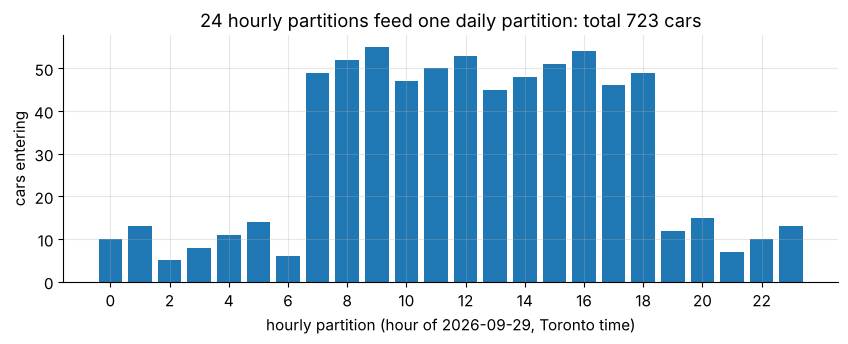

In [44]:
@dg.asset(partitions_def=hourly)
def garage_entries(context: dg.AssetExecutionContext) -> int:
    """Cars entering the garage in one hour (deterministic fake data with a daytime bump)."""
    start = context.partition_time_window.start
    return 5 + 40 * int(7 <= start.hour <= 18) + (start.day * 7 + start.hour * 3) % 11


@dg.asset(partitions_def=dg.DailyPartitionsDefinition(start_date="2026-09-29", end_date="2026-09-30",
                                                      timezone=TZ_NAME))
def garage_daily(context: dg.AssetExecutionContext, garage_entries: dict) -> dict:
    hours = sorted(garage_entries)
    return {"day": context.partition_key, "n_hours": len(hours), "cars": sum(garage_entries.values()),
            "first": hours[0], "last": hours[-1], "per_hour": [garage_entries[h] for h in hours]}


part_inst = dg.DagsterInstance.ephemeral()
t0 = time.perf_counter()
for key in hourly.get_partition_keys():                 # 24 small runs, one per hour
    dg.materialize([garage_entries], partition_key=key, instance=part_inst, run_config=QUIET)
print(f"{len(hourly.get_partition_keys())} hourly runs took {time.perf_counter() - t0:.1f} s")
r = dg.materialize([garage_entries, garage_daily], selection=[garage_daily], partition_key="2026-09-29",
                   instance=part_inst, run_config=QUIET)
day_out = r.output_for_node("garage_daily")
print({k: v for k, v in day_out.items() if k != "per_hour"})

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(24), day_out["per_hour"], color="tab:blue")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hourly partition (hour of 2026-09-29, Toronto time)")
ax.set_ylabel("cars entering")
ax.set_title(f"24 hourly partitions feed one daily partition: total {day_out['cars']} cars")
plt.show()

The daily partition received exactly its 24 hourly partitions (`00:00` to `23:00`) as a
dictionary. (Each hourly run is a full Dagster run with its own run id and events, which is why
24 tiny runs take a few seconds. In production, hourly runs are launched by the scheduler as
separate processes and the overhead is irrelevant.) Other mappings exist: `dg.TimeWindowPartitionMapping(start_offset=-6)` would give a
daily asset the previous six days as well (a rolling window), `dg.AllPartitionMapping()` gives
everything, `dg.StaticPartitionMapping({...})` maps categories, and
`dg.MultiToSingleDimensionPartitionMapping` connects a multi-partitioned asset to a single axis.

### 6.3 Static, multi and dynamic partitions

A multi-partitioned asset is addressed by a `MultiPartitionKey` with one key per dimension. A
dynamic partitions definition starts empty. Keys are added at run time, usually by a sensor
(section 7.3), and are stored in the instance.

In [45]:
@dg.asset(partitions_def=section_days)
def section_day_count(context: dg.AssetExecutionContext) -> int:
    key = context.partition_key.keys_by_dimension            # {"date": ..., "section": ...}
    return len(key["section"]) * int(key["date"][-2:])        # any deterministic toy value


r = dg.materialize([section_day_count], instance=part_inst, run_config=QUIET,
                   partition_key=dg.MultiPartitionKey({"date": "2026-09-29", "section": "sports"}))
print("multi partition value:", r.output_for_node("section_day_count"), "(= len('sports') * 29)")

upload_files = dg.DynamicPartitionsDefinition(name="uploaded_files")


@dg.asset(partitions_def=upload_files)
def upload_size(context: dg.AssetExecutionContext) -> int:
    return len(context.partition_key)


part_inst.add_dynamic_partitions("uploaded_files", ["batch_01.json", "batch_02.json"])
print("dynamic keys now:", part_inst.get_dynamic_partitions("uploaded_files"))
r = dg.materialize([upload_size], partition_key="batch_02.json", instance=part_inst, run_config=QUIET)
print("materialized dynamic partition:", r.success,
      sorted(part_inst.get_materialized_partitions(dg.AssetKey("upload_size"))))

multi partition value: 174 (= len('sports') * 29)
dynamic keys now: ['batch_01.json', 'batch_02.json']
materialized dynamic partition: True ['batch_02.json']


### 6.4 Backfills

A **backfill** materializes a set of partitions, usually a range. In the UI you select a range and
click. In code we have two styles:

* **one run per partition** (the default): simple, retries per day, many small runs
* **one run for the whole range**, when the asset declares `backfill_policy=dg.BackfillPolicy.single_run()`.
  The asset then receives `context.partition_keys` / `context.partition_time_window` covering the
  whole range and can process it in one SQL statement, which is much cheaper for warehouses.

We use the second style below (passing the range through the two run tags the backfill machinery
uses), and check which partitions the instance considers materialized.

In [46]:
SALES_LOG = []


@dg.asset(partitions_def=daily, backfill_policy=dg.BackfillPolicy.single_run())
def daily_sales(context: dg.AssetExecutionContext) -> dg.MaterializeResult:
    window = context.partition_time_window
    SALES_LOG.append((len(context.partition_keys), window.start.date().isoformat(), window.end.date().isoformat()))
    # ... a real asset would run: DELETE + INSERT ... WHERE day >= window.start AND day < window.end
    return dg.MaterializeResult(metadata={"n_partitions": len(context.partition_keys)})


r = dg.materialize([daily_sales], instance=part_inst, run_config=QUIET,
                   tags={"dagster/asset_partition_range_start": "2026-09-23",
                         "dagster/asset_partition_range_end": "2026-09-27"})
print("one run handled (n_keys, window start, window end):", SALES_LOG)
done = sorted(part_inst.get_materialized_partitions(dg.AssetKey("daily_sales")))
print("materialized partitions:", done)
missing = [k for k in daily.get_partition_keys() if k not in done]
print("still missing:", missing)

one run handled (n_keys, window start, window end): [(5, '2026-09-23', '2026-09-28')]
materialized partitions: ['2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26', '2026-09-27']
still missing: ['2026-09-21', '2026-09-22', '2026-09-28', '2026-09-29', '2026-09-30']


One run covered five days (window `[2026-09-23, 2026-09-28)`), yet Dagster tracks the five
partitions individually, so the UI can show exactly which days are still missing.

> **Common pitfall.** Keep the number of partitions per asset reasonable, roughly **at most
> 100,000**. Every partition is tracked in storage, displayed in the UI and considered by the
> scheduler, so millions of tiny partitions make everything slow. Partitions are for *units of
> recomputation*, not for individual records.

In [47]:
for label, minutes in [("5-minute", 5), ("hourly", 60), ("daily", 1440)]:
    for years in (1, 3, 10):
        n = years * 365 * 24 * 60 // minutes
        flag = "too many" if n > 100_000 else "ok"
        print(f"{label:9} partitions over {years:2d} years: {n:>9,}  {flag}")

5-minute  partitions over  1 years:   105,120  too many
5-minute  partitions over  3 years:   315,360  too many
5-minute  partitions over 10 years: 1,051,200  too many
hourly    partitions over  1 years:     8,760  ok
hourly    partitions over  3 years:    26,280  ok
hourly    partitions over 10 years:    87,600  ok
daily     partitions over  1 years:       365  ok
daily     partitions over  3 years:     1,095  ok
daily     partitions over 10 years:     3,650  ok


## 7. Schedules, sensors and declarative automation

In a deployment, the **daemon** evaluates schedules and sensors in a loop and submits the runs they
request. In a notebook (and in tests) we call the same evaluation logic directly with
`build_schedule_context` / `build_sensor_context`. Nothing is launched unless we launch it.

### 7.1 Schedules: cron plus a time zone

`dg.ScheduleDefinition(job=..., cron_schedule=..., execution_timezone=...)` is the real version of
our cron evaluator. Always set `execution_timezone`. Without it the cron expression is interpreted
in UTC. Schedules start **stopped** by default (you switch them on in the UI or with
`default_status=dg.DefaultScheduleStatus.RUNNING`), so deploying code never starts surprise runs.

When the run needs to know *which* tick triggered it (e.g. "process the three hours that just
ended"), use the `@dg.schedule` decorator and build the `RunRequest` yourself from
`context.scheduled_execution_time`.

In [48]:
@dg.asset
def headline_snapshot(config: TopConfig) -> int:
    return config.n


snapshot_job = dg.define_asset_job("snapshot_job", selection=[headline_snapshot])
every_3h = dg.ScheduleDefinition(name="every_3_hours", job=snapshot_job, cron_schedule="0 */3 * * *",
                                 execution_timezone=TZ_NAME)


@dg.schedule(job=snapshot_job, cron_schedule="0 */3 * * *", execution_timezone=TZ_NAME)
def every_3h_with_window(context: dg.ScheduleEvaluationContext):
    end = context.scheduled_execution_time
    start = end - dt.timedelta(hours=3)
    return dg.RunRequest(run_key=end.isoformat(),
                         tags={"window": f"{start:%H:%M}-{end:%H:%M}"},
                         run_config={"ops": {"headline_snapshot": {"config": {"n": end.hour}}}})


tick_time = dt.datetime(2026, 9, 30, 15, 0, tzinfo=TZ)
for sched in (every_3h, every_3h_with_window):
    data = sched.evaluate_tick(dg.build_schedule_context(scheduled_execution_time=tick_time))
    rr = data.run_requests[0]
    print(f"{sched.name:22} cron={sched.cron_schedule!r} tz={sched.execution_timezone} "
          f"default={sched.default_status.value}")
    print(f"{'':22} -> run_key={rr.run_key}, tags={ {k: v for k, v in rr.tags.items() if k == 'window'} }, "
          f"config={rr.run_config}")

every_3_hours          cron='0 */3 * * *' tz=America/Toronto default=STOPPED
                       -> run_key=None, tags={}, config={}
every_3h_with_window   cron='0 */3 * * *' tz=America/Toronto default=STOPPED
                       -> run_key=2026-09-30T15:00:00-04:00, tags={'window': '12:00-15:00'}, config={'ops': {'headline_snapshot': {'config': {'n': 15}}}}


**Our evaluator vs Dagster's on DST nights.** Dagster's cron iterator is an internal function, but
comparing it with our minute-walker from section 3.7 is instructive. For ordinary schedules the
two agree. In the "missing" and "repeated" hours they make different, equally defensible choices:

In [49]:
try:
    from dagster._utils.schedules import cron_string_iterator     # internal; guarded import
except ImportError:
    cron_string_iterator = None


def dagster_next_times(expr, after, n):
    it = cron_string_iterator(after.timestamp(), expr, TZ_NAME)
    return [t.astimezone(TZ) for t in itertools.islice(it, n)]


cases = [("0 */3 * * *", dt.datetime(2026, 10, 31, 20, 0, tzinfo=TZ), 3, "3-hourly, fall-back night"),
         ("30 2 * * *", dt.datetime(2026, 3, 6, 12, 0, tzinfo=TZ), 3, "02:30 daily, spring forward"),
         ("30 1 * * *", dt.datetime(2026, 10, 31, 12, 0, tzinfo=TZ), 3, "01:30 daily, fall back")]
fmt = lambda ts: [f"{t:%m-%d %H:%M %Z}" for t in ts]
for expr, after, n, label in cases:
    print(f"{label}  ({expr})")
    print("   ours   :", fmt(next_fire_times(expr, after, n)))
    if cron_string_iterator is not None:
        print("   dagster:", fmt(dagster_next_times(expr, after, n)))

3-hourly, fall-back night  (0 */3 * * *)
   ours   : ['10-31 21:00 EDT', '11-01 00:00 EDT', '11-01 03:00 EST']
   dagster: ['10-31 21:00 EDT', '11-01 00:00 EDT', '11-01 03:00 EST']
02:30 daily, spring forward  (30 2 * * *)
   ours   : ['03-07 02:30 EST', '03-09 02:30 EDT', '03-10 02:30 EDT']
   dagster: ['03-07 02:30 EST', '03-08 03:00 EDT', '03-09 02:30 EDT']
01:30 daily, fall back  (30 1 * * *)
   ours   : ['11-01 01:30 EDT', '11-01 01:30 EST', '11-02 01:30 EST']
   dagster: ['11-01 01:30 EST', '11-02 01:30 EST', '11-03 01:30 EST']


* **3-hourly across fall back:** identical, and both fire at local 00:00 EDT and 03:00 EST.
* **02:30 on the spring-forward day:** that wall-clock time never happens. Our evaluator simply
  skips the day, because a pure calendar matcher never sees 02:30. (The usual Linux cron daemons,
  Vixie cron and cronie, special-case such clock jumps and run the job right after the change.)
  Dagster runs at 03:00, the first valid time after the gap, so a daily job is never silently lost.
* **01:30 on the fall-back day:** that time happens twice. Our UTC walker fires **twice** (once in
  EDT, once in EST). Dagster fires **once**, at the second occurrence (01:30 EST). For a daily job,
  once is clearly what you want.

This is exactly the kind of edge case a mature orchestrator has already thought about, and why
section 3.7 recommended keeping daily jobs out of the 01:00–03:00 window anyway.

### 7.2 Schedules for partitioned jobs

For partitioned assets, `dg.build_schedule_from_partitioned_job(job, ...)` derives the cron from the
partitions definition and makes each tick request **the partition whose window just closed**. For a
daily partition in Toronto, a tick at 06:15 on September 30 requests partition `2026-09-29`: the
30th is not over yet, so it is not a complete slice.

In [50]:
news_days = dg.DailyPartitionsDefinition(start_date="2026-09-01", timezone=TZ_NAME)


@dg.asset(partitions_def=news_days)
def day_digest(context: dg.AssetExecutionContext) -> str:
    return f"digest for {context.partition_key}"


digest_job = dg.define_asset_job("digest_job", selection=[day_digest])
unresolved = dg.build_schedule_from_partitioned_job(digest_job, hour_of_day=6, minute_of_hour=15)
# The job's partitions are inferred from its assets, so the schedule is "unresolved" until it sits in
# a Definitions object (in a real project that happens automatically when the code location loads).
digest_defs = dg.Definitions(assets=[day_digest], jobs=[digest_job], schedules=[unresolved])
digest_schedule = digest_defs.resolve_schedule_def(unresolved.name)
print("schedule name:", digest_schedule.name)
print("derived cron:", digest_schedule.cron_schedule, "| tz:", digest_schedule.execution_timezone)
for when in [dt.datetime(2026, 9, 30, 6, 15, tzinfo=TZ), dt.datetime(2026, 10, 1, 6, 15, tzinfo=TZ)]:
    data = digest_schedule.evaluate_tick(dg.build_schedule_context(
        instance=part_inst, scheduled_execution_time=when))
    print(f"tick at {when:%Y-%m-%d %H:%M} -> partition {[rr.partition_key for rr in data.run_requests]}")

schedule name: digest_job_schedule
derived cron: 15 6 * * * | tz: America/Toronto
tick at 2026-09-30 06:15 -> partition ['2026-09-29']
tick at 2026-10-01 06:15 -> partition ['2026-09-30']


### ✏️ Exercise 8: which partition does a tick request?

Write `partition_for_tick(tick)` that returns the daily partition key (`"YYYY-MM-DD"`) that a
partitioned daily schedule (time zone `America/Toronto`, `hour_of_day=6`) requests at the aware
datetime `tick`: the **last complete** day before the tick, in Toronto time. Careful: the tick may be
given in another time zone (convert first!).

In [51]:
# ✏️ Exercise 8: partition requested by a daily schedule tick
def partition_for_tick(tick: dt.datetime) -> str:
    """Daily partition key requested by a tick of a daily partitioned schedule in Toronto."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex8():
    assert partition_for_tick(dt.datetime(2026, 9, 30, 6, 0, tzinfo=TZ)) == "2026-09-29"
    assert partition_for_tick(dt.datetime(2027, 1, 1, 6, 0, tzinfo=TZ)) == "2026-12-31", "year boundary"
    utc_tick = dt.datetime(2026, 10, 1, 2, 0, tzinfo=dt.timezone.utc)   # = Sep 30, 22:00 in Toronto
    assert partition_for_tick(utc_tick) == "2026-09-29", "convert to Toronto time before taking the date"
    for when in [dt.datetime(2026, 9, 30, 6, 15, tzinfo=TZ), dt.datetime(2026, 10, 1, 6, 15, tzinfo=TZ)]:
        data = digest_schedule.evaluate_tick(dg.build_schedule_context(instance=part_inst,
                                                                       scheduled_execution_time=when))
        assert partition_for_tick(when) == data.run_requests[0].partition_key, "must agree with Dagster"


run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def partition_for_tick(tick):
    local_day = tick.astimezone(TZ).date()
    return (local_day - dt.timedelta(days=1)).isoformat()
```
The partition for local day $D$ is complete at midnight starting $D+1$, so any tick during day $D+1$
(after midnight) requests $D$. Converting to Toronto time first matters: 02:00 UTC on October 1 is
still September 30 in Toronto.
</details>

### 7.3 Sensors

A Dagster sensor is a function decorated with `@dg.sensor(target=..., minimum_interval_seconds=...)`.
The daemon calls it at most once every `minimum_interval_seconds` (default 30). On each tick it may

* `yield` / return `dg.RunRequest(run_key=..., ...)` objects: one run per request, and the daemon
  **never launches two runs with the same `run_key` for the same sensor**.
* return `dg.SkipReason("...")`: shown in the UI's tick history, very useful for debugging
* read `context.cursor` and call `context.update_cursor(...)` to remember progress between ticks.

Here is the Dagster version of our inbox sensor from section 3.8, watching a folder for JSON files.

In [52]:
INBOX = WORK / "dagster_inbox"
INBOX.mkdir(exist_ok=True)


@dg.asset
def inbox_batch(config: TopConfig) -> int:          # a stand-in target asset for this demo
    return config.n


inbox_job = dg.define_asset_job("inbox_job", selection=[inbox_batch])


@dg.sensor(job=inbox_job, minimum_interval_seconds=60)
def inbox_sensor(context: dg.SensorEvaluationContext):
    last = tuple(json.loads(context.cursor)) if context.cursor else (0.0, "")
    files = sorted((p.stat().st_mtime, p.name) for p in INBOX.glob("*.json"))
    new = [(m, n) for m, n in files if (m, n) > last]
    if not new:
        yield dg.SkipReason(f"no new files after {last[1] or 'the beginning'}")
        return
    for mtime, name in new:
        yield dg.RunRequest(run_key=f"{name}:{mtime:.0f}", tags={"source_file": name})
    context.update_cursor(json.dumps(list(new[-1])))


def sensor_tick(sensor, cursor=None, **kw):
    """Evaluate one tick in-process; return (run keys, skip message, new cursor)."""
    data = sensor.evaluate_tick(dg.build_sensor_context(cursor=cursor, instance=instance, **kw))
    return [rr.run_key for rr in data.run_requests], data.skip_message, data.cursor


keys, skip, cur = sensor_tick(inbox_sensor)
print("tick 1:", keys, "| skip:", skip, "| cursor:", cur)
drop_file(INBOX, "articles_0900.json", ["{}"], T0)
drop_file(INBOX, "articles_1200.json", ["{}"], T0 + 10_800)
keys, skip, cur = sensor_tick(inbox_sensor, cur)
print("tick 2:", keys, "| skip:", skip, "| cursor:", cur)
keys, skip, cur2 = sensor_tick(inbox_sensor, cur)
print("tick 3:", keys, "| skip:", skip)
print("minimum_interval_seconds:", inbox_sensor.minimum_interval_seconds,
      "| default status:", inbox_sensor.default_status.value)

tick 1: [] | skip: no new files after the beginning | cursor: None
tick 2: ['articles_0900.json:1790000000', 'articles_1200.json:1790010800'] | skip: None | cursor: [1790010800.0, "articles_1200.json"]
tick 3: [] | skip: no new files after articles_1200.json
minimum_interval_seconds: 60 | default status: STOPPED


Dagster ships several specialized sensors:

* `@dg.asset_sensor(asset_key=..., job=...)` fires when a given asset gets a new materialization
  (the cursor is the event-log id of the last materialization seen).
* `@dg.run_status_sensor(run_status=...)` and `@dg.run_failure_sensor` react to runs succeeding or
  failing, typically to send a chat message or an e-mail.
* a sensor can also **add dynamic partitions** and request runs for them in one result,
  with `dg.SensorResult(run_requests=[...], dynamic_partitions_requests=[...])`.

Let's see the asset sensor and the dynamic-partition pattern in action.

In [53]:
@dg.asset
def wire_feed() -> list[str]:
    return ["headline a", "headline b"]


@dg.asset
def wire_feed_report(wire_feed: list[str]) -> int:
    return len(wire_feed)


report_job = dg.define_asset_job("wire_report_job", selection=[wire_feed_report])


@dg.asset_sensor(asset_key=dg.AssetKey("wire_feed"), job=report_job)
def wire_feed_updated(context: dg.SensorEvaluationContext, asset_event: dg.EventLogEntry):
    # one run per upstream materialization: the triggering run's id makes a unique run key
    yield dg.RunRequest(run_key=f"wire_feed:{asset_event.run_id[:8]}", tags={"triggered_by": "wire_feed"})


@dg.run_failure_sensor(monitored_jobs=[report_job])
def alert_on_failure(context: dg.RunFailureSensorContext):
    print(f"ALERT: run of {context.dagster_run.job_name} failed")   # would post to chat / e-mail


sensor_defs = dg.Definitions(assets=[wire_feed, wire_feed_report], jobs=[report_job],
                             sensors=[wire_feed_updated, alert_on_failure])
asset_inst = dg.DagsterInstance.ephemeral()
ctx_kw = dict(instance=asset_inst, definitions=sensor_defs)
d = wire_feed_updated.evaluate_tick(dg.build_sensor_context(**ctx_kw))
print("before any materialization:", d.run_requests, "|", d.skip_message)
dg.materialize([wire_feed], instance=asset_inst, run_config=QUIET)
d2 = wire_feed_updated.evaluate_tick(dg.build_sensor_context(cursor=d.cursor, **ctx_kw))
print("after wire_feed materialized:", [(rr.run_key, rr.tags.get("triggered_by")) for rr in d2.run_requests])
d3 = wire_feed_updated.evaluate_tick(dg.build_sensor_context(cursor=d2.cursor, **ctx_kw))
print("next tick:", d3.run_requests, "|", d3.skip_message)
print("failure sensor type:", type(alert_on_failure).__name__)

before any materialization: [] | No new materialization events found for asset key AssetKey(['wire_feed'])


after wire_feed materialized: [('wire_feed:bd6471ee', 'wire_feed')]
next tick: [] | No new materialization events found for asset key AssetKey(['wire_feed'])
failure sensor type: RunStatusSensorDefinition


In [54]:
batch_files = dg.DynamicPartitionsDefinition(name="news_batches")


@dg.asset(partitions_def=batch_files)
def batch_rows(context: dg.AssetExecutionContext) -> int:
    return len(context.partition_key)


batch_job = dg.define_asset_job("batch_job", selection=[batch_rows])


@dg.sensor(job=batch_job)
def batch_sensor(context: dg.SensorEvaluationContext):
    known = set(context.instance.get_dynamic_partitions("news_batches"))
    new = sorted(p.name for p in INBOX.glob("*.json") if p.name not in known)
    if not new:
        return dg.SkipReason("no unknown files")
    return dg.SensorResult(
        run_requests=[dg.RunRequest(partition_key=name, run_key=name) for name in new],
        dynamic_partitions_requests=[batch_files.build_add_request(new)])


dyn_inst = dg.DagsterInstance.ephemeral()
result_obj = batch_sensor(dg.build_sensor_context(instance=dyn_inst))    # direct invocation
print("requested partitions:", [rr.partition_key for rr in result_obj.run_requests])
for req in result_obj.dynamic_partitions_requests:          # what the daemon does with the result:
    dyn_inst.add_dynamic_partitions(req.partitions_def_name, list(req.partition_keys))
for rr in result_obj.run_requests:
    dg.materialize([batch_rows], partition_key=rr.partition_key, instance=dyn_inst, run_config=QUIET)
print("materialized:", sorted(dyn_inst.get_materialized_partitions(dg.AssetKey("batch_rows"))))
print("second tick:", batch_sensor(dg.build_sensor_context(instance=dyn_inst)))

requested partitions: ['articles_0900.json', 'articles_1200.json']


materialized: ['articles_0900.json', 'articles_1200.json']
second tick: SkipReason(skip_message='no unknown files')


Here we called the sensor function **directly** (`batch_sensor(context)`), which returns its raw
result, and then did by hand what the daemon does: register the new partitions, then launch one
run per request. On the second tick both files are known partitions, so the sensor skips.

> **Common pitfall.** A sensor tick must be **fast and side-effect free**: it should *look* at the
> world and *request* runs, never do the heavy processing itself. Ticks have a timeout (60 seconds by
> default), and a tick may be evaluated more than once, which is fine only because run keys make the
> requested runs idempotent.

### 7.4 Declarative automation (briefly)

Schedules and sensors are *imperative*: "at 09:00 run job X". **Declarative automation** lets each
asset state *when it should be updated* and leaves the "how" to Dagster:

* `dg.AutomationCondition.eager()`: update whenever an upstream dependency updates (and none is
  missing or in progress).
* `dg.AutomationCondition.on_cron("0 9 * * *")`: update once per cron tick, after all upstream
  dependencies have updated since that tick.
* `dg.AutomationCondition.on_missing()`: materialize partitions that *become* missing after the
  condition is applied (for example the partition of a new day, or a newly added dynamic
  partition), once their dependencies exist. It does **not** backfill partitions that were already
  missing (for time-partitioned assets only the latest partition is considered). Use a backfill for
  history.

Conditions compose with `&`, `|` and `~`. A daemon sensor evaluates them on every tick. In tests we
call `dg.evaluate_automation_conditions` ourselves, passing the cursor from tick to tick.

In [55]:
@dg.asset
def sensor_upload() -> int:
    return 7


@dg.asset(automation_condition=dg.AutomationCondition.eager())
def upload_summary(sensor_upload: int) -> int:
    return sensor_upload * 2


from concurrent.futures import ThreadPoolExecutor


def evaluate_automation(**kwargs):
    """Call dg.evaluate_automation_conditions from a worker thread.

    The helper starts its own asyncio event loop, which Python forbids inside the event loop that
    Jupyter is already running; a fresh thread has no running loop, so the call works there.
    """
    with ThreadPoolExecutor(max_workers=1) as pool:
        return pool.submit(dg.evaluate_automation_conditions, **kwargs).result()


auto_defs = dg.Definitions(assets=[sensor_upload, upload_summary])
auto_inst = dg.DagsterInstance.ephemeral()
cursor_ = None
for step in ["tick 1 (nothing materialized yet)", "materialize sensor_upload", "tick 2",
             "materialize upload_summary", "tick 3"]:
    if step.startswith("materialize"):
        name = step.split()[1]
        dg.materialize([sensor_upload, upload_summary], selection=[name], instance=auto_inst, run_config=QUIET)
        print(f"{step}")
        continue
    res_ = evaluate_automation(defs=auto_defs, instance=auto_inst, cursor=cursor_)
    cursor_ = res_.cursor
    print(f"{step:36} -> upload_summary requested: {res_.get_num_requested(dg.AssetKey('upload_summary'))}")

tick 1 (nothing materialized yet)    -> upload_summary requested: 0


materialize sensor_upload
tick 2                               -> upload_summary requested: 1


materialize upload_summary
tick 3                               -> upload_summary requested: 0


## 8. Asset checks, testing and the `dg` project layout

### 8.1 Asset checks: data-quality gates

An **asset check** is a function attached to an asset that inspects the materialized data and returns
`dg.AssetCheckResult(passed=..., metadata=..., severity=...)`. Checks run right after their asset,
appear next to it in the UI, and are recorded in the event log, so you get a *history of data
quality*. Two knobs matter:

* `severity`: `ERROR` (default) or `WARN`. A failed WARN check is shown in yellow and alerts nobody
  by default. Use it for "suspicious but tolerable".
* `blocking=True`: if the check fails (with ERROR severity), assets **downstream** of the checked
  asset are not materialized in that run, and the run fails. This is the "stop bad data from
  spreading" gate from section 1.

Example: a table of olympiad training scores with three checks.

In [56]:
def build_score_assets(rows):
    """Asset + checks + a downstream asset, for a given list of rows (so we can feed bad data)."""
    @dg.asset
    def training_scores() -> pd.DataFrame:
        return pd.DataFrame(rows, columns=["student_id", "problem", "points"])

    @dg.asset_check(asset=training_scores, blocking=True, description="points must be within 0..7")
    def points_in_range(training_scores: pd.DataFrame) -> dg.AssetCheckResult:
        bad = int((~training_scores["points"].between(0, 7)).sum())
        return dg.AssetCheckResult(passed=bad == 0, metadata={"out_of_range_rows": bad})

    @dg.asset_check(asset=training_scores, description="one row per (student, problem)")
    def unique_attempts(training_scores: pd.DataFrame) -> dg.AssetCheckResult:
        dup = int(training_scores.duplicated(["student_id", "problem"]).sum())
        return dg.AssetCheckResult(passed=dup == 0, metadata={"duplicate_rows": dup})

    @dg.asset_check(asset=training_scores, description="at least 3 students")
    def enough_students(training_scores: pd.DataFrame) -> dg.AssetCheckResult:
        n = int(training_scores["student_id"].nunique())
        return dg.AssetCheckResult(passed=n >= 3, severity=dg.AssetCheckSeverity.WARN,
                                   metadata={"students": n})

    @dg.asset
    def score_table(training_scores: pd.DataFrame) -> pd.DataFrame:
        return training_scores.pivot_table(index="student_id", columns="problem", values="points",
                                           aggfunc="max", fill_value=0)

    return [training_scores, score_table], [points_in_range, unique_attempts, enough_students]


def run_with_checks(rows, label, verbose=True):
    assets_, checks_ = build_score_assets(rows)
    inst = dg.DagsterInstance.ephemeral()
    r = dg.materialize(assets_ + checks_, instance=inst, run_config=QUIET, raise_on_error=False)
    if not verbose:
        return r
    print(f"--- {label}: run success = {r.success}")
    for ev in sorted(r.get_asset_check_evaluations(), key=lambda e: e.check_name):
        meta = {k: v.value for k, v in ev.metadata.items()}
        print(f"    {ev.check_name:16} passed={str(ev.passed):5} severity={ev.severity.value:5} {meta}")
    done = sorted(e.asset_key.to_user_string() for e in r.get_asset_materialization_events())
    print("    materialized:", done)
    return r


good = [("s1", "P1", 7), ("s1", "P2", 3), ("s2", "P1", 5), ("s3", "P2", 0)]
bad = [("s1", "P1", 7), ("s1", "P1", 7), ("s2", "P1", 12)]
run_with_checks(good, "good data")
_ = run_with_checks(bad, "bad data")

--- good data: run success = True
    enough_students  passed=True  severity=WARN  {'students': 3}
    points_in_range  passed=True  severity=ERROR {'out_of_range_rows': 0}
    unique_attempts  passed=True  severity=ERROR {'duplicate_rows': 0}
    materialized: ['score_table', 'training_scores']


--- bad data: run success = False
    enough_students  passed=False severity=WARN  {'students': 2}
    points_in_range  passed=False severity=ERROR {'out_of_range_rows': 1}
    unique_attempts  passed=False severity=ERROR {'duplicate_rows': 1}
    materialized: ['training_scores']


With good data all three checks pass and both assets are materialized. With bad data:

* `points_in_range` (blocking, ERROR) fails because of the 12, so `score_table` is **not**
  materialized and the run fails, although `training_scores` itself was stored (checks run after
  their asset, exactly as in our toy).
* `unique_attempts` (ERROR, not blocking) fails too and would show red in the UI, but on its own it
  would not have stopped `score_table`.
* `enough_students` only warns: two students are fewer than three.

> **Going deeper.** Checks can also be declared *inside* the asset (`check_specs=[...]` on
> `@dg.asset`, yielding `AssetCheckResult`s from the asset body) when computing them separately would
> mean re-reading a huge table. Dagster also offers ready-made checks, e.g. freshness checks that
> fail when an asset has not been updated within a time limit.

### 8.2 Testing Dagster code

Assets are Python functions, so the cheapest tests call them **directly**. For anything involving
the framework (I/O managers, resources, checks, partitions) use `dg.materialize(...)` in-process,
often with `dg.InMemoryIOManager()` and fake resources. Tests are just functions whose names start
with `test_` and that use plain `assert`. `pytest` would collect them from a `tests/` folder. Here we
run them with a ten-line runner so the notebook needs no extra tools.

In [57]:
def test_shelf_share_direct_call():
    out = shelf_share({"a": 1, "b": 3})                    # direct invocation, no Dagster run
    assert out == {"a": 0.25, "b": 0.75}


def test_best_sellers_with_fake_resources():
    r = dg.materialize(
        [book_sales, best_sellers_usd],
        resources={"io_manager": dg.InMemoryIOManager(), "fx": FxRates(cad_to_usd=1.0),
                   "duckdb": DuckDBResource(database=":memory:")},
        run_config={**QUIET, "ops": {"shop__best_sellers_usd": {"config": {"n": 1}}}},
        instance=dg.DagsterInstance.ephemeral())
    top = r.output_for_node("shop__best_sellers_usd")
    assert r.success and len(top) == 1
    assert top.loc[0, "price_usd"] == top.loc[0, "price_cad"], "rate 1.0 must not change prices"


def test_blocking_check_stops_downstream():
    r = run_with_checks([("s1", "P1", 99)], "inside a test", verbose=False)
    assert not r.success
    assert "score_table" not in {e.asset_key.to_user_string() for e in r.get_asset_materialization_events()}


def run_tests(namespace: dict) -> None:
    """A minimal pytest-style runner: call every test_* function, report pass/fail."""
    tests = [(n, f) for n, f in namespace.items() if n.startswith("test_") and callable(f)]
    failed = 0
    for name, fn in tests:
        try:
            fn()
            print(f"PASSED  {name}")
        except AssertionError as err:
            failed += 1
            print(f"FAILED  {name}: {err}")
    print(f"{len(tests) - failed} passed, {failed} failed")


run_tests({k: v for k, v in globals().items() if k in (
    "test_shelf_share_direct_call", "test_best_sellers_with_fake_resources", "test_blocking_check_stops_downstream")})

PASSED  test_shelf_share_direct_call


PASSED  test_best_sellers_with_fake_resources


PASSED  test_blocking_check_stops_downstream
3 passed, 0 failed


A third, often forgotten test is the cheapest of all: **can the definitions be loaded?**
`dg.Definitions.validate_loadable(defs)` catches missing resources, dependency cycles and jobs that
name an asset key that does not exist (e.g. `selection=["typo"]`) before deployment. It does **not**
flag a selection string that simply matches nothing: `"key:typo"` and `"group:typo"` give an empty
job, so a typo like `"+group:mart"` in `marts_job` would pass silently. Assert the contents of
important jobs in a test (the `resolve` helper of section 5.2 shows how). (`dg check defs` runs the
same kind of check from the command line, by loading the whole project.)

In [58]:
dg.Definitions.validate_loadable(dg.Definitions(assets=[feed_raw, feed_clean, per_topic, per_day, weekly_digest],
                                                jobs=[marts_job]))
print("definitions load fine")
try:
    dg.Definitions.validate_loadable(dg.Definitions(assets=[book_sales, best_sellers_usd]))  # no fx/duckdb
except Exception as err:                                      # noqa: BLE001
    print(f"{type(err).__name__}: {str(err).splitlines()[0][:150]}")

definitions load fine
DagsterInvalidDefinitionError: resource with key 'duckdb' required by op 'shop__best_sellers_usd' was not provided. Please provide a ResourceDefinition to key 'duckdb', or change th


### 8.3 A real project: the `dg` command line and folder layout

Notebooks are great for learning. Real pipelines live in a project folder that Dagster's tools
understand. The `dg` command line (installed with `pip install dagster-dg-cli`, or used through
`uvx`) scaffolds and runs such projects:

```text
$ uvx create-dagster@latest project news-pipeline      # create the project skeleton
$ cd news-pipeline
$ dg scaffold defs dagster.asset assets.py             # new file src/news_pipeline/defs/assets.py
$ dg scaffold defs dagster.schedule schedules.py
$ dg scaffold defs dagster.sensor sensors.py
$ dg check defs                                        # import everything and validate it
$ dg list defs                                         # table of assets, checks, jobs, schedules, sensors
$ dg launch --assets cleaned_articles                  # materialize from the terminal
$ dg launch --assets "key:raw_articles+"               # ... or a selection
$ dg dev                                               # webserver + daemon on http://localhost:3000
```

The resulting layout:

```text
news-pipeline/
├── pyproject.toml          # [tool.dg]         directory_type = "project"
│                           # [tool.dg.project] root_module = "news_pipeline"
├── src/news_pipeline/
│   ├── __init__.py
│   ├── definitions.py      # @dg.definitions  def defs(): return dg.load_from_defs_folder(...)
│   └── defs/               # every module here is scanned for assets, checks, jobs, schedules, ...
│       ├── __init__.py
│       ├── assets.py
│       ├── checks.py
│       ├── resources.py    # @dg.definitions function returning Definitions(resources={...})
│       ├── schedules.py
│       └── sensors.py
└── tests/
    └── test_assets.py      # pytest tests like the ones in section 8.2
```

The idea of the `defs/` folder is *autoloading*: you add a file with an `@dg.asset` in it, and it
appears in the UI without editing a central list. `definitions.py` merges everything into the one
`Definitions` object that the code location server (section 4.1) exposes.

### ✏️ Exercise 9: a Dagster asset with a blocking check

Complete `make_word_assets()`:

* an asset `word_counts` that takes the upstream asset `headlines` (a list of strings) and returns a
  dict mapping each lower-cased word to its number of occurrences (split on whitespace)
* a **blocking** asset check `no_empty_words` on `word_counts` that passes when no key is the empty
  string and every count is positive.

Return the asset and the check. The checker materializes them together with `headlines` and
`top_word` (downstream) on good and on bad input.

In [59]:
# ✏️ Exercise 9: Dagster asset + blocking check
def make_word_assets():
    """Return (word_counts_asset, no_empty_words_check)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex9():
    def run(lines):
        @dg.asset
        def headlines() -> list:
            return lines

        @dg.asset
        def top_word(word_counts: dict) -> str:
            return max(sorted(word_counts), key=word_counts.get)

        word_counts, check = make_word_assets()
        assert isinstance(check, dg.AssetChecksDefinition), "the second item must be an @dg.asset_check"
        return dg.materialize([headlines, word_counts, top_word, check], instance=dg.DagsterInstance.ephemeral(),
                              run_config=QUIET, raise_on_error=False)

    r = run(["Solar Car wins race", "solar panels everywhere"])
    assert r.success, "the good run must succeed"
    assert r.output_for_node("word_counts")["solar"] == 2, "words must be lower-cased"
    assert r.output_for_node("top_word") == "solar"
    evs = r.get_asset_check_evaluations()
    assert len(evs) == 1 and evs[0].passed, "the check must run and pass on good data"
    @dg.asset(name="word_counts")                 # a deliberately broken implementation
    def broken(headlines: list) -> dict:
        return {"": 3}
    _, chk = make_word_assets()
    @dg.asset
    def headlines() -> list:
        return ["x"]
    @dg.asset
    def top_word(word_counts: dict) -> str:
        return "?"
    r2 = dg.materialize([headlines, broken, top_word, chk], instance=dg.DagsterInstance.ephemeral(),
                        run_config=QUIET, raise_on_error=False)
    assert not r2.success, "a failing blocking check must fail the run"
    assert "top_word" not in {e.asset_key.to_user_string() for e in r2.get_asset_materialization_events()}, \
        "the blocking check must stop the downstream asset"


run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def make_word_assets():
    @dg.asset
    def word_counts(headlines: list) -> dict:
        counts = {}
        for line in headlines:
            for word in line.lower().split():
                counts[word] = counts.get(word, 0) + 1
        return counts

    @dg.asset_check(asset="word_counts", blocking=True)
    def no_empty_words(word_counts: dict) -> dg.AssetCheckResult:
        ok = "" not in word_counts and all(c > 0 for c in word_counts.values())
        return dg.AssetCheckResult(passed=ok, metadata={"n_words": len(word_counts)})

    return word_counts, no_empty_words
```
The check refers to the asset by **key** (`asset="word_counts"`), so it attaches to whatever asset
carries that key, which is what lets the checker swap in a deliberately broken `word_counts`.
</details>

## 9. End-to-end project: a multi-category news pipeline

Time to put everything together. We build the pipeline from section 1 properly:

```text
 landing folder (RSS snapshots written by a crawler)          sensor: new snapshot files -> run
           │                                                   schedule: every 3 hours (Toronto)
           ▼
  raw_articles  ──►  cleaned_articles  ──┬──►  category_stats
  (parse XML)        (SQL: trim, drop     └──►  daily_summary
                      empty titles, dedup       (SQL in DuckDB)
                      by URL, parse dates)
                         │
                         ├─ check: not empty            (ERROR, blocking)
                         ├─ check: unique URLs          (ERROR)
                         └─ check: has publish date     (WARN)
```

All tables live in one DuckDB file, accessed through `DuckDBResource`, and the transformations are
written in SQL: the orchestrator decides *when* and *in which order*, and DuckDB does the computing
(section 1's "orchestrator ≠ compute engine").

### 9.1 The data: fictional RSS snapshots with realistic dirt

RSS is an XML format: a `<channel>` containing `<item>`s with `<title>`, `<link>`, `<pubDate>`. Our
fictional newsroom publishes four feeds (science, sports, technology, culture). A crawler saves a
snapshot of a feed every few hours as a file named `<category>_<crawl time>.xml`. The snapshots
contain the kinds of problems real feeds have:

* titles with extra or only **whitespace**, and an item with **no title** at all
* the **same article in two crawls** (same URL, different crawl times), once with a corrected title
* dates in **several formats** (`-0400`, `GMT`, `+0100`, ISO 8601 with `Z`) and some **bad dates**
  (`sometime yesterday`, `30/09/2026`, the impossible `31 Sep`, an empty string).

A flag lets you try real feeds instead (`USE_LIVE_FEEDS = True`). If the network is unavailable the
code falls back to the sample and says so.

In [60]:
from xml.etree import ElementTree as ET
from xml.sax.saxutils import escape

USE_LIVE_FEEDS = False                     # set True to try real RSS feeds (falls back if offline)
LIVE_FEEDS = {                             # public RSS feeds, used only when USE_LIVE_FEEDS is True
    "science": "https://feeds.bbci.co.uk/news/science_and_environment/rss.xml",
    "sports": "https://feeds.bbci.co.uk/sport/rss.xml",
    "technology": "https://feeds.bbci.co.uk/news/technology/rss.xml",
    "culture": "https://feeds.bbci.co.uk/news/entertainment_and_arts/rss.xml",
}
BASE_URL = "https://news.example.org"
NO_TITLE = None                            # marker: the <title> element is missing entirely

SAMPLE_SNAPSHOTS = {   # (category, crawl time in Toronto) -> list of (title, url slug, pubDate text)
    ("science", "2026-09-30T0900"): [
        ("Quantum Dots Light Up Cheaper Solar Panels", "quantum-dots-solar", "Tue, 29 Sep 2026 14:05:00 -0400"),
        ("  Deep-Sea Robot   Maps an Underwater Volcano  ", "deep-sea-robot-volcano", "Tue, 29 Sep 2026 22:40:00 GMT"),
        ("Comet Tail Shows Surprising Water Signature", "comet-water", "Wed, 30 Sep 2026 06:10:00 -0400"),
        (NO_TITLE, "untitled-draft", "Wed, 30 Sep 2026 07:00:00 -0400"),
        ("Bees Learn to Count to Four in New Study", "bees-count", "sometime yesterday"),
    ],
    ("science", "2026-09-30T1200"): [
        ("Quantum Dots Light Up Cheaper Solar Panels", "quantum-dots-solar", "Tue, 29 Sep 2026 14:05:00 -0400"),
        ("Comet Tail Shows a Surprising Water Signature", "comet-water", "Wed, 30 Sep 2026 06:10:00 -0400"),
        ("Tiny Lab-Grown Lenses Could Fix Nearsightedness", "lab-lenses", "2026-09-30T15:20:00Z"),
    ],
    ("sports", "2026-09-30T0900"): [
        ("Harbour City Rowers Break Their Own Record", "rowers-record", "Mon, 28 Sep 2026 19:30:00 -0400"),
        ("Late Goal Sends Northfield Into the Final", "northfield-final", "Tue, 29 Sep 2026 23:55:00 -0400"),
        ("Marathon Route Changes Announced for Spring", "marathon-route", "Wed, 30 Sep 2026 08:15:00 -0400"),
        ("   ", "blank-item", "Wed, 30 Sep 2026 08:20:00 -0400"),
        ("Chess Club Teen Wins Regional Rapid Title", "chess-rapid", "30/09/2026"),
    ],
    ("technology", "2026-09-30T0900"): [
        ("Open-Source Compiler Halves Build Times", "compiler-build-times", "Tue, 29 Sep 2026 10:00:00 -0700"),
        ("City Pilots Bus Stops With E-Ink Timetables", "e-ink-bus-stops", "Tue, 29 Sep 2026 16:45:00 -0400"),
        ("Battery Startup Shows Sodium Cells for Scooters", "sodium-scooters", "Wed, 30 Sep 2026 04:30:00 +0100"),
        ("Students Build a Weather Station From Spare Parts", "student-weather-station", "Thu, 31 Sep 2026 09:00:00 -0400"),
    ],
    ("technology", "2026-09-30T1200"): [
        ("City Pilots Bus Stops With E-Ink Timetables", "e-ink-bus-stops", "Tue, 29 Sep 2026 16:45:00 -0400"),
        ("Translation Earbuds Tested in Busy Markets", "translation-earbuds", "Wed, 30 Sep 2026 11:05:00 -0400"),
    ],
    ("culture", "2026-09-30T0900"): [
        ("Lantern Festival Returns to the Waterfront", "lantern-festival", "Mon, 28 Sep 2026 12:00:00 -0400"),
        ("Museum Opens a Gallery of Mechanical Toys", "mechanical-toys", "Tue, 29 Sep 2026 09:30:00 -0400"),
        ("Poetry Slam Final Draws a Record Crowd", "poetry-slam", ""),
        ("Street Murals Map the Neighbourhood's History", "street-murals", "Wed, 30 Sep 2026 10:10:00 -0400"),
    ],
}


def rss_xml(category: str, items) -> str:
    """Render items as an RSS 2.0 document (an item with title NO_TITLE gets no <title> element)."""
    parts = []
    for title, slug, pub in items:
        title_xml = "" if title is NO_TITLE else f"<title>{escape(title)}</title>"
        parts.append(f"    <item>{title_xml}<link>{BASE_URL}/{category}/{slug}</link>"
                     f"<pubDate>{escape(pub)}</pubDate></item>")
    return ('<?xml version="1.0" encoding="UTF-8"?>\n<rss version="2.0"><channel>\n'
            f"  <title>Example News: {category}</title>\n" + "\n".join(parts) + "\n</channel></rss>\n")


def crawl_mtime(crawl: str) -> float:
    return dt.datetime.strptime(crawl, "%Y-%m-%dT%H%M").replace(tzinfo=TZ).timestamp()


def write_snapshot(folder: Path, category: str, crawl: str, items) -> Path:
    """Save one feed snapshot like a crawler would, with the crawl time as modification time."""
    path = folder / f"{category}_{crawl}.xml"
    path.write_text(rss_xml(category, items), encoding="utf-8")
    os.utime(path, (crawl_mtime(crawl), crawl_mtime(crawl)))
    return path


LANDING = WORK / "news_landing"
LANDING.mkdir(exist_ok=True)
for (category, crawl), items in SAMPLE_SNAPSHOTS.items():
    write_snapshot(LANDING, category, crawl, items)
print(sorted(p.name for p in LANDING.glob("*.xml")))
print((LANDING / "sports_2026-09-30T0900.xml").read_text()[:520])

['culture_2026-09-30T0900.xml', 'science_2026-09-30T0900.xml', 'science_2026-09-30T1200.xml', 'sports_2026-09-30T0900.xml', 'technology_2026-09-30T0900.xml', 'technology_2026-09-30T1200.xml']
<?xml version="1.0" encoding="UTF-8"?>
<rss version="2.0"><channel>
  <title>Example News: sports</title>
    <item><title>Harbour City Rowers Break Their Own Record</title><link>https://news.example.org/sports/rowers-record</link><pubDate>Mon, 28 Sep 2026 19:30:00 -0400</pubDate></item>
    <item><title>Late Goal Sends Northfield Into the Final</title><link>https://news.example.org/sports/northfield-final</link><pubDate>Tue, 29 Sep 2026 23:55:00 -0400</pubDate></item>
    <item><title>Marathon Route Changes Announ


Parsing is a pure function from a folder of snapshots to a DataFrame: one row per `<item>`, keeping
the raw text (cleaning is the next asset's job, so the raw table is an honest copy of what we
received). The crawl time comes from the file name.

In [61]:
def parse_snapshot(path: Path, max_items: int = 1000) -> list[dict]:
    category, crawl = path.stem.split("_", 1)
    root = ET.fromstring(path.read_text(encoding="utf-8"))
    rows = []
    for item in root.iter("item"):
        rows.append({"category": category,
                     "title": item.findtext("title"),            # None if the element is missing
                     "url": item.findtext("link"),
                     "published_raw": item.findtext("pubDate"),
                     "crawled_at": dt.datetime.strptime(crawl, "%Y-%m-%dT%H%M").replace(tzinfo=TZ),
                     "source_file": path.name})
        if len(rows) >= max_items:
            break
    return rows


def parse_landing(folder: Path, max_items: int = 1000) -> pd.DataFrame:
    rows = [r for p in sorted(folder.glob("*.xml")) for r in parse_snapshot(p, max_items)]
    cols = ["category", "title", "url", "published_raw", "crawled_at", "source_file"]
    return pd.DataFrame(rows, columns=cols)


def fetch_live_feeds(folder: Path, timeout: float = 8.0) -> int:
    """Download the live feeds into `folder` as snapshots; return how many feeds succeeded."""
    import urllib.request
    crawl = dt.datetime.now(TZ).strftime("%Y-%m-%dT%H%M")
    ok = 0
    for category, url in LIVE_FEEDS.items():
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "ai-foundations-notebook/1.0"})
            with urllib.request.urlopen(req, timeout=timeout) as resp:
                text = resp.read().decode("utf-8", errors="replace")
            ET.fromstring(text)                                    # must be valid XML
            (folder / f"{category}_{crawl}.xml").write_text(text, encoding="utf-8")
            ok += 1
        except Exception as err:                                  # noqa: BLE001 - any failure -> fallback
            print(f"live feed {category!r} unavailable ({type(err).__name__}); using the sample instead")
    return ok


raw_preview = parse_landing(LANDING)
print(raw_preview.shape, "| rows per file:", raw_preview["source_file"].value_counts().sort_index().tolist())
raw_preview.head(6)

(23, 6) | rows per file: [4, 5, 3, 5, 4, 2]


,category,title,url,published_raw,crawled_at,source_file
0,culture,Lantern Festival Returns to the Wate...,https://news.example.org/culture/lan...,"Mon, 28 Sep 2026 12:00:00 -0400",2026-09-30 09:00:00-04:00,culture_2026-09-30T0900.xml
1,culture,Museum Opens a Gallery of Mechanical...,https://news.example.org/culture/mec...,"Tue, 29 Sep 2026 09:30:00 -0400",2026-09-30 09:00:00-04:00,culture_2026-09-30T0900.xml
2,culture,Poetry Slam Final Draws a Record Crowd,https://news.example.org/culture/poe...,,2026-09-30 09:00:00-04:00,culture_2026-09-30T0900.xml
3,culture,Street Murals Map the Neighbourhood'...,https://news.example.org/culture/str...,"Wed, 30 Sep 2026 10:10:00 -0400",2026-09-30 09:00:00-04:00,culture_2026-09-30T0900.xml
4,science,Quantum Dots Light Up Cheaper Solar ...,https://news.example.org/science/qua...,"Tue, 29 Sep 2026 14:05:00 -0400",2026-09-30 09:00:00-04:00,science_2026-09-30T0900.xml
5,science,Deep-Sea Robot Maps an Underwate...,https://news.example.org/science/dee...,"Tue, 29 Sep 2026 22:40:00 GMT",2026-09-30 09:00:00-04:00,science_2026-09-30T0900.xml


### 9.2 The assets

* `raw_articles` (Python): parse every snapshot in the landing folder (after optionally fetching
  live feeds) and replace the DuckDB table `raw_articles` with the result. Its run config chooses the
  source and the folder. The table is created with an **explicit schema** (`RAW_SCHEMA`), a small
  *data contract*: if a crawl ever yields zero rows, pandas cannot infer column types, and without
  the contract the SQL downstream would crash instead of the quality check failing cleanly. (The
  test in section 9.7 caught exactly this bug in the first version of this notebook.)
* `cleaned_articles` (SQL): normalize whitespace, drop empty titles, keep the **latest crawl** of
  each URL, and parse the publication date from three formats (unparseable dates become `NULL`).
* `category_stats` and `daily_summary` (SQL): the two marts.

The SQL deserves a closer look:

* `regexp_replace(title, '\s+', ' ', 'g')` collapses runs of whitespace and `trim` removes the ends.
  `NULLIF(..., '')` turns an empty result into `NULL`, so "missing title" and "blank title" become
  the same thing.
* `ROW_NUMBER() OVER (PARTITION BY url ORDER BY crawled_at DESC)` numbers the copies of each URL
  from newest to oldest, and keeping `rn = 1` keeps the latest crawl. (DuckDB also allows the shorter
  `QUALIFY rn = 1`.)
* `TRY_STRPTIME` returns `NULL` instead of failing on a bad date, and `COALESCE` takes the first format
  that works. `%z` parses offsets like `-0400`. The ISO form ending in `Z` (UTC) is handled by
  replacing `Z` with `+00:00`.
* The day of an article is its date **in Toronto**: `(published_at AT TIME ZONE 'America/Toronto')::DATE`.
  A story published at 23:55 EDT on September 29 belongs to September 29 locally, although it is
  already September 30 in UTC.

In [62]:
NEWS_DB = WORK / "news.duckdb"


class NewsConfig(dg.Config):
    source: str = "sample"                  # "sample" or "live"
    landing_dir: str = str(LANDING)
    max_items_per_feed: int = 100


RAW_SCHEMA = """CREATE OR REPLACE TABLE raw_articles (
    category VARCHAR, title VARCHAR, url VARCHAR, published_raw VARCHAR,
    crawled_at TIMESTAMPTZ, source_file VARCHAR)"""


def table_preview(conn, table: str, n: int = 5) -> dg.MetadataValue:
    return dg.MetadataValue.md(md_table(conn.execute(f"SELECT * FROM {table} LIMIT {n}").df()))


@dg.asset(group_name="news_ingestion", kinds={"python", "duckdb"})
def raw_articles(context: dg.AssetExecutionContext, config: NewsConfig,
                 duckdb: DuckDBResource) -> dg.MaterializeResult:
    """Every <item> of every snapshot in the landing folder, unmodified."""
    folder = Path(config.landing_dir)
    source_used = "sample"
    if config.source == "live":
        n_ok = fetch_live_feeds(folder)
        source_used = "live" if n_ok else "sample (live feeds unavailable)"
        context.log.info(f"live feeds fetched: {n_ok}")
    df = parse_landing(folder, config.max_items_per_feed)
    with duckdb.get_connection() as conn:
        conn.execute(RAW_SCHEMA)                       # explicit column types, even for 0 rows
        if len(df):
            conn.register("raw_df", df)
            conn.execute("INSERT INTO raw_articles SELECT * FROM raw_df")
            conn.unregister("raw_df")
    return dg.MaterializeResult(metadata={
        "dagster/row_count": len(df), "files": df["source_file"].nunique() if len(df) else 0,
        "source_used": source_used})


CLEAN_SQL = r"""
CREATE OR REPLACE TABLE cleaned_articles AS
WITH normalized AS (
    SELECT
        lower(trim(category))                                         AS category,
        NULLIF(trim(regexp_replace(coalesce(title, ''), '\s+', ' ', 'g')), '') AS title,
        trim(url)                                                     AS url,
        COALESCE(
            TRY_STRPTIME(trim(published_raw), '%a, %d %b %Y %H:%M:%S %z'),
            TRY_STRPTIME(trim(published_raw), '%a, %d %b %Y %H:%M:%S %Z'),
            TRY_STRPTIME(replace(trim(published_raw), 'Z', '+00:00'), '%Y-%m-%dT%H:%M:%S%z')
        )                                                             AS published_at,
        crawled_at
    FROM raw_articles
),
ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY url ORDER BY crawled_at DESC) AS rn
    FROM normalized
    WHERE title IS NOT NULL
)
SELECT category, title, url, published_at, crawled_at
FROM ranked
WHERE rn = 1
ORDER BY category, published_at NULLS LAST, url
"""


@dg.asset(deps=[raw_articles], group_name="news_staging", kinds={"sql", "duckdb"})
def cleaned_articles(duckdb: DuckDBResource) -> dg.MaterializeResult:
    with duckdb.get_connection() as conn:
        conn.execute(f"SET TimeZone = '{TZ_NAME}'")
        conn.execute(CLEAN_SQL)
        n_raw = conn.execute("SELECT count(*) FROM raw_articles").fetchone()[0]
        n_clean, n_dated = conn.execute(
            "SELECT count(*), count(published_at) FROM cleaned_articles").fetchone()
        preview = table_preview(conn, "cleaned_articles")
    return dg.MaterializeResult(metadata={"dagster/row_count": n_clean, "raw_rows": n_raw,
                                          "rows_removed": n_raw - n_clean, "rows_with_date": n_dated,
                                          "preview": preview})


@dg.asset(deps=[cleaned_articles], group_name="news_marts", kinds={"sql", "duckdb"})
def category_stats(duckdb: DuckDBResource) -> dg.MaterializeResult:
    with duckdb.get_connection() as conn:
        conn.execute(f"SET TimeZone = '{TZ_NAME}'")
        conn.execute("""
            CREATE OR REPLACE TABLE category_stats AS
            SELECT category,
                   count(*)                                          AS articles,
                   count(published_at)                               AS with_date,
                   round(avg(len(string_split(title, ' '))), 2)      AS avg_title_words,
                   max(published_at)                                 AS latest_published
            FROM cleaned_articles
            GROUP BY category
            ORDER BY articles DESC, category""")
        n = conn.execute("SELECT count(*) FROM category_stats").fetchone()[0]
        preview = table_preview(conn, "category_stats")
    return dg.MaterializeResult(metadata={"dagster/row_count": n, "preview": preview})


@dg.asset(deps=[cleaned_articles], group_name="news_marts", kinds={"sql", "duckdb"})
def daily_summary(duckdb: DuckDBResource) -> dg.MaterializeResult:
    with duckdb.get_connection() as conn:
        conn.execute(f"SET TimeZone = '{TZ_NAME}'")
        conn.execute(f"""
            CREATE OR REPLACE TABLE daily_summary AS
            WITH per_day AS (
                SELECT (published_at AT TIME ZONE '{TZ_NAME}')::DATE AS day, category, count(*) AS n
                FROM cleaned_articles
                WHERE published_at IS NOT NULL
                GROUP BY 1, 2
            )
            SELECT day,
                   sum(n)::INTEGER                                  AS articles,
                   count(*)::INTEGER                                AS categories,
                   first(category ORDER BY n DESC, category)        AS top_category
            FROM per_day
            GROUP BY day
            ORDER BY day""")
        n = conn.execute("SELECT count(*) FROM daily_summary").fetchone()[0]
        preview = table_preview(conn, "daily_summary")
    return dg.MaterializeResult(metadata={"dagster/row_count": n, "preview": preview})

### 9.3 The checks

Three checks guard `cleaned_articles`, matching three levels of seriousness:

| Check | Severity | Blocking | Why |
|---|---|---|---|
| `cleaned_not_empty` | ERROR | yes | an empty table means the feeds or the parser broke: never overwrite the marts with nothing |
| `unique_urls` | ERROR | no | duplicates would double-count articles, which shows red in the UI, but the marts are still useful |
| `has_publish_date` | WARN | no | some feeds omit or garble dates, which is worth watching, not worth stopping |


In [63]:
def scalar(duckdb_resource: DuckDBResource, sql: str):
    with duckdb_resource.get_connection() as conn:
        return conn.execute(sql).fetchone()[0]


@dg.asset_check(asset=cleaned_articles, blocking=True, description="cleaned_articles has at least one row")
def cleaned_not_empty(duckdb: DuckDBResource) -> dg.AssetCheckResult:
    n = scalar(duckdb, "SELECT count(*) FROM cleaned_articles")
    return dg.AssetCheckResult(passed=n > 0, metadata={"rows": n})


@dg.asset_check(asset=cleaned_articles, description="every URL appears once")
def unique_urls(duckdb: DuckDBResource) -> dg.AssetCheckResult:
    dup = scalar(duckdb, "SELECT count(*) - count(DISTINCT url) FROM cleaned_articles")
    return dg.AssetCheckResult(passed=dup == 0, metadata={"duplicate_urls": dup})


@dg.asset_check(asset=cleaned_articles, description="articles have a parseable publish date")
def has_publish_date(duckdb: DuckDBResource) -> dg.AssetCheckResult:
    missing = scalar(duckdb, "SELECT count(*) - count(published_at) FROM cleaned_articles")
    total = scalar(duckdb, "SELECT count(*) FROM cleaned_articles")
    return dg.AssetCheckResult(passed=missing == 0, severity=dg.AssetCheckSeverity.WARN,
                               metadata={"missing_dates": missing,
                                         "share_missing": round(missing / total, 3) if total else 0.0})

### 9.4 Jobs, schedule, sensor, resources: one `Definitions`

The job selects the four assets (their checks come along automatically). The schedule runs it every
three hours, Toronto time. The sensor watches the landing folder and requests **one** run for all
the snapshots that arrived since the last tick (every run re-reads the whole folder anyway, so one
run per file would be wasted work). Its run key is built from the newest file, so a re-evaluated
tick cannot launch a duplicate run.


In [64]:
news_job = dg.define_asset_job("news_job", selection=[raw_articles, cleaned_articles, category_stats, daily_summary])

news_every_3h = dg.ScheduleDefinition(name="news_every_3h", job=news_job, cron_schedule="0 */3 * * *",
                                      execution_timezone=TZ_NAME)


@dg.sensor(job=news_job, minimum_interval_seconds=120)
def landing_sensor(context: dg.SensorEvaluationContext):
    last = tuple(json.loads(context.cursor)) if context.cursor else (0.0, "")
    files = sorted((p.stat().st_mtime, p.name) for p in LANDING.glob("*.xml"))
    new = [(m, n) for m, n in files if (m, n) > last]
    if not new:
        return dg.SkipReason("no new snapshots in the landing folder")
    newest_mtime, newest_name = new[-1]
    context.update_cursor(json.dumps([newest_mtime, newest_name]))
    return dg.RunRequest(run_key=f"landing:{newest_name}:{newest_mtime:.0f}",
                         tags={"new_snapshots": str(len(new))})


news_defs = dg.Definitions(
    assets=[raw_articles, cleaned_articles, category_stats, daily_summary],
    asset_checks=[cleaned_not_empty, unique_urls, has_publish_date],
    jobs=[news_job], schedules=[news_every_3h], sensors=[landing_sensor],
    resources={"duckdb": DuckDBResource(database=str(NEWS_DB))},
)
dg.Definitions.validate_loadable(news_defs)
news_graph = news_defs.resolve_asset_graph()
print("assets :", [k.to_user_string() for k in news_graph.toposorted_asset_keys])
print("checks :", sorted(k.name for k in news_graph.asset_check_keys))
print("levels :", [[k.to_user_string() for k in lvl] for lvl in news_graph.toposorted_asset_keys_by_level])

assets : ['raw_articles', 'cleaned_articles', 'category_stats', 'daily_summary']
checks : ['cleaned_not_empty', 'has_publish_date', 'unique_urls']
levels : [['raw_articles'], ['cleaned_articles'], ['category_stats', 'daily_summary']]


### 9.5 Run it

We execute the job in-process with explicit run config (the same dictionary you would type into the
UI's launchpad), then read the check results and the materialization metadata.

In [65]:
news_inst = dg.DagsterInstance.ephemeral()
news_run_config = {**QUIET, "ops": {"raw_articles": {"config": {"source": "live" if USE_LIVE_FEEDS else "sample",
                                                                "landing_dir": str(LANDING)}}}}
run1 = news_defs.resolve_job_def("news_job").execute_in_process(run_config=news_run_config, instance=news_inst)
print("run success:", run1.success)
for ev in run1.get_asset_materialization_events():
    m = ev.event_specific_data.materialization
    keep = ("dagster/row_count", "raw_rows", "rows_removed", "rows_with_date", "files", "source_used")
    print(f"  {m.asset_key.to_user_string():18}", {k: m.metadata[k].value for k in keep if k in m.metadata})
for ev in sorted(run1.get_asset_check_evaluations(), key=lambda e: e.check_name):
    print(f"  check {ev.check_name:18} passed={str(ev.passed):5} severity={ev.severity.value:5}",
          {k: v.value for k, v in ev.metadata.items()})

run success: True
  raw_articles       {'dagster/row_count': 23, 'files': 6, 'source_used': 'sample'}
  cleaned_articles   {'dagster/row_count': 18, 'raw_rows': 23, 'rows_removed': 5, 'rows_with_date': 14}
  category_stats     {'dagster/row_count': 4}
  daily_summary      {'dagster/row_count': 3}
  check cleaned_not_empty  passed=True  severity=ERROR {'rows': 18}
  check has_publish_date   passed=False severity=WARN  {'missing_dates': 4, 'share_missing': 0.222}
  check unique_urls        passed=True  severity=ERROR {'duplicate_urls': 0}


Let's open the warehouse and look at the final tables, plus an audit of what the cleaning step
removed and why.

In [66]:
def news_query(sql: str) -> pd.DataFrame:
    with duckdb.connect(str(NEWS_DB), read_only=True) as con:
        con.execute(f"SET TimeZone = '{TZ_NAME}'")
        return con.execute(sql).df()


print("category_stats")
display(news_query("SELECT * FROM category_stats"))
print("daily_summary")
display(news_query("SELECT * FROM daily_summary"))

category_stats


,category,articles,with_date,avg_title_words,latest_published
0,science,5,4,7.00,2026-09-30 11:20:00-04:00
1,technology,5,4,6.60,2026-09-30 11:05:00-04:00
2,culture,4,3,6.50,2026-09-30 10:10:00-04:00
3,sports,4,3,6.75,2026-09-30 08:15:00-04:00


daily_summary


,day,articles,categories,top_category
0,2026-09-28,2,2,culture
1,2026-09-29,7,4,technology
2,2026-09-30,5,4,science


In [67]:
audit = news_query(r"""
    SELECT r.category, coalesce(r.title, '<no title>') AS raw_title, r.published_raw,
           strftime(r.crawled_at, '%H:%M') AS crawl,
           CASE WHEN NULLIF(trim(coalesce(r.title, '')), '') IS NULL THEN 'dropped: empty title'
                WHEN c.crawled_at <> r.crawled_at THEN 'dropped: older crawl of same URL'
                WHEN c.published_at IS NULL THEN 'kept, date unparseable -> NULL'
                ELSE 'kept' END AS outcome
    FROM raw_articles r LEFT JOIN cleaned_articles c USING (url)
    ORDER BY outcome, r.category""")
print(audit["outcome"].value_counts().to_string())
audit[audit["outcome"] != "kept"]

outcome
kept                                14
kept, date unparseable -> NULL       4
dropped: older crawl of same URL     3
dropped: empty title                 2


,category,raw_title,published_raw,crawl,outcome
0,science,<no title>,"Wed, 30 Sep 2026 07:00:00 -0400",09:00,dropped: empty title
1,sports,,"Wed, 30 Sep 2026 08:20:00 -0400",09:00,dropped: empty title
2,science,Quantum Dots Light Up Cheaper Solar ...,"Tue, 29 Sep 2026 14:05:00 -0400",09:00,dropped: older crawl of same URL
3,science,Comet Tail Shows Surprising Water Si...,"Wed, 30 Sep 2026 06:10:00 -0400",09:00,dropped: older crawl of same URL
4,technology,City Pilots Bus Stops With E-Ink Tim...,"Tue, 29 Sep 2026 16:45:00 -0400",09:00,dropped: older crawl of same URL
19,culture,Poetry Slam Final Draws a Record Crowd,,09:00,"kept, date unparseable -> NULL"
20,science,Bees Learn to Count to Four in New S...,sometime yesterday,09:00,"kept, date unparseable -> NULL"
21,sports,Chess Club Teen Wins Regional Rapid ...,30/09/2026,09:00,"kept, date unparseable -> NULL"
22,technology,Students Build a Weather Station Fro...,"Thu, 31 Sep 2026 09:00:00 -0400",09:00,"kept, date unparseable -> NULL"


The audit accounts for every one of the 23 raw rows: 14 kept with a date, 4 kept without one
(`sometime yesterday`, `30/09/2026`, the impossible `31 Sep`, and the empty string), 2 dropped for an
empty title (the missing `<title>` and the whitespace-only one), and 3 dropped as older crawls of a
URL seen again at 12:00. For the comet story, the kept row is the 12:00 crawl with the corrected
title "Comet Tail Shows **a** Surprising Water Signature".

In `daily_summary`, September 29 has 7 articles with technology on top (3). Two of those are
instructive: the sodium-battery story was stamped `Wed, 30 Sep 2026 04:30:00 +0100`, which is
23:30 on **September 29** in Toronto, and the Northfield match report (23:55 EDT on the 29th) would
land on the 30th if we had grouped by UTC date. Choosing the time zone of a "day" is a business
decision. Making it explicit in SQL is good engineering.

> **Common pitfall.** We dropped empty titles **before** deduplicating. Had we deduplicated first,
> a URL whose newest crawl had a blank title would have lost its good older version too. The order
> of cleaning steps is part of the logic, so write it down (and test it, section 9.7).

### 9.6 The schedule and the sensor in action

The schedule's next ticks (and what Dagster would request at one of them):


In [68]:
now_ = dt.datetime(2026, 9, 30, 13, 20, tzinfo=TZ)
print("next ticks of news_every_3h after", f"{now_:%Y-%m-%d %H:%M %Z}:")
print(*["   " + s for s in show_times(next_fire_times(news_every_3h.cron_schedule, now_, n=4))], sep="\n")
tick = news_every_3h.evaluate_tick(dg.build_schedule_context(
    instance=news_inst, scheduled_execution_time=dt.datetime(2026, 9, 30, 15, 0, tzinfo=TZ)))
print(f"tick at 15:00 -> {len(tick.run_requests)} run request for job {news_every_3h.job_name!r}, "
      f"tags {dict(tick.run_requests[0].tags)}")

next ticks of news_every_3h after 2026-09-30 13:20 EDT:
   Wed 2026-09-30 15:00 EDT (19:00 UTC)
   Wed 2026-09-30 18:00 EDT (22:00 UTC)
   Wed 2026-09-30 21:00 EDT (01:00 UTC)
   Thu 2026-10-01 00:00 EDT (04:00 UTC)
tick at 15:00 -> 1 run request for job 'news_job', tags {'dagster/schedule_name': 'news_every_3h'}


Now the sensor. The first tick sees the six snapshots and requests one run. A crawler then drops a
new culture snapshot at 15:00 with one new story and one story we already have. The next tick
requests a second run, which we launch, and the marts update.


tick 1: [('landing:technology_2026-09-30T1200.xml:1790784000', '6')] | cursor: [1790784000.0, "technology_2026-09-30T1200.xml"]
tick 2: [] | no new snapshots in the landing folder
tick 3: [('landing:culture_2026-09-30T1500.xml:1790794800', '1')]


run 2 success: True


,day,articles,categories,top_category
0,2026-09-28,2,2,culture
1,2026-09-29,7,4,technology
2,2026-09-30,6,4,culture


  category  articles  with_date
0  culture         5          4


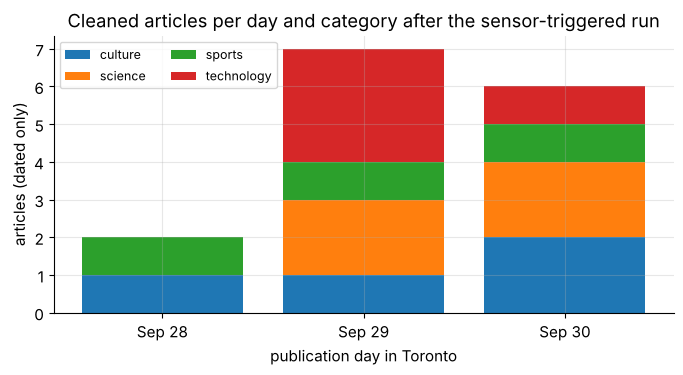

In [69]:
def news_sensor_tick(cursor):
    data = landing_sensor.evaluate_tick(dg.build_sensor_context(cursor=cursor, instance=news_inst))
    return data


t1 = news_sensor_tick(None)
print("tick 1:", [(rr.run_key, rr.tags["new_snapshots"]) for rr in t1.run_requests], "| cursor:", t1.cursor)
t2 = news_sensor_tick(t1.cursor)
print("tick 2:", t2.run_requests, "|", t2.skip_message)

write_snapshot(LANDING, "culture", "2026-09-30T1500", [
    ("Film Club Restores a Silent Movie Classic", "silent-movie", "Wed, 30 Sep 2026 13:45:00 -0400"),
    ("Museum Opens a Gallery of Mechanical Toys", "mechanical-toys", "Tue, 29 Sep 2026 09:30:00 -0400"),
])
t3 = news_sensor_tick(t2.cursor or t1.cursor)
print("tick 3:", [(rr.run_key, rr.tags["new_snapshots"]) for rr in t3.run_requests])

run2 = news_defs.resolve_job_def("news_job").execute_in_process(
    run_config=news_run_config, instance=news_inst, tags=t3.run_requests[0].tags)
print("run 2 success:", run2.success)
display(news_query("SELECT * FROM daily_summary"))
print(news_query("SELECT category, articles, with_date FROM category_stats WHERE category = 'culture'"))

per_day_cat = news_query(f"""
    SELECT (published_at AT TIME ZONE '{TZ_NAME}')::DATE AS day, category, count(*) AS n
    FROM cleaned_articles WHERE published_at IS NOT NULL GROUP BY ALL""")
pivot = per_day_cat.pivot(index="day", columns="category", values="n").fillna(0).sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
bottom = np.zeros(len(pivot))
for category in sorted(pivot.columns):
    ax.bar([d.strftime("%b %d") for d in pivot.index], pivot[category], bottom=bottom, label=category)
    bottom += pivot[category].to_numpy()
ax.set_ylabel("articles (dated only)"); ax.set_xlabel("publication day in Toronto")
ax.set_title("Cleaned articles per day and category after the sensor-triggered run")
ax.legend(ncols=2, fontsize=9)
plt.show()

The new snapshot added one article (the film club, published September 30 at 13:45), so September 30
now has 6 articles and culture has 5. On the 30th culture now ties science with 2 articles each, and
the tie is broken alphabetically (`ORDER BY n DESC, category`), so culture becomes the top category:
always make tie-breaking explicit, or reruns may flip results at random. The repeated museum story
did **not** create a duplicate: it
collapsed onto its existing URL (keeping the newer 15:00 crawl), and the `unique_urls` check would
have caught it otherwise. Our pipeline is **idempotent**: running it twice on the same landing folder
produces the same tables, which is what makes retries and re-runs safe.

### 9.7 Tests for the project

Two tests in the pytest style of section 8.2. Each one uses its **own** temporary landing folder and
DuckDB file, so tests never touch the real warehouse (a test that writes to production data is a
famous way to ruin a Friday).

* `test_cleaning_rules`: a crafted landing folder with one of each dirty case, and the test checks trimming,
  empty-title removal, "latest crawl wins" and date parsing row by row.
* `test_empty_feed_blocks_marts`: an empty landing folder. The blocking check must fail and the
  marts must not be built.


In [70]:
def materialize_news(landing: Path, db: Path):
    """Run the four news assets and their checks against a private folder and database."""
    return dg.materialize(
        [raw_articles, cleaned_articles, category_stats, daily_summary,
         cleaned_not_empty, unique_urls, has_publish_date],
        resources={"duckdb": DuckDBResource(database=str(db))},
        run_config={**QUIET, "ops": {"raw_articles": {"config": {"landing_dir": str(landing)}}}},
        instance=dg.DagsterInstance.ephemeral(), raise_on_error=False)


def test_cleaning_rules():
    tmp = Path(tempfile.mkdtemp(dir=WORK))
    write_snapshot(tmp, "science", "2026-09-30T0900", [
        ("  Old   Title ", "story-1", "Tue, 29 Sep 2026 14:05:00 -0400"),
        (NO_TITLE, "story-2", "Tue, 29 Sep 2026 15:00:00 -0400"),
        ("Bad Date", "story-3", "yesterday-ish")])
    write_snapshot(tmp, "science", "2026-09-30T1200", [
        ("New Title", "story-1", "Tue, 29 Sep 2026 14:05:00 -0400")])
    r = materialize_news(tmp, tmp / "test.duckdb")
    assert r.success
    with duckdb.connect(str(tmp / "test.duckdb"), read_only=True) as con:
        rows = dict(con.execute("SELECT url, title FROM cleaned_articles").fetchall())
        nulls = con.execute("SELECT count(*) FROM cleaned_articles WHERE published_at IS NULL").fetchone()[0]
    assert rows == {f"{BASE_URL}/science/story-1": "New Title", f"{BASE_URL}/science/story-3": "Bad Date"}, rows
    assert nulls == 1, "the unparseable date must become NULL, not crash the run"


def test_empty_feed_blocks_marts():
    tmp = Path(tempfile.mkdtemp(dir=WORK))
    r = materialize_news(tmp, tmp / "test.duckdb")
    done = {e.asset_key.to_user_string() for e in r.get_asset_materialization_events()}
    failed = {ev.check_name for ev in r.get_asset_check_evaluations() if not ev.passed}
    assert not r.success and "cleaned_not_empty" in failed
    assert done == {"raw_articles", "cleaned_articles"}, f"marts must be skipped, got {done}"


run_tests({"test_cleaning_rules": test_cleaning_rules, "test_empty_feed_blocks_marts": test_empty_feed_blocks_marts})

PASSED  test_cleaning_rules


PASSED  test_empty_feed_blocks_marts
2 passed, 0 failed


### ✏️ Exercise 10: deduplicate with SQL

The table `crawls(url, title, crawled_at)` below holds several crawls of the same URLs. Write a
DuckDB query `DEDUP_SQL` that returns exactly one row per `url`, the one with the **latest**
`crawled_at`, with columns `url, title`, ordered by `url`. Use a window function
(`ROW_NUMBER() OVER (PARTITION BY ... ORDER BY ...)`), or DuckDB's `QUALIFY`, or `arg_max`.

In [71]:
# ✏️ Exercise 10: keep the latest crawl per URL
DEDUP_SQL = """
-- YOUR QUERY HERE
"""


def _test_ex10():
    con = duckdb.connect()
    con.execute("""CREATE TABLE crawls AS SELECT * FROM (VALUES
        ('u1', 'first draft',  TIMESTAMP '2026-09-30 09:00'),
        ('u1', 'final title',  TIMESTAMP '2026-09-30 12:00'),
        ('u2', 'only version', TIMESTAMP '2026-09-30 09:00'),
        ('u3', 'newest',       TIMESTAMP '2026-09-30 15:00'),
        ('u3', 'older',        TIMESTAMP '2026-09-30 06:00'),
        ('u3', 'middle',       TIMESTAMP '2026-09-30 12:00')) t(url, title, crawled_at)""")
    if "YOUR QUERY HERE" in DEDUP_SQL:
        raise NotImplementedError
    got = con.execute(DEDUP_SQL).fetchall()
    assert got == [("u1", "final title"), ("u2", "only version"), ("u3", "newest")], f"got {got}"


run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
DEDUP_SQL = """
SELECT url, title
FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY url ORDER BY crawled_at DESC) AS rn FROM crawls)
WHERE rn = 1
ORDER BY url
"""
# equivalent DuckDB shortcuts:
#   SELECT url, title FROM crawls QUALIFY ROW_NUMBER() OVER (PARTITION BY url ORDER BY crawled_at DESC) = 1 ORDER BY url
#   SELECT url, arg_max(title, crawled_at) AS title FROM crawls GROUP BY url ORDER BY url
```
The window numbers the rows of each URL from newest to oldest without collapsing them, and the
outer filter keeps row 1. A plain `GROUP BY url` with `max(crawled_at)` would find the latest *time*
but not the title that goes with it, and that is exactly what `arg_max` solves.
</details>


## 10. Dagster vs Airflow vs Prefect vs cron

### 10.1 The same pipeline as an Airflow DAG

Apache Airflow is the most widely deployed orchestrator, and reading its code is a useful skill. Here
is our news pipeline written with Airflow's TaskFlow API. It is **not executed** in this notebook
(Airflow is a heavy install with its own scheduler and database), so read it as a translation exercise.

```python
# dags/news_pipeline.py  (Airflow 2.x; in Airflow 3 import dag/task from airflow.sdk)
from datetime import timedelta
import pendulum
from airflow.decorators import dag, task

@dag(
    dag_id="news_pipeline",
    schedule="0 */3 * * *",                                     # every 3 hours ...
    start_date=pendulum.datetime(2026, 9, 1, tz="America/Toronto"),  # ... in Toronto time
    catchup=False,                                              # do not backfill missed intervals
    default_args={"retries": 3, "retry_delay": timedelta(minutes=2),
                  "retry_exponential_backoff": True},
)
def news_pipeline():
    @task
    def load_raw_articles() -> int:
        ...   # parse the landing folder into the raw_articles table, return the row count

    @task
    def clean_articles(n_raw: int) -> int:
        ...   # run CLEAN_SQL, return the number of cleaned rows

    @task
    def check_not_empty(n_clean: int) -> None:
        if n_clean == 0:
            # failing task -> downstream tasks become "upstream_failed" (default trigger rule)
            raise ValueError("cleaned_articles is empty")

    @task
    def build_category_stats() -> None:
        ...

    @task
    def build_daily_summary() -> None:
        ...

    n_clean = clean_articles(load_raw_articles())      # passing values creates edges (via XCom)
    check_not_empty(n_clean) >> [build_category_stats(), build_daily_summary()]

news_pipeline()
```

Line by line it maps well: `@task` ≈ op, `@dag` ≈ job + schedule, `>>` ≈ a dependency edge,
`retries` ≈ `RetryPolicy`, a file sensor (`FileSensor`) ≈ our landing sensor, and the
`catchup` / `airflow dags backfill` machinery ≈ backfills over time intervals. The difference is
the **mental model**: the Airflow DAG describes *tasks to run*, and the tables they produce are invisible to
Airflow unless you declare them separately (Airflow 2.4 added "datasets", renamed **assets** in
Airflow 3, which narrows the gap). In Dagster the tables *are* the nodes, so lineage, staleness and
per-table checks come for free. The quality gate is also telling: in Airflow it is an ordinary task
that raises, while in Dagster it is a *check* attached to the asset with its own history.

### 10.2 Choosing a tool

| | cron + scripts | Airflow | Dagster | Prefect |
|---|---|---|---|---|
| unit of work | a command at a time | task (operator) | **asset** (or op) | task inside a flow |
| dependencies | none (time offsets) | explicit DAG of tasks | DAG of assets, inferred from code | Python control flow, dynamic |
| triggers | clock only | schedules, sensors, data-aware (datasets/assets) | schedules, sensors, declarative automation | schedules, events, deployments |
| data awareness | none | added on top | central: lineage, staleness, metadata, checks | task results, artifacts |
| partitions & backfills | hand-written loops | time intervals, catchup | first-class time/static/multi/dynamic partitions | parameters per run |
| local testing | run the script | needs a scheduler + DB for realism | `materialize()` in-process, as in this notebook | call the flow function |
| typical sweet spot | one small job on one machine | large established task-based platforms, many integrations | analytics & ML data platforms built around tables | Python-first workflows, dynamic task graphs |

There is no universal winner. A single nightly backup is fine with cron. A company with hundreds of
existing Airflow DAGs and operators will not rewrite them for fun. A team building tables, features
and models that must stay fresh, tested and traceable gets the most from an asset-centric tool.

**Quick check 4.** A colleague says: "Dagster replaces DuckDB in our stack." What is wrong with
that sentence?

<details>
<summary>Answer</summary>

They do different jobs. DuckDB is the **compute engine** that executes the SQL, and Dagster is the
**orchestrator** that decides when the SQL runs, in which order, with which configuration, records
what happened and checks the result. Our project uses both: Dagster calls DuckDB through
`DuckDBResource`. Replacing DuckDB would mean choosing another engine (pandas, Spark, a warehouse),
not "using Dagster instead".
</details>


## 11. Quiz

Try each question before opening the answer. Every answer explains why the right option is right
and why each wrong option is wrong.

**Q1.** Which responsibility does an orchestrator **not** have?

A. Running steps in dependency order  B. Retrying a step after a network timeout
C. Making a slow SQL join run faster  D. Recording which code version produced a table

<details>
<summary>Answer</summary>

**C.** Join performance is the compute engine's business (indexes, partitioning, the query planner).
A, B and D are core orchestrator duties: dependency order, retries, and lineage/versioning.
</details>

**Q2.** The DAG has edges `a → b`, `a → c`, `b → d`, `c → d`, `d → e`. Which sequence is **not** a
valid topological order?

A. a, b, c, d, e  B. a, c, b, d, e  C. a, b, d, c, e  D. none of them, since all are valid

<details>
<summary>Answer</summary>

**C.** `d` appears before `c`, but the edge `c → d` requires `c` first. A and B are both valid (the
order of the independent `b` and `c` is free), so D is false.
</details>

**Q3.** Durations: `a` 3, `b` 5, `c` 2, `d` 4, `e` 1 (same graph as Q2). With unlimited workers and
every step starting as soon as its parents finish, when does the pipeline finish?

A. 15  B. 13  C. 10  D. 8

<details>
<summary>Answer</summary>

**B.** EF(a) = 3, EF(b) = 8, EF(c) = 5, EF(d) = 4 + max(8, 5) = 12, EF(e) = 13. The critical path is
a → b → d → e (3 + 5 + 4 + 1 = 13). A (15) is the total work, i.e. one worker. C and D ignore that
`d` must wait for the slower parent `b`.
</details>

**Q4.** In Dagster, asset `prices` has `code_version="v1"` and no custom data versions. You change
its code, bump it to `"v2"`, and re-materialize it. The output is identical. What is the status of
its child `report`?

A. Fresh, because the values are identical  B. Stale, because `prices` got a new data version
C. Missing  D. Stale, because `report`'s own code version changed

<details>
<summary>Answer</summary>

**B.** Default data versions are derived from the code version and the input versions, not from
the content, so `prices` has a new data version and `report` consumed the old one. A would be true
only with content-based data versions (section 4.3). C is wrong (it was materialized before), and
D is wrong (`report`'s code did not change).
</details>

**Q5.** A **blocking** check on `cleaned_articles` fails during a run. What happens?

A. `cleaned_articles` is rolled back to its previous value
B. The run continues and only the UI shows a red mark
C. Assets downstream of `cleaned_articles` are not materialized in this run, and the run fails
D. Dagster retries the check until it passes

<details>
<summary>Answer</summary>

**C.** That is the meaning of `blocking=True`. A is wrong: the check runs *after* the asset, whose
new value has already been stored (section 8.1 showed `training_scores` materialized despite the
failure). B describes a non-blocking ERROR check. D is wrong: checks are not retried automatically,
and re-running would see the same bad data.
</details>

**Q6.** What is the main purpose of a sensor's `run_key`?

A. To make ticks run faster  B. To guarantee that a given request launches at most one run
C. To store the sensor's progress between ticks  D. To choose the job to run

<details>
<summary>Answer</summary>

**B.** Requests with a run key that already launched are dropped, which makes re-evaluated ticks
and lost cursors harmless (section 3.8, tick 5). C describes the **cursor**, which is about
efficiency. A and D are unrelated: speed comes from the cursor and a cheap tick body, and the job is
the sensor's target.
</details>

**Q7.** How many times per week does the cron expression `*/20 8-9 * * 1-5` fire?

A. 6  B. 10  C. 30  D. 42

<details>
<summary>Answer</summary>

**C.** Minutes 0, 20, 40 (3 per hour) × hours 8 and 9 (2 hours) × Monday to Friday (5 days) = 30.
A forgets the weekdays, B forgets the minutes, D counts seven days a week.
</details>

**Q8.** On graph `raw → cleaned → {stats, summary} → report`, which assets does the selection
`key:cleaned+1` pick?

A. cleaned  B. cleaned, stats, summary  C. cleaned, stats, summary, report  D. raw, cleaned

<details>
<summary>Answer</summary>

**B.** `+1` after the key means "and one level downstream". A ignores the `+1`, C is `key:cleaned+`
(all levels), and D would be `1+key:cleaned` (one level *upstream*).
</details>

**Q9.** Users upload experiment files with unpredictable names, and each file must be processed
and tracked separately. Which partitioning fits?

A. `DailyPartitionsDefinition`  B. `StaticPartitionsDefinition`
C. `DynamicPartitionsDefinition`, with a sensor adding keys  D. No partitions, and reprocess everything each time

<details>
<summary>Answer</summary>

**C.** The keys are only known at run time, which is exactly what dynamic partitions are for
(section 7.3). A would lump files by day, B needs the names in advance, and D wastes work and loses
per-file tracking.
</details>

**Q10.** A daily partitioned schedule in `America/Toronto` ticks at 06:15 on October 1. Which
partition does it request?

A. `2026-10-01`  B. `2026-09-30`  C. `2026-09-29`  D. all partitions since the start date

<details>
<summary>Answer</summary>

**B.** It requests the last **complete** day. October 1 is still in progress (A). C is two days back,
and D is a backfill, not a schedule tick.
</details>

**Q11.** What does an I/O manager do?

A. It decides when assets run  B. It stores asset outputs and loads them as inputs downstream
C. It validates run config  D. It renders the UI

<details>
<summary>Answer</summary>

**B.** It separates storage from logic (pickle files, DuckDB tables, a warehouse). A is the job of
schedules, sensors and automation conditions, C is done by `dg.Config` (Pydantic), and D is the
webserver.
</details>

**Q12.** Why did the news pipeline drop empty titles **before** deduplicating by URL?

A. It is faster  B. So that a blank newest crawl cannot hide a good older version of the same URL
C. SQL cannot filter rows after a window function has been computed  D. It makes no difference

<details>
<summary>Answer</summary>

**B.** If deduplication ran first, the newest crawl would win even when its title is blank, and the
subsequent filter would then drop the article entirely. A might be marginally true but is not the
reason. C is false: you can filter before the window (a `WHERE` in the same `SELECT`, as in the
`ranked` CTE) or after it (the outer `WHERE rn = 1`, or DuckDB's `QUALIFY`). D is false, as just
explained.
</details>


## 12. Summary and going further

| Concept | Key point |
|---|---|
| Orchestrator | decides *what, when, in which order, with which config*, and records it, but is not a compute engine |
| DAG, topological order | exists iff the graph is acyclic, Kahn's algorithm in $O(\lvert V\rvert + \lvert E\rvert)$, and cycles found by DFS with gray nodes |
| Levels, critical path | $\mathrm{EF}(v) = d(v) + \max_{u \to v} \mathrm{EF}(u)$, and the makespan is $\ge \max(L_{\text{crit}}, \lceil W/k \rceil)$ |
| Task vs asset | verbs (did it run?) vs nouns (does the table exist, is it up to date?) |
| Missing / stale / fresh | compare code version and input data versions with the last materialization, and content hashes enable early cutoff |
| Ops, jobs, selections | ops for side effects, and `define_asset_job` + selection strings (`key:x+`, `+key:x`, `group:g`, `and/or/not`) |
| Resources vs config | resources = clients per environment, and `dg.Config` = parameters per run |
| I/O managers | storage of asset values, swappable (filesystem, memory, DuckDB, custom) |
| Partitions | time / static / multi / dynamic, mappings (hourly → daily), backfills, and keep ≲ 100k per asset |
| Schedules | cron + `execution_timezone`, partitioned schedules request the last complete window, and beware DST |
| Sensors | cursor (efficiency) + run key (idempotency), `SkipReason`, and fast, side-effect-free ticks |
| Asset checks | ERROR vs WARN, and `blocking=True` stops downstream materializations |
| Testing | direct calls, `dg.materialize` with fake resources, `validate_loadable`, private folders/databases |

**Going further**

* Dagster documentation: [Assets](https://docs.dagster.io/guides/build/assets),
  [Partitions and backfills](https://docs.dagster.io/guides/build/partitions-and-backfills),
  [Schedules](https://docs.dagster.io/guides/automate/schedules),
  [Sensors](https://docs.dagster.io/guides/automate/sensors),
  [Asset checks](https://docs.dagster.io/guides/test/asset-checks),
  [Declarative automation](https://docs.dagster.io/guides/automate/declarative-automation),
  [I/O managers](https://docs.dagster.io/guides/build/io-managers),
  [Projects and the dg CLI](https://docs.dagster.io/guides/build/projects),
  [OSS deployment architecture](https://docs.dagster.io/deployment/oss/oss-deployment-architecture).
* [Apache Airflow documentation](https://airflow.apache.org/docs/apache-airflow/stable/index.html) and
  [Prefect documentation](https://docs.prefect.io/), to compare the task-centric designs.
* [DuckDB documentation](https://duckdb.org/docs/), especially window functions and time zones.
* A. B. Kahn, "Topological sorting of large networks", *Communications of the ACM*, 1962: the
  algorithm of section 2.2.
* R. L. Graham, "Bounds on multiprocessing timing anomalies", *SIAM Journal on Applied Mathematics*,
  1969: the $2 - 1/k$ guarantee for list scheduling.
* A. Mokhov, N. Mitchell, S. Peyton Jones, "Build Systems à la Carte", ICFP 2018: build systems,
  early cutoff and minimal rebuilds, the theory behind section 3.5.
* [The crontab(5) manual page](https://man7.org/linux/man-pages/man5/crontab.5.html) and the
  [RSS 2.0 specification](https://www.rssboard.org/rss-specification).

**Where this leads.** The next notebooks load and transform tabular data with pandas, then train
models. Every one of those steps can become an asset: `raw_data → features → model → evaluation`,
with checks on data quality and model metrics, partitions per day of data, and a schedule that keeps
the model fresh. Orchestration is what turns a notebook experiment into a system that keeps working.
